Mounted at /content/drive
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 82.8/82.8 kB 4.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 220.7/220.7 kB 15.6 MB/s eta 0:00:00
  GraviLens v9 — Benchmark: GraviLens | Lensformer | LensPINN-Small
                             ViT | CaiT | ViTSD
  Convergence fixes: scheduler timing, warmup, accumulation,
  clip factor, label smoothing, augmentation onset

  Device: cuda
  GPU:    Tesla T4
  VRAM:   15.6 GB

  LOADING DATASET
  Train: 7000 | Val: 1500 | Test: 1500
  Image: (64, 64) | Classes: 2

  Precomputing distortion maps (Lensformer / LensPINN)...
  Distortion maps: (7000, 64, 64)  [mean=0.6639, std=0.3788]
  Done.

  MODEL 1/6 — GraviLens  [PINN]
  GraviLens config:
    Image 64x64, Patches 8x8 (64 total)
    embed_dim=192, heads=8, blocks=4, window=4
  Total trainable parameters: 4,775,173 (4.78M)
  Trial 'gravilens-v9-benchmark' found (status: completed, last saved epoch: 49) — resuming.
  [v9] Epoch-0 starting LR: 1.00e-

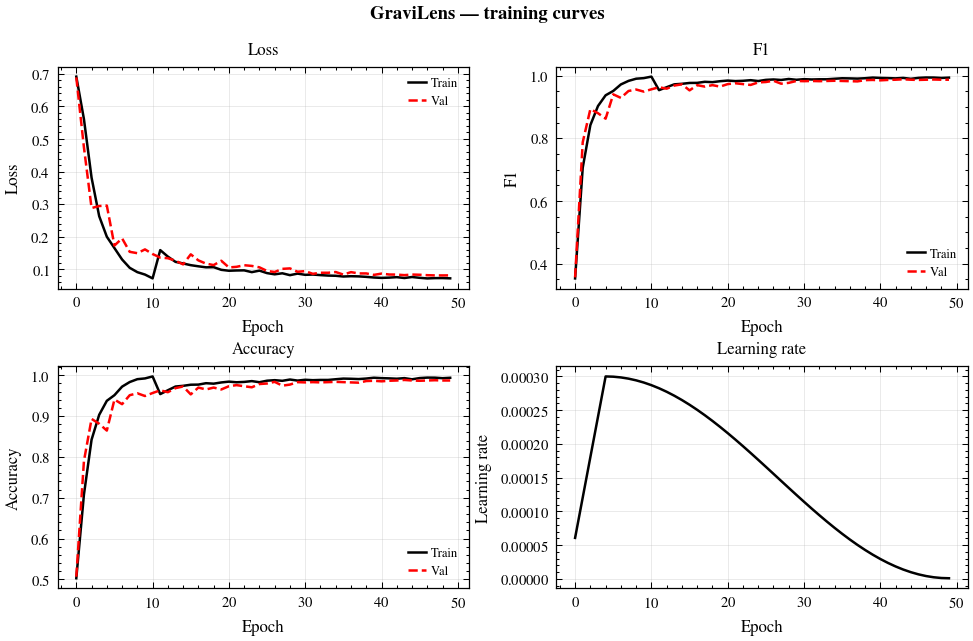

  Saved: /content/drive/My Drive/gravilens_final_benchmark/gravilens-v9-benchmark/roc_curves.png


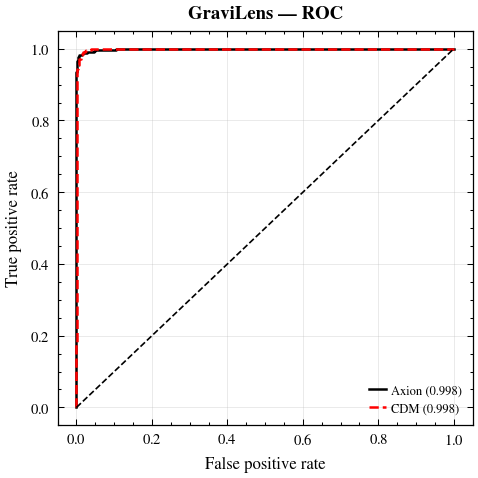

KeyboardInterrupt: 

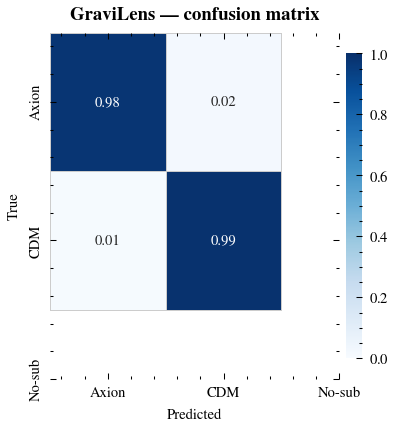

In [1]:
# -*- coding: utf-8 -*-
"""
GraviLens v9 — Full Benchmark (Convergence-Optimised)
======================================================

Models benchmarked:
  PHYSICS-INFORMED (PINNs):
    1. GraviLens      — Physics-Informed Swin Transformer (this work)
    2. Lensformer     — Velôso et al., NeurIPS ML4PS 2023 (re-implemented)
    3. LensPINN-Small — Lensformer ablation (patch=16, embed=384, blocks=2)

  DATA-DRIVEN:
    4. ViT            — Vision Transformer with Shifted Patch Tokenization
    5. CaiT           — Class-Attention in Image Transformers
    6. ViTSD          — Vision Transformer for Small Datasets with LSA

Physics:
  - GraviLens:      SIS κ-map via analytic CLS-token regression + inverse warp
  - Lensformer:     Pixel-wise Einstein angle prediction × distortion map
  - LensPINN-Small: Hyperparameter ablation of Lensformer

Data:
  - Real-Galaxy-Tiny dataset (3-class: axion / cdm / no_sub)
  - Unified GravLensDataset returning (image, distortion, label_int) triples

v9 convergence fixes (GraviLens-specific):
  [FIX 1] Scheduler timing: step(epoch=0) called BEFORE epoch 0 so warmup
          starts from min_lr instead of inverting (epoch-0 spike at 1e-4,
          then plunge to ~6e-6 for 19 epochs).
  [FIX 2] warmup_epochs: 20 -> 5 (10% of budget; 40% was excessive).
  [FIX 3] initial_lr: 1e-4 -> 3e-4 (higher peak LR safe with correct warmup).
  [FIX 4] accumulation_steps: 4 -> 1 (removes 4x delay on weight updates).
  [FIX 5] Lookahead k: 5 -> 3 (faster slow-weight sync during early training).
  [FIX 6] adaptive_clip_factor: 0.01 -> 0.05 (was clipping 99% of grad norm).
  [FIX 7] label_smoothing: 0.1 -> 0.05 (less noise on gradient signal).
  [FIX 8] Progressive augmentation onset delayed to aug_start=10 epochs
          (was perturbing inputs from epoch 0).
  [FIX 9] patience: 30 -> 25 (tighter early-stopping given faster convergence).

Resume / checkpointing (added):
  Every trial writes <trial_dir>/resume.pth after each epoch (atomic, previous
  snapshot kept as resume.prev.pth). If the runtime dies, rerun the same cell:
  finished models reload and skip, the interrupted one continues at its next
  epoch. Set RESUME = False below to ignore snapshots and retrain from scratch.

Colab setup:
  !pip install vit-pytorch SciencePlots torch-lr_finder einops timm
"""

# ==============================================================================
# SECTION 0: INSTALLS, IMPORTS, REPRODUCIBILITY
# ==============================================================================

from google.colab import drive
drive.mount('/content/drive')

!pip install vit-pytorch SciencePlots torch-lr_finder einops timm

import os
import math
import copy
import hashlib
import json
import uuid
import random
import shutil
import warnings
import numpy as np
from datetime import datetime
from pathlib import Path
from typing import Tuple, Union, List, Dict, Optional, Any

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms as transforms
import torchvision.transforms.functional as TF
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.patches as mpatches
from scipy import stats as scipy_stats

from torch.utils.data import Dataset, DataLoader, TensorDataset
from sklearn.metrics import (f1_score, accuracy_score, roc_curve, auc,
                              confusion_matrix, roc_auc_score)
from sklearn.preprocessing import label_binarize
from einops import rearrange, repeat
from einops.layers.torch import Rearrange

try:
    import timm
except ImportError:
    print(" timm not found — run: !pip install timm")

try:
    import scienceplots
    plt.style.use(['science', 'ieee', 'no-latex'])
except ImportError:
    pass

warnings.filterwarnings('ignore')

DEFAULT_SEED = 42

# ---- Checkpoint / resume switches -----------------------------------------
RESUME       = True   # False: ignore existing resume.pth files, train every trial from scratch
RESUME_EVERY = 1      # epochs between resume snapshots (per-config override: "resume_every")

def seed_everything(seed: int = DEFAULT_SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything(DEFAULT_SEED)

print("=" * 80)
print("  GraviLens v9 — Benchmark: GraviLens | Lensformer | LensPINN-Small")
print("                             ViT | CaiT | ViTSD")
print("  Convergence fixes: scheduler timing, warmup, accumulation,")
print("  clip factor, label smoothing, augmentation onset")
print("=" * 80)


# ==============================================================================
# SECTION 1: STABILITY MODULES  (GraviLens heritage)
# ==============================================================================

class WarmupCosineScheduler:
    """Warmup then cosine-annealing learning rate schedule."""
    def __init__(self, optimizer, warmup_epochs, total_epochs,
                 min_lr=1e-6, max_lr=2e-4):
        self.optimizer = optimizer
        self.warmup_epochs = warmup_epochs
        self.total_epochs = total_epochs
        self.min_lr = min_lr
        self.max_lr = max_lr
        self.current_epoch = 0

    def step(self, epoch=None):
        if epoch is not None:
            self.current_epoch = epoch
        else:
            self.current_epoch += 1
        if self.current_epoch < self.warmup_epochs:
            lr = self.min_lr + (self.max_lr - self.min_lr) * (
                self.current_epoch / self.warmup_epochs)
        else:
            progress = ((self.current_epoch - self.warmup_epochs)
                        / (self.total_epochs - self.warmup_epochs))
            lr = self.min_lr + (self.max_lr - self.min_lr) * 0.5 * (
                1 + np.cos(np.pi * progress))
        for pg in self.optimizer.param_groups:
            pg['lr'] = lr
        return lr


class ModelEMA:
    """Exponential Moving Average of model weights (Tan & Le, 2019)."""
    def __init__(self, model, decay=0.9999):
        self.module = copy.deepcopy(model)
        self.module.eval()
        self.decay = decay

    def update(self, model):
        with torch.no_grad():
            for ema_p, model_p in zip(self.module.parameters(),
                                      model.parameters()):
                ema_p.lerp_(model_p.detach(), 1.0 - self.decay)
            for ema_b, model_b in zip(self.module.buffers(),
                                      model.buffers()):
                if ema_b.is_floating_point():
                    ema_b.lerp_(model_b.detach().float(), 1.0 - self.decay)
                else:
                    ema_b.copy_(model_b)


class GradientAccumulator:
    def __init__(self, accumulation_steps=4):
        self.accumulation_steps = accumulation_steps
        self.current_step = 0

    def should_step(self):
        self.current_step += 1
        if self.current_step >= self.accumulation_steps:
            self.current_step = 0
            return True
        return False

    def reset(self):
        self.current_step = 0


def adaptive_gradient_clip(model, clip_factor=0.01):
    parameters = [p for p in model.parameters()
                  if p.grad is not None and p.requires_grad]
    if not parameters:
        return 0.0
    total_norm = torch.norm(
        torch.stack([torch.norm(p.grad.detach()) for p in parameters])).item()
    param_norm = torch.norm(
        torch.stack([torch.norm(p.detach()) for p in parameters])).item()
    max_norm = clip_factor * param_norm
    torch.nn.utils.clip_grad_norm_(parameters, max_norm)
    return total_norm


class Lookahead:
    """Lookahead optimizer wrapper (Zhang et al., 2019)."""
    def __init__(self, optimizer, k=5, alpha=0.5):
        self.optimizer = optimizer
        self.k = k
        self.alpha = alpha
        self.param_groups = self.optimizer.param_groups
        self.state = {}
        self.fast_state = self.optimizer.state
        for group in self.param_groups:
            for p in group['params']:
                param_state = self.state.setdefault(p, {})
                param_state['slow_param'] = torch.zeros_like(p.data)
                param_state['slow_param'].copy_(p.data)
        self.step_counter = 0

    def step(self, closure=None):
        loss = self.optimizer.step(closure)
        self.step_counter += 1
        if self.step_counter >= self.k:
            self.step_counter = 0
            for group in self.param_groups:
                for p in group['params']:
                    if p.grad is None:
                        continue
                    slow = self.state[p]['slow_param']
                    slow.add_(p.data - slow, alpha=self.alpha)
                    p.data.copy_(slow)
        return loss

    def zero_grad(self):
        self.optimizer.zero_grad()

    def state_dict(self):
        # Slow weights are saved by position, not keyed by tensor, so they
        # can be reloaded into a freshly built model.
        params = [p for g in self.param_groups for p in g['params']]
        return {'optimizer': self.optimizer.state_dict(),
                'slow_params': [self.state[p]['slow_param'].detach().cpu().clone()
                                for p in params],
                'step_counter': self.step_counter}

    def load_state_dict(self, state_dict):
        self.optimizer.load_state_dict(state_dict['optimizer'])
        # torch rebinds param_groups / state on load; keep the aliases that
        # step() and the LR scheduler rely on pointing at the live objects.
        self.param_groups = self.optimizer.param_groups
        self.fast_state = self.optimizer.state
        params = [p for g in self.param_groups for p in g['params']]
        assert len(params) == len(state_dict['slow_params']), \
            'Lookahead snapshot does not match this model'
        for p, slow in zip(params, state_dict['slow_params']):
            self.state.setdefault(p, {})['slow_param'] = \
                slow.to(device=p.device, dtype=p.dtype).clone()
        self.step_counter = state_dict['step_counter']


class LabelSmoothingCrossEntropy(nn.Module):
    """Cross entropy with label smoothing (Szegedy et al., 2016)."""
    def __init__(self, smoothing=0.1):
        super().__init__()
        self.smoothing = smoothing
        self.confidence = 1.0 - smoothing

    def forward(self, pred, target):
        pred = pred.log_softmax(dim=-1)
        with torch.no_grad():
            true_dist = torch.zeros_like(pred)
            true_dist.fill_(self.smoothing / (pred.size(-1) - 1))
            true_dist.scatter_(1, target.unsqueeze(1), self.confidence)
        return torch.mean(torch.sum(-true_dist * pred, dim=-1))


class EarlyStopping:
    def __init__(self, patience=15, min_delta=1e-4, mode='min'):
        self.patience = patience
        self.min_delta = min_delta
        self.mode = mode
        self.counter = 0
        self.best_score = None
        self.early_stop = False

    def __call__(self, val_score):
        score = -val_score if self.mode == 'min' else val_score
        if self.best_score is None:
            self.best_score = score
        elif score < self.best_score + self.min_delta:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True
        else:
            self.best_score = score
            self.counter = 0
        return self.early_stop


# ==============================================================================
# SECTION 2: DATA PIPELINE — GravLensDataset
# ==============================================================================

def preprocess_distortion(image: np.ndarray) -> np.ndarray:
    """
    Compute the physics-informed distortion map used by Lensformer/LensPINN.

    Transformation:
        log_img  = [log(I_max / I)]^2
        gradient = d²(log_img) / dx dy   (cross second-order gradient)
        distortion = |tanh(gradient)|
    """
    imax = np.max(image)
    if imax <= 0:
        return np.zeros_like(image, dtype=np.float32)
    log_img  = np.square(np.log(imax / np.clip(image, 1e-12, None)))
    gradient = np.gradient(np.gradient(log_img, axis=0), axis=1)
    return np.abs(np.tanh(gradient)).astype(np.float32)


def precompute_distortions(X: np.ndarray, verbose: bool = True) -> np.ndarray:
    """Batch-compute distortion maps for an entire image array."""
    D = np.zeros_like(X, dtype=np.float32)
    for i in range(len(X)):
        D[i] = preprocess_distortion(X[i])
    if verbose:
        print(f"  Distortion maps: {D.shape}  "
              f"[mean={D.mean():.4f}, std={D.std():.4f}]")
    return D


class GravLensDataset(Dataset):
    """
    Unified dataset for all model families.

    Returns (image [1,H,W], distortion [1,H,W], label_int) triples.

    GraviLens/ViT/CaiT/ViTSD ignore the distortion channel;
    Lensformer/LensPINN use it as a second input stream encoding the
    intensity-gradient feature map.
    """
    def __init__(self, X: np.ndarray, D: np.ndarray, y: np.ndarray,
                 augment: bool = False, aug_intensity: float = 0.0):
        self.X = X.astype(np.float32)
        self.D = D.astype(np.float32)
        if y.ndim == 2:
            self.y = np.argmax(y, axis=1).astype(np.int64)
        else:
            self.y = y.astype(np.int64)
        self.augment = augment
        self.aug_intensity = aug_intensity
        self.H, self.W = X.shape[-2], X.shape[-1]

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        img  = torch.tensor(self.X[idx], dtype=torch.float32).unsqueeze(0)
        dist = torch.tensor(self.D[idx], dtype=torch.float32).unsqueeze(0)
        label = torch.tensor(self.y[idx], dtype=torch.long)

        if self.augment and self.aug_intensity > 0:
            if random.random() < 0.5:
                img  = TF.hflip(img)
                dist = TF.hflip(dist)
            if random.random() < 0.5:
                img  = TF.vflip(img)
                dist = TF.vflip(dist)
            max_angle = 15.0 * self.aug_intensity
            angle = random.uniform(-max_angle, max_angle)
            img  = TF.rotate(img,  angle)
            dist = TF.rotate(dist, angle)

        return img, dist, label


def get_unified_loader(X: np.ndarray, D: np.ndarray, y: np.ndarray,
                       batch_size: int, shuffle: bool = True,
                       augment: bool = False, aug_intensity: float = 0.0,
                       seed: int = DEFAULT_SEED) -> DataLoader:
    dataset = GravLensDataset(X, D, y, augment=augment,
                              aug_intensity=aug_intensity)
    g = torch.Generator().manual_seed(seed)
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle,
                      generator=g, num_workers=0, pin_memory=True)


def get_progressive_unified_loader(X: np.ndarray, D: np.ndarray, y: np.ndarray,
                                   batch_size: int, current_epoch: int,
                                   total_epochs: int,
                                   aug_start: int = 10,
                                   seed: int = DEFAULT_SEED) -> DataLoader:
    """
    Progressive augmentation loader for GraviLens training.

    [FIX 8] Augmentation is held at zero intensity for the first ``aug_start``
    epochs so the model sees clean gradients during early convergence.
    After that, intensity ramps linearly over 70% of the remaining budget.
    """
    if current_epoch < aug_start:
        intensity = 0.0
    else:
        intensity = min(1.0, (current_epoch - aug_start)
                        / max(1, (total_epochs * 0.7 - aug_start)))
    return get_unified_loader(X, D, y, batch_size, shuffle=True,
                              augment=True, aug_intensity=intensity, seed=seed)


def load_numpy_array_from_path(path: str) -> np.ndarray:
    return np.load(path)


# ==============================================================================
# SECTION 3: TRIAL MANAGER
# ==============================================================================

class SimpleTrialManager:
    """Lightweight checkpoint and experiment-tracking manager."""
    def __init__(self, base_checkpoint_dir: str = './model_checkpoints'):
        self.base_dir = Path(base_checkpoint_dir)
        self.base_dir.mkdir(parents=True, exist_ok=True)
        self.registry_file = self.base_dir / 'trials_registry.json'
        self.registry = self._load_registry()

    def _load_registry(self) -> Dict:
        if self.registry_file.exists():
            with open(self.registry_file, 'r') as f:
                return json.load(f)
        return {'trials': {}, 'created': str(datetime.now())}

    def _save_registry(self):
        with open(self.registry_file, 'w') as f:
            json.dump(self.registry, f, indent=2)

    def create_trial(self, trial_name: str, config: Dict[str, Any],
                     description: str = "") -> str:
        trial_dir = self.base_dir / trial_name
        meta_file = trial_dir / 'metadata.json'
        if RESUME and meta_file.exists():
            try:
                with open(meta_file, 'r') as f:
                    _m = json.load(f)
            except Exception:
                _m = None
            if _m is not None:
                # Keep metadata and let the trainer pick up resume.pth.
                print(f"  Trial '{trial_name}' found (status: {_m.get('status', '?')}, "
                      f"last saved epoch: {_m.get('current_epoch', '?')}) — resuming.")
                self.registry['trials'].setdefault(trial_name, {
                    'created': _m.get('created', str(datetime.now())),
                    'status': _m.get('status', 'running'),
                    'folder': str(trial_dir)})
                self._save_registry()
                return trial_name
        if trial_dir.exists():
            print(f"  Trial '{trial_name}' exists — checkpoints will be overwritten.")
        else:
            trial_dir.mkdir(parents=True, exist_ok=True)
            print(f"  Created trial: {trial_name}")

        metadata = {
            'trial_name': trial_name,
            'created': str(datetime.now()),
            'description': description,
            'config': config,
            'status': 'running',
            'current_epoch': 0,
            'final_metrics': {},
            'last_updated': str(datetime.now())
        }
        with open(trial_dir / 'metadata.json', 'w') as f:
            json.dump(metadata, f, indent=2)

        self.registry['trials'][trial_name] = {
            'created': str(datetime.now()),
            'status': 'running',
            'folder': str(trial_dir)
        }
        self._save_registry()
        print(f"  Location: {trial_dir}\n  Description: {description}\n")
        return trial_name

    def save_checkpoint(self, trial_name: str, model: nn.Module, optimizer,
                        epoch: int, metrics: Dict[str, float],
                        save_optimizer: bool = True):
        trial_dir = self.base_dir / trial_name
        if not trial_dir.exists():
            raise ValueError(f"Trial '{trial_name}' does not exist.")

        with open(trial_dir / 'metadata.json', 'r') as f:
            metadata = json.load(f)

        checkpoint = {
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'metrics': metrics,
            'timestamp': str(datetime.now())
        }
        if save_optimizer:
            try:
                checkpoint['optimizer_state_dict'] = optimizer.state_dict()
            except AttributeError:
                pass

        torch.save(checkpoint, trial_dir / f"{trial_name}.pth")

        metadata['current_epoch'] = epoch
        metadata['last_updated'] = str(datetime.now())
        metadata['final_metrics'] = metrics
        with open(trial_dir / 'metadata.json', 'w') as f:
            json.dump(metadata, f, indent=2)

        self.registry['trials'][trial_name]['status'] = 'running'
        self._save_registry()
        print(f"  Saved checkpoint (Epoch {epoch})")

    def mark_complete(self, trial_name: str):
        trial_dir = self.base_dir / trial_name
        with open(trial_dir / 'metadata.json', 'r') as f:
            metadata = json.load(f)
        metadata['status'] = 'completed'
        metadata['completed_at'] = str(datetime.now())
        with open(trial_dir / 'metadata.json', 'w') as f:
            json.dump(metadata, f, indent=2)
        self.registry['trials'][trial_name]['status'] = 'completed'
        self._save_registry()
        print(f"  Trial '{trial_name}' completed.")

    def get_trial_info(self, trial_name: str) -> Dict[str, Any]:
        metadata_file = self.base_dir / trial_name / 'metadata.json'
        if not metadata_file.exists():
            raise ValueError(f"Trial '{trial_name}' has no metadata.")
        with open(metadata_file, 'r') as f:
            return json.load(f)

    def list_trials(self):
        print(f"\n{'='*90}")
        print(f"{'TRIALS SUMMARY':^90}")
        print(f"{'='*90}")
        print(f"{'Trial Name':<40} {'Status':<12} {'Val Loss':<12} {'Val F1':<10}")
        print(f"{'-'*90}")
        for name in self.registry['trials']:
            mf = self.base_dir / name / 'metadata.json'
            if mf.exists():
                with open(mf) as f:
                    m = json.load(f)
                fm = m.get('final_metrics', {})
                vl = fm.get('val_loss', float('inf'))
                vf = fm.get('val_f1', 0.0)
                print(f"{name:<40} {m.get('status','?'):<12} "
                      f"{vl if vl==float('inf') else f'{vl:.4f}':<12} "
                      f"{vf if vf==0 else f'{vf:.4f}':<10}")
        print(f"{'='*90}\n")


# ==============================================================================
# SECTION 3b: RESUME SNAPSHOTS  (survive Colab disconnects and interruptions)
# ==============================================================================
# One snapshot per trial: <trial_dir>/resume.pth, plus resume.prev.pth (the one
# before it). A snapshot holds the model, optimizer (with Lookahead slow
# weights), scheduler epoch, EMA, early-stopping counters, per-epoch history and
# RNG state. A finished trial stores only weights + history and is skipped on rerun.

def _cfg_signature(config: Dict, model_type: str, model: nn.Module) -> str:
    """Hash of the training recipe and model size; a changed recipe invalidates old snapshots."""
    volatile = {'save_every', 'resume_every'}
    blob = json.dumps({'cfg': {k: v for k, v in config.items() if k not in volatile},
                       'type': model_type,
                       'n_params': int(sum(p.numel() for p in model.parameters()))},
                      sort_keys=True, default=str)
    return hashlib.md5(blob.encode()).hexdigest()


def _rng_state() -> Dict:
    st = {'py': random.getstate(), 'np': np.random.get_state(),
          'torch': torch.get_rng_state()}
    if torch.cuda.is_available():
        st['cuda'] = torch.cuda.get_rng_state_all()
    return st


def _set_rng_state(st: Dict):
    random.setstate(st['py'])
    np.random.set_state(st['np'])
    torch.set_rng_state(st['torch'].cpu())
    if 'cuda' in st and torch.cuda.is_available():
        try:
            torch.cuda.set_rng_state_all([s.cpu() for s in st['cuda']])
        except Exception:
            pass


def _atomic_save(obj, path):
    """Write to a temp file, then rename. A kill mid-write never corrupts the last good snapshot."""
    path = Path(path)
    tmp = path.with_name(path.name + '.tmp')
    torch.save(obj, tmp)
    try:
        with open(tmp, 'rb') as f:
            os.fsync(f.fileno())
    except OSError:
        pass
    if path.exists():
        os.replace(path, path.with_name(path.stem + '.prev' + path.suffix))
    os.replace(tmp, path)


def _save_resume(trial_dir, sig, epoch_done, done, model, optimizer,
                 scheduler, ema, stopper, grad_acc, history):
    payload = {
        'sig': sig,
        'epoch_done': int(epoch_done),
        'done': bool(done),
        'model': model.state_dict(),
        'optimizer': None if done else optimizer.state_dict(),
        'scheduler': (None if scheduler is None
                      else {'current_epoch': scheduler.current_epoch}),
        'ema': (ema.module.state_dict() if (ema is not None and not done) else None),
        'stopper': dict(stopper.__dict__),
        'grad_acc': 0 if grad_acc is None else grad_acc.current_step,
        'history': {k: [float(x) for x in v] for k, v in history.items()},
        'rng': _rng_state(),
        'saved': str(datetime.now()),
    }
    _atomic_save(payload, Path(trial_dir) / 'resume.pth')


def _load_resume(trial_dir, sig):
    """Newest readable snapshot whose recipe matches, else None."""
    if not RESUME:
        return None
    base = Path(trial_dir) / 'resume.pth'
    for p in (base, base.with_name('resume.prev.pth')):
        if not p.exists():
            continue
        try:
            try:
                st = torch.load(p, map_location='cpu', weights_only=False)
            except TypeError:                       # very old torch
                st = torch.load(p, map_location='cpu')
        except Exception as e:
            print(f"  [resume] {p.name} unreadable ({type(e).__name__}); trying the older snapshot")
            continue
        if st.get('sig') != sig:
            print(f"  [resume] {p.name} was written with a different config or architecture; "
                  f"starting fresh")
            return None
        return st
    return None


def _restore_state(st, model, optimizer, scheduler, ema, stopper, grad_acc):
    model.load_state_dict(st['model'])
    if st.get('optimizer') is not None:
        optimizer.load_state_dict(st['optimizer'])
    if scheduler is not None and st.get('scheduler') is not None:
        scheduler.step(epoch=st['scheduler']['current_epoch'])   # re-apply LR for that epoch
    if ema is not None and st.get('ema') is not None:
        ema.module.load_state_dict(st['ema'])
    stopper.__dict__.update(st['stopper'])
    if grad_acc is not None:
        grad_acc.current_step = st.get('grad_acc', 0)
    _set_rng_state(st['rng'])


def _restore_history(hist: Dict[str, list], saved: Dict[str, list]):
    for k, lst in hist.items():          # fill the trainer's own lists in place
        lst[:] = list(saved.get(k, []))


# ==============================================================================
# SECTION 4: SHARED BUILDING BLOCKS
# ==============================================================================

class Flatten(nn.Module):
    """Flatten (B, *, *) to (B, num_neurons)."""
    def __init__(self, num_neurons_flatten: int):
        super().__init__()
        self.num_neurons_flatten = num_neurons_flatten

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return x.contiguous().view(-1, self.num_neurons_flatten)


def count_parameters(model: nn.Module) -> float:
    total = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"  Total trainable parameters: {total:,} ({total / 1e6:.2f}M)")
    return total / 1e6


# ==============================================================================
# SECTION 5a: SHIFTED PATCH TOKENIZATION  — GraviLens variant (Swin-SPT)
# ==============================================================================

class ShiftedPatchTokenization(nn.Module):
    """
    Shifted Patch Tokenization with diagonal 4-shift augmentation.
    Used exclusively by GraviLens. Disables Conv2d bias per Swin-SPT convention.
    """
    def __init__(self, image_size: Union[int, Tuple[int, int]],
                 patch_size: Union[int, Tuple[int, int]],
                 embed_dim: int, in_channels: int, device: torch.device):
        super().__init__()
        if isinstance(image_size, int):
            image_size = (image_size, image_size)
        if isinstance(patch_size, int):
            patch_size = (patch_size, patch_size)

        self.embed_dim = embed_dim
        self.image_width, self.image_height = image_size
        self.patch_width, self.patch_height = patch_size
        self.device = device

        if self.image_width % self.patch_width != 0:
            raise ValueError("Image size must be divisible by patch size.")

        self.num_patches = int((self.image_width // self.patch_width)
                               * (self.image_height // self.patch_height))
        self.delta_x = self.patch_width // 2
        self.delta_y = self.patch_height // 2
        total_channels = in_channels * 5

        self.projection = nn.Conv2d(
            in_channels=total_channels,
            out_channels=embed_dim,
            kernel_size=(self.patch_width, self.patch_height),
            stride=(self.patch_width, self.patch_height)
        ).to(device)

        self.layer_norm = nn.LayerNorm(embed_dim)
        self.cls_token = nn.Parameter(torch.zeros(1, 1, embed_dim))
        self.positional_encoding = nn.Parameter(
            torch.zeros(1, 1 + self.num_patches, embed_dim))

        if self.projection.bias is not None:
            self.register_buffer('projection_bias', self.projection.bias.data)
            self.projection.bias = None

    def _translate(self, image: torch.Tensor, dx: int, dy: int) -> torch.Tensor:
        return TF.affine(image, angle=0, translate=(dx, dy),
                         fill=0, scale=1, shear=0).to(self.device)

    def get_num_patches(self) -> int:
        return self.num_patches

    def forward(self, image: torch.Tensor) -> torch.Tensor:
        B = image.size(0)
        dx, dy = self.delta_x, self.delta_y
        shifted = torch.cat([
            image,
            self._translate(image, -dx, -dy),
            self._translate(image,  dx, -dy),
            self._translate(image, -dx,  dy),
            self._translate(image,  dx,  dy),
        ], dim=1)

        patches = self.projection(shifted).flatten(2).transpose(1, 2)
        patches = self.layer_norm(patches)
        cls = self.cls_token.expand(B, -1, -1)
        patches = torch.cat([cls, patches], dim=1)
        return patches + self.positional_encoding


# ==============================================================================
# SECTION 5b: SHIFTED PATCH TOKENIZATION  — Lensformer/LensPINN variant
# ==============================================================================

class ShiftPatchTokenizer(nn.Module):
    """
    Shifted Patch Tokenizer from Lensformer (Velôso et al., 2023).
    Supports 'diagonal' and 'rectangular' translation modes.
    """
    def __init__(self, image_size: int, embedding_size: int, patch_size: int,
                 num_channels: int, translation_mode: str,
                 device: Union[str, torch.device] = 'cpu'):
        super().__init__()
        if image_size % patch_size != 0:
            raise ValueError("image_size must be divisible by patch_size.")

        self.image_size = image_size
        self.embedding_size = embedding_size
        self.patch_size = patch_size
        self.num_channels = num_channels
        self.translation_mode = translation_mode
        self.device = (torch.device(device)
                       if isinstance(device, str) else device)

        self.num_patches = (image_size // patch_size) ** 2
        self.total_channels = num_channels * 5

        self.tokenizer = nn.Conv2d(
            in_channels=self.total_channels,
            out_channels=embedding_size,
            kernel_size=(patch_size, patch_size),
            stride=(patch_size, patch_size)
        )

        self.shift_x = patch_size // 2
        self.shift_y = patch_size // 2

        self.class_embedding = nn.Parameter(
            torch.zeros(1, 1, embedding_size))
        self.positional = nn.Parameter(
            torch.zeros(1, self.num_patches + 1, embedding_size))

    def _translate(self, image: torch.Tensor,
                   dx: int, dy: int) -> torch.Tensor:
        return TF.affine(img=image, angle=0, translate=(dx, dy),
                         scale=1, shear=0).to(self.device)

    def get_num_patches(self) -> int:
        return self.num_patches

    def forward(self, image: torch.Tensor) -> torch.Tensor:
        image = image.to(self.device)
        B = image.shape[0]
        sx, sy = self.shift_x, self.shift_y

        if self.translation_mode == "diagonal":
            patches_cat = torch.cat([
                image,
                self._translate(image, -sx, -sy),
                self._translate(image,  sx, -sy),
                self._translate(image, -sx,  sy),
                self._translate(image,  sx,  sy),
            ], dim=1)
        elif self.translation_mode == "rectangular":
            patches_cat = torch.cat([
                image,
                self._translate(image,   0,  sy),
                self._translate(image,   0, -sy),
                self._translate(image, -sx,   0),
                self._translate(image,  sx,   0),
            ], dim=1)
        else:
            raise ValueError(f"Unknown translation_mode: {self.translation_mode}")

        embeddings = self.tokenizer(patches_cat).flatten(2).transpose(1, 2)
        cls = self.class_embedding.expand(B, -1, -1)
        patches = torch.cat([cls, embeddings], dim=1)
        return patches + self.positional


# ==============================================================================
# SECTION 5c: SHIFTED PATCH TOKENIZATION  — ViT/ViTSD variant (einops-based)
# ==============================================================================

class SPT(nn.Module):
    """
    Shifted Patch Tokenization for ViT and ViTSD.
    Uses einops rearrange + padding shifts — lighter than Conv2d-based SPT.
    Reference: Lee et al., 2021 (ViT for Small Datasets).
    """
    def __init__(self, dim: int, patch_size: int, channels: int = 1):
        super().__init__()
        patch_dim = patch_size * patch_size * 5 * channels
        self.to_patch_tokens = nn.Sequential(
            Rearrange('b c (h p1) (w p2) -> b (h w) (p1 p2 c)',
                      p1=patch_size, p2=patch_size),
            nn.LayerNorm(patch_dim),
            nn.Linear(patch_dim, dim)
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        shifts = ((1, -1, 0, 0), (-1, 1, 0, 0), (0, 0, 1, -1), (0, 0, -1, 1))
        shifted_x = list(map(lambda shift: F.pad(x, shift), shifts))
        x_with_shifts = torch.cat((x, *shifted_x), dim=1)
        return self.to_patch_tokens(x_with_shifts)


# ==============================================================================
# SECTION 6: TRANSFORMER BLOCKS — GraviLens (Swin-style window attention)
# ==============================================================================

class WindowAttention(nn.Module):
    """Window-based multi-head self-attention with relative position bias."""
    def __init__(self, dim: int, num_heads: int, window_size: int,
                 dropout: float = 0.):
        super().__init__()
        self.dim = dim
        self.window_size = window_size
        self.num_heads = num_heads
        head_dim = dim // num_heads
        self.scale = head_dim ** -0.5

        self.relative_position_bias_table = nn.Parameter(
            torch.zeros((2 * window_size - 1) ** 2, num_heads))

        coords_h = torch.arange(window_size)
        coords_w = torch.arange(window_size)
        coords = torch.stack(
            torch.meshgrid([coords_h, coords_w], indexing='ij'))
        coords_flat = torch.flatten(coords, 1)
        rel_coords = coords_flat[:, :, None] - coords_flat[:, None, :]
        rel_coords = rel_coords.permute(1, 2, 0).contiguous()
        rel_coords[:, :, 0] += window_size - 1
        rel_coords[:, :, 1] += window_size - 1
        rel_coords[:, :, 0] *= 2 * window_size - 1
        self.register_buffer("relative_position_index",
                             rel_coords.sum(-1))

        self.qkv = nn.Linear(dim, dim * 3, bias=True)
        self.attn_drop = nn.Dropout(dropout)
        self.proj = nn.Linear(dim, dim)
        self.proj_drop = nn.Dropout(dropout)

        nn.init.trunc_normal_(self.relative_position_bias_table, std=0.02)

    def forward(self, x: torch.Tensor,
                mask: Optional[torch.Tensor] = None) -> torch.Tensor:
        B_, N, C = x.shape
        qkv = (self.qkv(x)
               .reshape(B_, N, 3, self.num_heads, C // self.num_heads)
               .permute(2, 0, 3, 1, 4))
        q, k, v = qkv[0], qkv[1], qkv[2]
        q = q * self.scale
        attn = q @ k.transpose(-2, -1)

        rel_bias = (
            self.relative_position_bias_table[
                self.relative_position_index.view(-1)]
            .view(self.window_size ** 2, self.window_size ** 2, -1)
            .permute(2, 0, 1).contiguous()
        )
        attn = attn + rel_bias.unsqueeze(0)

        if mask is not None:
            nW = mask.shape[0]
            attn = (attn.view(B_ // nW, nW, self.num_heads, N, N)
                    + mask.unsqueeze(1).unsqueeze(0))
            attn = attn.view(-1, self.num_heads, N, N)

        attn = F.softmax(attn, dim=-1)
        attn = self.attn_drop(attn)

        x = (attn @ v).transpose(1, 2).reshape(B_, N, C)
        return self.proj_drop(self.proj(x))


class TransformerBlock(nn.Module):
    """Single Swin-style block: window attention + MLP + CLS-pass-through."""
    def __init__(self, dim: int, num_heads: int, window_size: int,
                 mlp_ratio: float = 4., dropout: float = 0.):
        super().__init__()
        self.dim = dim
        self.window_size = window_size
        self.norm1 = nn.LayerNorm(dim)
        self.attn = WindowAttention(dim, num_heads, window_size, dropout)
        self.norm2 = nn.LayerNorm(dim)
        mlp_hidden = int(dim * mlp_ratio)
        self.mlp = nn.Sequential(
            nn.Linear(dim, mlp_hidden), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(mlp_hidden, dim), nn.Dropout(dropout)
        )

    @staticmethod
    def _partition(x: torch.Tensor, ws: int) -> torch.Tensor:
        B, H, W, C = x.shape
        x = x.view(B, H // ws, ws, W // ws, ws, C)
        return x.permute(0, 1, 3, 2, 4, 5).contiguous().view(-1, ws * ws, C)

    @staticmethod
    def _reverse(windows: torch.Tensor, ws: int,
                 H: int, W: int) -> torch.Tensor:
        B = int(windows.shape[0] / (H * W / ws / ws))
        x = windows.view(B, H // ws, W // ws, ws, ws, -1)
        return x.permute(0, 1, 3, 2, 4, 5).contiguous().view(B, H, W, -1)

    def forward(self, x: torch.Tensor, H: int, W: int,
                key=None, value=None) -> torch.Tensor:
        B, L, C = x.shape
        cls_token  = x[:, 0:1, :]
        x_patches  = x[:, 1:, :]
        shortcut   = x_patches
        x_patches  = self.norm1(x_patches).view(B, H, W, C)

        windows = self._partition(x_patches, self.window_size)
        attn_win = self.attn(windows)
        x_patches = self._reverse(attn_win, self.window_size, H, W)
        x_patches = x_patches.view(B, H * W, C)
        x_patches = shortcut + x_patches
        x = torch.cat([cls_token, x_patches], dim=1)
        return x + self.mlp(self.norm2(x))


class HierarchicalTransformerStage(nn.Module):
    """Stack of TransformerBlocks with cross-attention key/value injection."""
    def __init__(self, dim: int, depth: int, num_heads: int, window_size: int,
                 mlp_ratio: float = 4., dropout: float = 0.):
        super().__init__()
        self.window_size = window_size
        self.blocks = nn.ModuleList([
            TransformerBlock(dim, num_heads, window_size, mlp_ratio, dropout)
            for _ in range(depth)
        ])

    def forward(self, x: torch.Tensor, H: int, W: int,
                key=None, value=None) -> torch.Tensor:
        if H % self.window_size != 0 or W % self.window_size != 0:
            raise ValueError(
                f"H={H}, W={W} must be divisible by window_size={self.window_size}.")
        for blk in self.blocks:
            x = blk(x, H, W, key, value)
        return x


# ==============================================================================
# SECTION 7: TRANSFORMER BLOCKS — Lensformer/LensPINN (LSA)
# ==============================================================================

class MultiLocallySelfAttention(nn.Module):
    """
    Locally Self-Attention (LSA): standard MHA with diagonal attention mask.
    The identity mask (True on diagonal) blocks intra-token self-attention,
    forcing each token to attend only to other tokens.
    """
    def __init__(self, embedding_dim: int, num_heads: int, num_patches: int,
                 device: Union[str, torch.device], dropout: float = 0.1):
        super().__init__()
        self.embedding_dim = embedding_dim
        self.num_heads = num_heads
        self.num_patches = num_patches
        self.device = (torch.device(device)
                       if isinstance(device, str) else device)
        attn_mask = torch.eye(1 + num_patches, 1 + num_patches,
                              dtype=torch.bool, requires_grad=False)
        self.register_buffer('attention_mask', attn_mask)
        self.mha = nn.MultiheadAttention(
            embedding_dim, num_heads, dropout=dropout, batch_first=True)

    def forward(self, key: torch.Tensor, query: torch.Tensor,
                value: torch.Tensor) -> torch.Tensor:
        x, _ = self.mha(query, key, value,
                        attn_mask=self.attention_mask)
        return x


class FeedForwardBlockLSA(nn.Module):
    """
    FeedForward block used inside Lensformer/LensPINN transformer layers.
    Emits raw logits for multiclass (Identity final activation) to avoid
    the double-softmax error present in the original Velôso et al. code.
    """
    def __init__(self, in_dim: int, out_dim: int, hidden_dim: int,
                 num_hidden_layers: int, activation_function,
                 task_type: str, dropout: float = 0.1):
        super().__init__()
        layers = [
            nn.Linear(in_dim, hidden_dim),
            activation_function(),
            nn.Dropout(dropout)
        ]
        for _ in range(num_hidden_layers):
            layers += [nn.Linear(hidden_dim, hidden_dim),
                       activation_function(), nn.Dropout(dropout)]

        layers.append(nn.Linear(hidden_dim, out_dim))

        if task_type == "regression":
            layers.append(nn.Identity())
        elif task_type == "binary":
            if out_dim != 1:
                raise ValueError("Binary classification requires out_dim=1.")
            layers.append(nn.Sigmoid())
        elif task_type == "multiclass":
            layers.append(nn.Identity())
        else:
            raise ValueError(f"Unknown task_type: {task_type}")

        self.network = nn.Sequential(*layers)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.network(x)


class TransformerLSABlock(nn.Module):
    """
    Transformer block using MultiLocallySelfAttention.
    Supports cross-attention: key/query/value can differ (used by Lensformer).
    """
    def __init__(self, embedding_dim: int, num_head: int, num_patches: int,
                 num_hidden_neurons: int, num_hidden_layers: int,
                 activation_function, device: Union[str, torch.device],
                 dropout: float = 0.1):
        super().__init__()
        self.device = (torch.device(device)
                       if isinstance(device, str) else device)
        self.mlsa = MultiLocallySelfAttention(
            embedding_dim, num_head, num_patches, device, dropout)
        self.norm1 = nn.LayerNorm(embedding_dim)
        self.feedforward = FeedForwardBlockLSA(
            in_dim=embedding_dim, out_dim=embedding_dim,
            hidden_dim=num_hidden_neurons,
            num_hidden_layers=num_hidden_layers,
            activation_function=activation_function,
            task_type="regression", dropout=dropout)
        self.norm2 = nn.LayerNorm(embedding_dim)
        self.dropout = nn.Dropout(dropout)
        self.temperature = nn.Parameter(torch.ones(1))
        self.query_T = nn.Linear(embedding_dim, embedding_dim)
        self.value_T = nn.Linear(embedding_dim, embedding_dim)

    def forward(self, key: torch.Tensor,
                query: Optional[torch.Tensor] = None,
                value: Optional[torch.Tensor] = None) -> torch.Tensor:
        key = key.to(self.device)
        if query is None:
            query = (self.query_T(key) / self.temperature).to(self.device)
        if value is None:
            value = self.value_T(key)

        value = value + self.mlsa(key, query, value)
        value = self.norm1(value)
        value = value + self.feedforward(value)
        value = self.norm2(value)
        return self.dropout(value)


# ==============================================================================
# SECTION 7b: LSA FOR ViTSD
# ==============================================================================

class LSA(nn.Module):
    """
    Locally Self-Attention for ViTSD (Lee et al., 2021).
    Learnable temperature + masked diagonal to suppress self-attention bias.
    Pre-norm is applied internally before the QKV projection, consistent
    with the updated baseline (Lee et al., 2021, revised).
    """
    def __init__(self, dim: int, heads: int = 8, dim_head: int = 64,
                 dropout: float = 0.):
        super().__init__()
        inner_dim = dim_head * heads
        self.heads = heads
        self.temperature = nn.Parameter(
            torch.log(torch.tensor(dim_head ** -0.5)))
        self.norm    = nn.LayerNorm(dim)
        self.attend  = nn.Softmax(dim=-1)
        self.dropout = nn.Dropout(dropout)
        self.to_qkv  = nn.Linear(dim, inner_dim * 3, bias=False)
        self.to_out  = nn.Sequential(
            nn.Linear(inner_dim, dim),
            nn.Dropout(dropout)
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x   = self.norm(x)
        qkv = self.to_qkv(x).chunk(3, dim=-1)
        q, k, v = map(
            lambda t: rearrange(t, 'b n (h d) -> b h n d', h=self.heads), qkv)

        dots = torch.matmul(q, k.transpose(-1, -2)) * self.temperature.exp()

        mask = torch.eye(dots.shape[-1], device=dots.device, dtype=torch.bool)
        mask_value = -torch.finfo(dots.dtype).max
        dots = dots.masked_fill(mask, mask_value)

        attn = self.attend(dots)
        attn = self.dropout(attn)

        out = torch.matmul(attn, v)
        out = rearrange(out, 'b h n d -> b n (h d)')
        return self.to_out(out)


# ==============================================================================
# SECTION 8: FEEDFORWARD — GraviLens
# ==============================================================================

class FeedForward(nn.Module):
    """MLP used as GraviLens classifier head."""
    def __init__(self, input_dim: int, output_dim: int, activation,
                 hidden_dim: int, num_layers: int,
                 task_type: str = 'multi_classification',
                 dropout: float = 0.1):
        super().__init__()
        layers = []
        current = input_dim
        for _ in range(num_layers):
            layers += [nn.Linear(current, hidden_dim),
                       activation(), nn.Dropout(dropout)]
            current = hidden_dim
        layers.append(nn.Linear(current, output_dim))
        self.network = nn.Sequential(*layers)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.network(x)


# ==============================================================================
# SECTION 9: SIS PHYSICS — GraviLens
# ==============================================================================

class SimpleSISDeflection:
    """SIS deflection via potential gradient."""
    def __init__(self, eps: float = 1e-8, core_radius: float = 0.01):
        self.eps = eps
        self.core_radius = core_radius

    def calculate_deflection(
            self, x: torch.Tensor, y: torch.Tensor,
            k: torch.Tensor) -> Tuple[torch.Tensor, torch.Tensor]:
        if k.ndim == 1:
            k = k.unsqueeze(-1).expand(-1, x.shape[-1])
        r = torch.sqrt(x ** 2 + y ** 2 + self.core_radius ** 2)
        return k * x / r, k * y / r


class SimpleSISPredictor(nn.Module):
    """
    Physics-correct SIS kappa-map predictor.
    Predicts scalar Einstein radius theta_E and optional lens-center offset
    from the CLS token, then computes the radially-symmetric convergence map.
    """
    def __init__(self, embed_dim: int, image_size: int = 64,
                 k_min: float = 0.7, k_max: float = 1.4,
                 device: Optional[torch.device] = None):
        super().__init__()
        self.image_size = image_size
        self.device = device or torch.device(
            "cuda" if torch.cuda.is_available() else "cpu")
        self.k_min, self.k_max = k_min, k_max

        self.global_branch = nn.Sequential(
            nn.Linear(embed_dim, 512), nn.GELU(), nn.LayerNorm(512),
            nn.Dropout(0.1),
            nn.Linear(512, 256), nn.GELU(), nn.LayerNorm(256),
            nn.Dropout(0.1),
            nn.Linear(256, 1), nn.Sigmoid()
        )
        self.center_branch = nn.Sequential(
            nn.Linear(embed_dim, 128), nn.GELU(),
            nn.Linear(128, 2), nn.Tanh()
        )

        half = (image_size - 1) / 2.0
        coords = torch.linspace(-half, half, image_size)
        grid_y, grid_x = torch.meshgrid(coords, coords, indexing='ij')
        self.register_buffer('grid_x', grid_x)
        self.register_buffer('grid_y', grid_y)
        self._theta_E = None

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        B = x.shape[0]
        cls = x[:, 0, :]

        theta_E_raw = self.global_branch(cls)
        theta_E = self.k_min + (self.k_max - self.k_min) * theta_E_raw
        self._theta_E = theta_E

        max_offset = (self.image_size - 1) / 2.0 * 0.20
        center = self.center_branch(cls) * max_offset
        x_c, y_c = center[:, 0], center[:, 1]

        dx = self.grid_x.unsqueeze(0) - x_c.view(B, 1, 1)
        dy = self.grid_y.unsqueeze(0) - y_c.view(B, 1, 1)
        r = torch.sqrt(dx ** 2 + dy ** 2 + 1.0)

        k_map = theta_E.view(B, 1, 1) / (2.0 * r)
        return torch.clamp(k_map, self.k_min, self.k_max).unsqueeze(1)


class SISPhysicsInformedEncoder(nn.Module):
    """GraviLens encoder: computes inverse-warp source reconstruction."""
    def __init__(self, image_size: int, patch_size: int, embed_dim: int,
                 num_patches: int, num_heads: int, num_hidden_neurons: int,
                 activation_function, num_transformer_blocks: int,
                 device: torch.device, window_size: int = 4):
        super().__init__()
        self.image_size = image_size
        self.device = device
        self.pixel_scale = 0.101
        self.H = self.W = int(math.sqrt(num_patches))

        if self.H % window_size != 0:
            for ws in [2, 4, 8]:
                if self.H % ws == 0:
                    window_size = ws
                    break

        half = (image_size - 1) / 2
        coords_1d = torch.linspace(-half, half, image_size,
                                   device=device) * self.pixel_scale
        gx, gy = torch.meshgrid(coords_1d, coords_1d, indexing='ij')
        self.flat_grid_x = gx.flatten()
        self.flat_grid_y = gy.flatten()

        self.sis_deflection = SimpleSISDeflection(eps=1e-6, core_radius=0.01)
        self.sis_predictor  = SimpleSISPredictor(
            embed_dim, image_size=image_size, device=device)
        self.transformer = HierarchicalTransformerStage(
            dim=embed_dim, depth=num_transformer_blocks,
            num_heads=num_heads, window_size=window_size,
            mlp_ratio=4., dropout=0.1)

    def forward(self, input_images: torch.Tensor,
                patches: torch.Tensor) -> torch.Tensor:
        B = input_images.shape[0]

        transformer_out = self.transformer(patches, self.H, self.W)
        k_map   = self.sis_predictor(transformer_out)
        theta_E = self.sis_predictor._theta_E
        k_flat  = theta_E.expand(-1, self.flat_grid_x.shape[0])

        alpha_x, alpha_y = self.sis_deflection.calculate_deflection(
            self.flat_grid_x.unsqueeze(0).expand(B, -1),
            self.flat_grid_y.unsqueeze(0).expand(B, -1),
            k_flat)

        source_x = self.flat_grid_x.unsqueeze(0) - alpha_x
        source_y = self.flat_grid_y.unsqueeze(0) - alpha_y

        max_coord = ((self.image_size - 1) / 2) * self.pixel_scale
        src_px = torch.clamp(
            ((source_x + max_coord) / (2 * max_coord)
             * (self.image_size - 1)).round().long(),
            0, self.image_size - 1)
        src_py = torch.clamp(
            ((source_y + max_coord) / (2 * max_coord)
             * (self.image_size - 1)).round().long(),
            0, self.image_size - 1)

        flat_imgs = input_images.view(B, -1)
        flat_idx  = src_px * self.image_size + src_py

        source_flat  = torch.zeros(B, self.image_size ** 2, device=self.device)
        count_flat   = torch.zeros(B, self.image_size ** 2, device=self.device)
        ones         = torch.ones_like(flat_idx, dtype=torch.float32)

        source_flat = source_flat.scatter_add(1, flat_idx, flat_imgs)
        count_flat  = count_flat.scatter_add(1, flat_idx, ones)

        mask = count_flat > 0
        source_flat[mask] /= count_flat[mask]

        max_val = source_flat.amax(dim=1, keepdim=True).clamp(min=1e-8)
        source_image = (source_flat / max_val).view(
            B, 1, self.image_size, self.image_size)
        return source_image


# ==============================================================================
# SECTION 10: SIS PHYSICS — Lensformer / LensPINN
# ==============================================================================

def _torch_image_to_source(image: torch.Tensor, E_r: torch.Tensor,
                            image_size: int, device: torch.device,
                            min_angle: float = -3.323,
                            max_angle: float = 3.232) -> torch.Tensor:
    """Differentiable per-image source reconstruction (scatter_add)."""
    pw = (max_angle - min_angle) / image_size
    cx, cy = image_size // 2, image_size // 2
    imones_1d = torch.ones(image_size * image_size, device=device)

    rx = torch.arange(-(cx - 1), image_size - (cx - 1), device=device)
    ry = torch.arange(-(cy - 1), image_size - (cy - 1), device=device)
    x, y = torch.meshgrid(rx, ry, indexing='ij')
    x, y = x * pw, y * pw
    r = torch.sqrt(x ** 2 + y ** 2)
    r[r == 0] = 1.0

    k = torch.ones((image_size, image_size), device=device) * E_r
    xdef = k * x / r
    ydef = k * y / r

    bx = torch.clamp(((x - xdef) / pw + cx), 0, image_size - 1).long()
    by = torch.clamp(((y - ydef) / pw + cy), 0, image_size - 1).long()

    flat_image = image.view(-1)
    flat_bx    = bx.view(-1)
    flat_by    = by.view(-1)
    indices    = flat_bx * image_size + flat_by

    src_flat = torch.zeros(image_size * image_size, device=device)
    cnt_flat = torch.zeros(image_size * image_size, device=device)
    src_flat = src_flat.scatter_add(0, indices, flat_image)
    cnt_flat = cnt_flat.scatter_add(0, indices, imones_1d)
    mask = cnt_flat != 0
    src_flat[mask] /= cnt_flat[mask]
    return src_flat.view(image_size, image_size)


class PhysicsInformedEncoder(nn.Module):
    """Lensformer encoder: pixel-wise Einstein angle map via transformer."""
    def __init__(self, image_size: int, patch_size: int, embedding_dim: int,
                 num_patches: int, num_heads: int, hidden_dim: int,
                 transformer_block_activation_function,
                 num_transformer_block: int,
                 device: Union[str, torch.device], k_max: float, k_min: float,
                 num_hidden_layer: int = 1, dropout: float = 0.1,
                 min_angle: float = -3.323, max_angle: float = 3.232,
                 mag: int = 1):
        super().__init__()
        self.image_size = image_size
        self.embedding_dim = embedding_dim
        self.k_max, self.k_min = k_max, k_min
        self.device = (torch.device(device)
                       if isinstance(device, str) else device)
        self.min_angle, self.max_angle = min_angle, max_angle

        self.transformer = nn.ModuleList()
        for _ in range(num_transformer_block):
            self.transformer.append(
                TransformerLSABlock(
                    embedding_dim=embedding_dim, num_head=num_heads,
                    num_patches=num_patches,
                    num_hidden_neurons=hidden_dim,
                    num_hidden_layers=num_hidden_layer,
                    activation_function=transformer_block_activation_function,
                    device=device, dropout=dropout))

        total_features = (num_patches + 1) * embedding_dim
        self.transformer.append(nn.Flatten())
        self.transformer.append(
            nn.Linear(total_features, image_size * image_size))

    def forward(self, input_images: torch.Tensor,
                patches: torch.Tensor,
                distortion: torch.Tensor) -> Tuple[torch.Tensor, torch.Tensor]:
        input_images = input_images.to(self.device)
        distortion   = distortion.to(self.device)
        patches      = patches.to(self.device)
        B = input_images.shape[0]

        k_sigmoid = patches
        for layer in self.transformer:
            k_sigmoid = layer(k_sigmoid)

        k_sigmoid     = k_sigmoid.view(B, self.image_size, self.image_size)
        distortion    = distortion.view(B, self.image_size, self.image_size)
        einstein_angle = k_sigmoid * distortion

        input_images = input_images.view(B, self.image_size, self.image_size)
        source_image = torch.zeros_like(input_images)
        for i in range(B):
            source_image[i] = _torch_image_to_source(
                input_images[i], einstein_angle[i],
                self.image_size, self.device,
                self.min_angle, self.max_angle)

        return k_sigmoid, source_image


class ChangedPhysicsInformedEncoder(nn.Module):
    """LensPINN encoder: scalar Einstein radius prediction."""
    def __init__(self, image_size: int, patch_size: int, embedding_dim: int,
                 num_patches: int, num_heads: int, hidden_dim: int,
                 transformer_block_activation_function,
                 num_transformer_block: int,
                 device: Union[str, torch.device], k_max: float, k_min: float,
                 num_hidden_layer: int = 1, dropout: float = 0.1,
                 min_angle: float = -3.323, max_angle: float = 3.232,
                 mag: int = 1):
        super().__init__()
        self.image_size = image_size
        self.k_max, self.k_min = k_max, k_min
        self.device = (torch.device(device)
                       if isinstance(device, str) else device)
        self.min_angle, self.max_angle = min_angle, max_angle

        self.transformer = nn.ModuleList()
        for _ in range(num_transformer_block):
            self.transformer.append(
                TransformerLSABlock(
                    embedding_dim=embedding_dim, num_head=num_heads,
                    num_patches=num_patches,
                    num_hidden_neurons=hidden_dim,
                    num_hidden_layers=num_hidden_layer,
                    activation_function=transformer_block_activation_function,
                    device=device, dropout=dropout))

        total_features = (num_patches + 1) * embedding_dim
        self.transformer.append(nn.Flatten())
        self.transformer.append(nn.Linear(total_features, 1))

    def forward(self, input_images: torch.Tensor,
                patches: torch.Tensor,
                distortion: torch.Tensor) -> Tuple[torch.Tensor, torch.Tensor]:
        input_images = input_images.to(self.device)
        patches      = patches.to(self.device)
        B = input_images.shape[0]

        theta_E = patches
        for layer in self.transformer:
            theta_E = layer(theta_E)

        input_images = input_images.view(B, self.image_size, self.image_size)
        source_image = torch.zeros_like(input_images)
        for i in range(B):
            source_image[i] = _torch_image_to_source(
                input_images[i], theta_E[i],
                self.image_size, self.device,
                self.min_angle, self.max_angle)

        return theta_E, source_image


# ==============================================================================
# SECTION 11: MODEL DEFINITIONS
# ==============================================================================

# -- 11a: GraviLens  -----------------------------------------------------------

class GraviLens(nn.Module):
    """
    GraviLens with SIS physics (formerly GraviLensSIS).

    Pipeline:
      1. ShiftedPatchTokenization (initial patches from lensed image)
      2. SISPhysicsInformedEncoder -> source-plane reconstruction
      3. ShiftedPatchTokenization (secondary patches from source image)
      4. HierarchicalTransformerStage with cross-attention
         (query=initial, key/value=source patches)
      5. FeedForward classifier head
    """
    def __init__(self, image_size: int, patch_size: int, embed_dim: int,
                 in_channels: int, num_classes: int, num_heads: int,
                 num_hidden_neurons: int, num_hidden_layers: int,
                 transformer_activation, feedforward_activation,
                 num_transformer_blocks: int, device: torch.device,
                 dropout_rate: float = 0.1, window_size: int = 4):
        super().__init__()
        self.image_size = image_size
        self.patch_size = patch_size
        self.embed_dim  = embed_dim
        self.device     = device

        self.initial_tokenizer   = ShiftedPatchTokenization(
            image_size, patch_size, embed_dim, in_channels, device)
        self.secondary_tokenizer = ShiftedPatchTokenization(
            image_size, patch_size, embed_dim, in_channels, device)

        num_patches = self.initial_tokenizer.get_num_patches()
        self.H = self.W = int(math.sqrt(num_patches))

        if self.H % window_size != 0:
            orig_ws = window_size
            for ws in [2, 4, 8]:
                if self.H % ws == 0:
                    window_size = ws
                    break
            print(f"  Adjusted window_size: {orig_ws} -> {window_size} "
                  f"for H={self.H}")
        self.window_size = window_size

        print(f"  GraviLens config:")
        print(f"    Image {image_size}x{image_size}, "
              f"Patches {self.H}x{self.W} ({num_patches} total)")
        print(f"    embed_dim={embed_dim}, heads={num_heads}, "
              f"blocks={num_transformer_blocks}, window={window_size}")

        self.encoder = SISPhysicsInformedEncoder(
            image_size, patch_size, embed_dim, num_patches, num_heads,
            num_hidden_neurons, transformer_activation,
            num_transformer_blocks, device, window_size=window_size)

        self.transformer_stage = HierarchicalTransformerStage(
            dim=embed_dim, depth=num_transformer_blocks,
            num_heads=num_heads, window_size=window_size,
            mlp_ratio=4., dropout=dropout_rate)

        self.flatten_layer = Flatten((num_patches + 1) * embed_dim)
        self.feedforward_layer = FeedForward(
            self.flatten_layer.num_neurons_flatten, num_classes,
            feedforward_activation, num_hidden_neurons,
            num_hidden_layers, dropout=dropout_rate)

    def invert_lens(self, images: torch.Tensor) -> torch.Tensor:
        B = images.size(0)
        patches = self.initial_tokenizer(
            images.reshape(B, 1, self.image_size, self.image_size))
        return self.encoder(images, patches)

    def predict_lens_parameters(self, images: torch.Tensor) -> torch.Tensor:
        B = images.size(0)
        patches = self.initial_tokenizer(
            images.reshape(B, 1, self.image_size, self.image_size))
        out = self.encoder.transformer(patches, self.H, self.W)
        return self.encoder.sis_predictor(out)

    def forward(self, images: torch.Tensor) -> torch.Tensor:
        B = images.size(0)
        init_patches = self.initial_tokenizer(
            images.reshape(B, 1, self.image_size, self.image_size))
        source_img = self.encoder(images, init_patches)
        src_patches = self.secondary_tokenizer(
            source_img.reshape(B, 1, self.image_size, self.image_size))
        out = self.transformer_stage(
            x=init_patches, H=self.H, W=self.W,
            key=src_patches, value=src_patches)
        return self.feedforward_layer(self.flatten_layer(out))


# -- 11b: Lensformer  ----------------------------------------------------------

class Lensformer(nn.Module):
    """
    Lensformer: Relativistic Physics-Informed Vision Transformer.
    Reference: Velôso et al., NeurIPS ML4PS Workshop 2023.
    """
    def __init__(self, image_size: int, patch_size: int, embed_dim: int,
                 in_channels: int, num_classes: int, num_heads: int,
                 num_hidden_neurons: int, num_hidden_layers: int,
                 transformer_activation, feedforward_activation,
                 num_transformer_blocks: int,
                 device: Union[str, torch.device],
                 dropout_rate: float = 0.1):
        super().__init__()
        self.image_size = image_size
        self.device = (torch.device(device)
                       if isinstance(device, str) else device)

        self.initial_tokenizer   = ShiftPatchTokenizer(
            image_size, embed_dim, patch_size, in_channels,
            "diagonal", device)
        self.secondary_tokenizer = ShiftPatchTokenizer(
            image_size, embed_dim, patch_size, in_channels,
            "diagonal", device)
        self.tertiary_tokenizer  = ShiftPatchTokenizer(
            image_size, embed_dim, patch_size, in_channels,
            "diagonal", device)

        num_patches = self.initial_tokenizer.get_num_patches()

        self.encoder = PhysicsInformedEncoder(
            image_size=image_size, patch_size=patch_size,
            embedding_dim=embed_dim, num_patches=num_patches,
            num_heads=num_heads, hidden_dim=num_hidden_neurons,
            transformer_block_activation_function=feedforward_activation,
            num_transformer_block=num_transformer_blocks,
            device=device, k_max=1.2, k_min=0.8)

        self.transformer_blocks = nn.ModuleList([
            TransformerLSABlock(
                embedding_dim=embed_dim, num_head=num_heads,
                num_patches=num_patches,
                num_hidden_neurons=num_hidden_neurons,
                num_hidden_layers=1,
                activation_function=transformer_activation,
                device=device, dropout=dropout_rate)
            for _ in range(num_transformer_blocks)
        ])

        flat_dim = (num_patches + 1) * embed_dim
        self.flatten_layer = Flatten(flat_dim)
        self.feedforward_layer = FeedForwardBlockLSA(
            in_dim=flat_dim, out_dim=num_classes,
            hidden_dim=num_hidden_neurons,
            num_hidden_layers=num_hidden_layers,
            activation_function=feedforward_activation,
            task_type='multiclass', dropout=dropout_rate)

    def forward(self, images: torch.Tensor,
                distortions: torch.Tensor) -> Tuple[torch.Tensor,
                                                    torch.Tensor,
                                                    torch.Tensor]:
        images      = images.to(self.device)
        distortions = distortions.to(self.device)
        B = images.size(0)

        dis_patches     = self.tertiary_tokenizer(
            distortions.reshape(B, 1, self.image_size, self.image_size))
        initial_patches = self.initial_tokenizer(
            images.reshape(B, 1, self.image_size, self.image_size))

        info, lens_corrected = self.encoder(images, initial_patches,
                                            distortions)
        source = lens_corrected.view(B, 1, self.image_size, self.image_size)
        source_patches = self.secondary_tokenizer(source)

        concatenated = source_patches
        for block in self.transformer_blocks:
            concatenated = block(key=dis_patches,
                                 value=initial_patches,
                                 query=source_patches)

        logits = self.feedforward_layer(self.flatten_layer(concatenated))
        return info, source, logits


# -- 11c: LensPINN  ------------------------------------------------------------

class LensPINN(nn.Module):
    """
    LensPINN: Physics-Informed Neural Network for dark matter morphology.
    Two variants controlled by ``mode``:
      - 'small': MobileNetV3-Small backbone
      - 'large': EfficientNet-B0 backbone
    """
    def __init__(self, image_size: int, patch_size: int, embed_dim: int,
                 in_channels: int, num_classes: int, num_heads: int,
                 num_hidden_neurons: int, num_hidden_layers: int,
                 transformer_activation, feedforward_activation,
                 num_transformer_blocks: int,
                 device: Union[str, torch.device],
                 mode: str = 'small',
                 dropout_rate: float = 0.1):
        super().__init__()
        if mode not in ('small', 'large'):
            raise ValueError("mode must be 'small' or 'large'.")

        self.image_size = image_size
        self.mode = mode
        self.device = (torch.device(device)
                       if isinstance(device, str) else device)

        self.initial_tokenizer = ShiftPatchTokenizer(
            image_size, embed_dim, patch_size, in_channels,
            "diagonal", device)

        num_patches = self.initial_tokenizer.get_num_patches()

        self.encoder = ChangedPhysicsInformedEncoder(
            image_size=image_size, patch_size=patch_size,
            embedding_dim=embed_dim, num_patches=num_patches,
            num_heads=num_heads, hidden_dim=num_hidden_neurons,
            transformer_block_activation_function=feedforward_activation,
            num_transformer_block=num_transformer_blocks,
            device=device, k_max=1.2, k_min=0.8)

        backbone_name = ("efficientnet_b0" if mode == 'large'
                         else "mobilenetv3_small_050")
        self.decoder1 = timm.create_model(backbone_name, pretrained=True,
                                          num_classes=0, in_chans=1)
        self.decoder2 = timm.create_model(backbone_name, pretrained=True,
                                          num_classes=0, in_chans=1)

        self._upsample = nn.Upsample(size=224, mode='bilinear',
                                     align_corners=False)

        with torch.no_grad():
            _dummy = torch.zeros(1, 1, 224, 224)
            backbone_out = self.decoder1(_dummy).shape[1]

        self.fc = FeedForwardBlockLSA(
            in_dim=backbone_out * 2, out_dim=num_classes,
            hidden_dim=num_hidden_neurons,
            num_hidden_layers=num_hidden_layers,
            activation_function=feedforward_activation,
            task_type='multiclass', dropout=dropout_rate)

    def forward(self, images: torch.Tensor,
                distortions: torch.Tensor) -> Tuple[torch.Tensor,
                                                    torch.Tensor,
                                                    torch.Tensor]:
        images      = images.to(self.device)
        distortions = distortions.to(self.device)
        B = images.size(0)

        distortions = distortions.view(B, 1, self.image_size, self.image_size)
        initial_patches = self.initial_tokenizer(
            images.reshape(B, 1, self.image_size, self.image_size))

        theta_E, lens_corrected = self.encoder(images, initial_patches,
                                               distortions)
        source = lens_corrected.view(B, 1, self.image_size, self.image_size)

        imgs_up   = self._upsample(images.view(B, 1, self.image_size, self.image_size))
        source_up = self._upsample(source)
        dis_up    = self._upsample(distortions)

        image_feats  = self.decoder1(imgs_up)
        source_feats = self.decoder1(source_up)
        dis_feats    = self.decoder2(dis_up)

        combined = torch.cat([image_feats - source_feats, dis_feats], dim=1)
        logits = self.fc(combined)
        return theta_E, source, logits


# -- 11d helpers: ViT attention stack -----------------------------------------

class _ViTFeedForward(nn.Module):
    """Pre-norm MLP block for the ViT encoder."""
    def __init__(self, dim: int, hidden_dim: int, dropout: float = 0.):
        super().__init__()
        self.net = nn.Sequential(
            nn.LayerNorm(dim),
            nn.Linear(dim, hidden_dim),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, dim),
            nn.Dropout(dropout),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)


class _ViTAttention(nn.Module):
    """Standard multi-head self-attention with internal pre-norm."""
    def __init__(self, dim: int, heads: int = 8, dim_head: int = 64,
                 dropout: float = 0.):
        super().__init__()
        inner_dim   = dim_head * heads
        project_out = not (heads == 1 and dim_head == dim)
        self.heads  = heads
        self.scale  = dim_head ** -0.5
        self.norm   = nn.LayerNorm(dim)
        self.attend = nn.Softmax(dim=-1)
        self.dropout = nn.Dropout(dropout)
        self.to_qkv  = nn.Linear(dim, inner_dim * 3, bias=False)
        self.to_out  = (nn.Sequential(nn.Linear(inner_dim, dim),
                                      nn.Dropout(dropout))
                        if project_out else nn.Identity())

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x    = self.norm(x)
        qkv  = self.to_qkv(x).chunk(3, dim=-1)
        q, k, v = map(
            lambda t: rearrange(t, 'b n (h d) -> b h n d', h=self.heads), qkv)
        dots = torch.matmul(q, k.transpose(-1, -2)) * self.scale
        attn = self.attend(dots)
        attn = self.dropout(attn)
        out  = torch.matmul(attn, v)
        out  = rearrange(out, 'b h n d -> b n (h d)')
        return self.to_out(out)


class _ViTEncoder(nn.Module):
    """
    Stack of (_ViTAttention, _ViTFeedForward) blocks with a terminal LayerNorm.
    Residual connections are applied outside each sub-module so that internal
    norms implement pre-norm (rather than post-norm) transformer semantics.
    """
    def __init__(self, dim: int, depth: int, heads: int, dim_head: int,
                 mlp_dim: int, dropout: float = 0.):
        super().__init__()
        self.norm   = nn.LayerNorm(dim)
        self.layers = nn.ModuleList([])
        for _ in range(depth):
            self.layers.append(nn.ModuleList([
                _ViTAttention(dim, heads=heads, dim_head=dim_head,
                              dropout=dropout),
                _ViTFeedForward(dim, mlp_dim, dropout=dropout),
            ]))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        for attn, ff in self.layers:
            x = attn(x) + x
            x = ff(x) + x
        return self.norm(x)


# -- 11d: ViT  -----------------------------------------------------------------

class ViTModel(nn.Module):
    """
    Vision Transformer (ViT) with dual-LayerNorm patch embedding.
    Reference: Dosovitskiy et al., 2020; updated attention stack from
    Lee et al. (ViT for Small Datasets), 2021.
    Data-driven baseline — no physics prior.
    Supports cls-token ('cls') or mean-pooling ('mean') classification.
    """
    def __init__(self, image_size: int = 64, patch_size: int = 32,
                 num_classes: int = 3, dim: int = 1024,
                 depth: int = 2, heads: int = 16, mlp_dim: int = 16,
                 pool: str = 'cls', channels: int = 1, dim_head: int = 64,
                 dropout: float = 0.1, emb_dropout: float = 0.1):
        super().__init__()
        image_h, image_w = image_size, image_size
        patch_h, patch_w = patch_size, patch_size

        assert image_h % patch_h == 0 and image_w % patch_w == 0, \
            'Image dimensions must be divisible by the patch size.'
        assert pool in {'cls', 'mean'}, \
            "pool must be 'cls' or 'mean'."

        num_patches = (image_h // patch_h) * (image_w // patch_w)
        patch_dim   = channels * patch_h * patch_w

        # Dual-LayerNorm embedding: normalise raw patches, project, then
        # normalise projected tokens — stabilises early training on small data.
        self.to_patch_embedding = nn.Sequential(
            Rearrange('b c (h p1) (w p2) -> b (h w) (p1 p2 c)',
                      p1=patch_h, p2=patch_w),
            nn.LayerNorm(patch_dim),
            nn.Linear(patch_dim, dim),
            nn.LayerNorm(dim),
        )

        self.pos_embedding = nn.Parameter(torch.randn(1, num_patches + 1, dim))
        self.cls_token     = nn.Parameter(torch.randn(1, 1, dim))
        self.dropout       = nn.Dropout(emb_dropout)
        self.transformer   = _ViTEncoder(dim, depth, heads, dim_head,
                                         mlp_dim, dropout)
        self.pool          = pool
        self.to_latent     = nn.Identity()
        self.mlp_head      = nn.Linear(dim, num_classes)

    def forward(self, img: torch.Tensor) -> torch.Tensor:
        if img.dim() == 3:
            img = img.unsqueeze(1)

        x       = self.to_patch_embedding(img)
        b, n, _ = x.shape

        cls_tokens = repeat(self.cls_token, '1 1 d -> b 1 d', b=b)
        x = torch.cat((cls_tokens, x), dim=1)
        x += self.pos_embedding[:, :(n + 1)]
        x = self.dropout(x)

        x = self.transformer(x)
        x = x.mean(dim=1) if self.pool == 'mean' else x[:, 0]

        x = self.to_latent(x)
        return self.mlp_head(x)


# -- 11e helpers: CaiT components ---------------------------------------------

def _cait_dropout_layers(layers: nn.ModuleList,
                          dropout: float) -> list:
    """
    Stochastic depth (Huang et al., 2016): randomly skip transformer layers
    during training. At least one layer is always kept.
    """
    if dropout == 0:
        return list(layers)
    num_layers = len(layers)
    to_drop    = torch.zeros(num_layers).uniform_(0.0, 1.0) < dropout
    if all(to_drop):
        to_drop[random.randrange(num_layers)] = False
    return [layer for layer, drop in zip(layers, to_drop) if not drop]


class _CaiTLayerScale(nn.Module):
    """
    Layer-scale (Touvron et al., 2021): element-wise learnable gain applied
    after each sub-module.  Initial value follows the depth schedule in §2
    of the paper: ε = 0.1 (≤18 layers), 1e-5 (19–24), 1e-6 (>24).
    """
    def __init__(self, dim: int, fn: nn.Module, depth: int):
        super().__init__()
        if depth <= 18:
            init_eps = 0.1
        elif depth <= 24:
            init_eps = 1e-5
        else:
            init_eps = 1e-6
        self.scale = nn.Parameter(torch.zeros(1, 1, dim).fill_(init_eps))
        self.fn    = fn

    def forward(self, x: torch.Tensor, **kwargs) -> torch.Tensor:
        return self.fn(x, **kwargs) * self.scale


class _CaiTPreNorm(nn.Module):
    """Apply LayerNorm before the wrapped module (pre-norm convention)."""
    def __init__(self, dim: int, fn: nn.Module):
        super().__init__()
        self.norm = nn.LayerNorm(dim)
        self.fn   = fn

    def forward(self, x: torch.Tensor, **kwargs) -> torch.Tensor:
        return self.fn(self.norm(x), **kwargs)


class _CaiTFeedForward(nn.Module):
    """MLP block for CaiT.  No internal norm — norm lives in _CaiTPreNorm."""
    def __init__(self, dim: int, hidden_dim: int, dropout: float = 0.):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(dim, hidden_dim),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, dim),
            nn.Dropout(dropout),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)


class _CaiTAttention(nn.Module):
    """
    CaiT attention with talking-heads mixing (Shazeer et al., 2020).
    Accepts an optional `context` tensor for the CLS cross-attention stage:
    query comes from CLS tokens, key/value from patch tokens.
    """
    def __init__(self, dim: int, heads: int = 8, dim_head: int = 64,
                 dropout: float = 0.):
        super().__init__()
        inner_dim = dim_head * heads
        self.heads = heads
        self.scale = dim_head ** -0.5
        self.to_q  = nn.Linear(dim, inner_dim, bias=False)
        self.to_kv = nn.Linear(dim, inner_dim * 2, bias=False)
        self.attend = nn.Softmax(dim=-1)
        self.mix_heads_pre_attn  = nn.Parameter(torch.randn(heads, heads))
        self.mix_heads_post_attn = nn.Parameter(torch.randn(heads, heads))
        self.to_out = nn.Sequential(
            nn.Linear(inner_dim, dim),
            nn.Dropout(dropout),
        )

    def forward(self, x: torch.Tensor,
                context: Optional[torch.Tensor] = None) -> torch.Tensor:
        b, n, _, h = *x.shape, self.heads
        kv_src = x if context is None else torch.cat((x, context), dim=1)

        q    = self.to_q(x)
        k, v = self.to_kv(kv_src).chunk(2, dim=-1)
        q, k, v = map(
            lambda t: rearrange(t, 'b n (h d) -> b h n d', h=h), (q, k, v))

        dots = torch.einsum('b h i d, b h j d -> b h i j', q, k) * self.scale
        # Talking-heads: mix across head dimension pre- and post-softmax.
        dots = torch.einsum('b h i j, h g -> b g i j',
                            dots, self.mix_heads_pre_attn)
        attn = self.attend(dots)
        attn = torch.einsum('b h i j, h g -> b g i j',
                            attn, self.mix_heads_post_attn)

        out = torch.einsum('b h i j, b h j d -> b h i d', attn, v)
        out = rearrange(out, 'b h n d -> b n (h d)')
        return self.to_out(out)


class _CaiTEncoder(nn.Module):
    """
    CaiT transformer stage: LayerScale-wrapped (PreNorm(Attention) +
    PreNorm(FFN)) blocks with optional stochastic depth.
    Used for both patch-to-patch and CLS cross-attention passes.
    """
    def __init__(self, dim: int, depth: int, heads: int, dim_head: int,
                 mlp_dim: int, dropout: float = 0.,
                 layer_dropout: float = 0.):
        super().__init__()
        self.layer_dropout = layer_dropout
        self.layers = nn.ModuleList([])
        for ind in range(depth):
            self.layers.append(nn.ModuleList([
                _CaiTLayerScale(
                    dim,
                    _CaiTPreNorm(dim, _CaiTAttention(dim, heads=heads,
                                                     dim_head=dim_head,
                                                     dropout=dropout)),
                    depth=ind + 1),
                _CaiTLayerScale(
                    dim,
                    _CaiTPreNorm(dim, _CaiTFeedForward(dim, mlp_dim,
                                                        dropout=dropout)),
                    depth=ind + 1),
            ]))

    def forward(self, x: torch.Tensor,
                context: Optional[torch.Tensor] = None) -> torch.Tensor:
        layers = (_cait_dropout_layers(self.layers, self.layer_dropout)
                  if self.training and self.layer_dropout > 0
                  else list(self.layers))
        for attn, ff in layers:
            x = attn(x, context=context) + x
            x = ff(x) + x
        return x


# -- 11e: CaiT  ----------------------------------------------------------------

class CaiTModel(nn.Module):
    """
    Class-Attention in Image Transformers (CaiT).
    Reference: Touvron et al., 2021.
    Data-driven baseline — no physics prior.

    Two-stage design:
      1. Patch transformer  — self-attention among patch tokens.
      2. CLS transformer    — cross-attention from CLS token(s) to patches,
                              with LayerScale + stochastic depth.

    Talking-heads mixing and layer-scale stabilise training without warmup.
    """
    def __init__(self, image_size: int = 64, patch_size: int = 32,
                 num_classes: int = 3, dim: int = 1024,
                 depth: int = 2, cls_depth: int = 1, heads: int = 16,
                 mlp_dim: int = 16, dim_head: int = 64,
                 dropout: float = 0.1, emb_dropout: float = 0.1,
                 layer_dropout: float = 0.0, channels: int = 1):
        super().__init__()
        assert image_size % patch_size == 0, \
            'Image dimensions must be divisible by the patch size.'

        num_patches = (image_size // patch_size) ** 2
        patch_dim   = channels * patch_size ** 2

        self.to_patch_embedding = nn.Sequential(
            Rearrange('b c (h p1) (w p2) -> b (h w) (p1 p2 c)',
                      p1=patch_size, p2=patch_size),
            nn.Linear(patch_dim, dim),
        )

        self.pos_embedding     = nn.Parameter(torch.randn(1, num_patches, dim))
        self.cls_token         = nn.Parameter(torch.randn(1, 1, dim))
        self.dropout           = nn.Dropout(emb_dropout)

        self.patch_transformer = _CaiTEncoder(dim, depth, heads, dim_head,
                                              mlp_dim, dropout, layer_dropout)
        self.cls_transformer   = _CaiTEncoder(dim, cls_depth, heads, dim_head,
                                              mlp_dim, dropout, layer_dropout)

        self.mlp_head = nn.Sequential(
            nn.LayerNorm(dim),
            nn.Linear(dim, num_classes),
        )

    def forward(self, img: torch.Tensor) -> torch.Tensor:
        if img.dim() == 3:
            img = img.unsqueeze(1)

        x       = self.to_patch_embedding(img)
        b, n, _ = x.shape

        x += self.pos_embedding[:, :n]
        x = self.dropout(x)

        # Stage 1: patch-to-patch self-attention.
        x = self.patch_transformer(x)

        # Stage 2: CLS cross-attention over frozen patch representations.
        cls_tokens = repeat(self.cls_token, '1 1 d -> b 1 d', b=b)
        x = self.cls_transformer(cls_tokens, context=x)

        return self.mlp_head(x[:, 0])


# -- 11f: ViTSD  ---------------------------------------------------------------

class ViTSDModel(nn.Module):
    """
    Vision Transformer for Small Datasets (ViTSD) with LSA + SPT.
    Reference: Lee et al., 2021.
    Data-driven baseline — no physics prior.
    """
    def __init__(self, image_size: int = 64, patch_size: int = 32,
                 num_classes: int = 3, dim: int = 1024,
                 depth: int = 2, heads: int = 16, mlp_dim: int = 16,
                 channels: int = 1, dropout: float = 0.1,
                 emb_dropout: float = 0.1):
        super().__init__()

        num_patches = (image_size // patch_size) ** 2

        self.to_patch_embedding = SPT(dim=dim, patch_size=patch_size,
                                      channels=channels)
        self.pos_embedding = nn.Parameter(torch.randn(1, num_patches + 1, dim))
        self.cls_token = nn.Parameter(torch.randn(1, 1, dim))
        self.dropout = nn.Dropout(emb_dropout)

        self.transformer = nn.ModuleList([])
        for _ in range(depth):
            self.transformer.append(nn.ModuleList([
                LSA(dim, heads=heads, dim_head=64, dropout=dropout),
                nn.Sequential(
                    nn.LayerNorm(dim),
                    nn.Linear(dim, mlp_dim),
                    nn.GELU(),
                    nn.Dropout(dropout),
                    nn.Linear(mlp_dim, dim),
                    nn.Dropout(dropout)
                )
            ]))

        self.mlp_head = nn.Sequential(
            nn.LayerNorm(dim),
            nn.Linear(dim, num_classes)
        )

    def forward(self, img: torch.Tensor) -> torch.Tensor:
        if img.dim() == 3:
            img = img.unsqueeze(1)

        x = self.to_patch_embedding(img)
        b, n, _ = x.shape

        cls_tokens = repeat(self.cls_token, '() n d -> b n d', b=b)
        x = torch.cat((cls_tokens, x), dim=1)
        x += self.pos_embedding[:, :(n + 1)]
        x = self.dropout(x)

        for attn, ff in self.transformer:
            x = attn(x) + x
            x = ff(x) + x

        return self.mlp_head(x[:, 0])


# ==============================================================================
# SECTION 12: TRAINING INFRASTRUCTURE
# ==============================================================================

def _dispatch_forward(model, model_type: str,
                      images: torch.Tensor,
                      distortions: torch.Tensor) -> torch.Tensor:
    """
    Route forward pass based on model family.

    PINNs:
      - 'gravilens':      GraviLens(images.squeeze(1))
      - 'lensformer':     Lensformer(images, distortions)[2]
      - 'lenspinn_small': LensPINN(images, distortions)[2]

    Data-driven:
      - 'vit', 'cait', 'vitsd': model(images)  [distortions ignored]
    """
    if model_type == 'gravilens':
        return model(images.squeeze(1))
    elif model_type in ('vit', 'cait', 'vitsd'):
        return model(images)
    else:  # lensformer / lenspinn_small
        _, _, logits = model(images, distortions)
        return logits


def evaluate_model_unified(model, model_type: str, loader: DataLoader,
                            criterion: nn.Module,
                            device: torch.device) -> Dict[str, float]:
    """Unified evaluation for all model families."""
    model.eval()
    total_loss = 0.0
    all_preds, all_labels = [], []

    with torch.no_grad():
        for images, distortions, labels in loader:
            images      = images.to(device)
            distortions = distortions.to(device)
            labels      = labels.to(device)

            outputs = _dispatch_forward(model, model_type, images, distortions)
            loss = criterion(outputs, labels)
            total_loss += loss.item()

            preds = outputs.argmax(dim=1).cpu().numpy()
            all_preds.extend(preds)
            all_labels.extend(labels.cpu().numpy())

    return {
        'loss': total_loss / max(1, len(loader)),
        'f1':   f1_score(all_labels, all_preds, average='weighted'),
        'acc':  accuracy_score(all_labels, all_preds)
    }


# -- 12a: GraviLens trainer (full stability suite) ----------------------------

def train_gravilens(model, trial_name: str, manager: SimpleTrialManager,
                    X_train, X_val, X_test,
                    D_train, D_val, D_test,
                    y_train, y_val, y_test,
                    config: Dict, device: torch.device):
    """
    GraviLens training loop — v9 convergence-optimised.

    Fixes applied vs v8:
      [FIX 1] scheduler.step(epoch=0) called BEFORE the loop so epoch 0
              sees min_lr, not the raw optimizer default (inverted warmup).
      [FIX 2] warmup_epochs reduced (config: 20 -> 5).
      [FIX 3] initial_lr increased (config: 1e-4 -> 3e-4).
      [FIX 4] accumulation_steps reduced (config: 4 -> 1).
      [FIX 5] Lookahead k read from config (default 3, was hardcoded 5).
      [FIX 6] adaptive_clip_factor relaxed (config: 0.01 -> 0.05).
      [FIX 7] label_smoothing reduced (config: 0.1 -> 0.05).
      [FIX 8] aug_start delays augmentation onset (config default: 10).
      [FIX 9] patience tightened (config: 30 -> 25).
    """
    n_epochs           = config['n_epochs']
    batch_size         = config['batch_size']
    initial_lr         = config['initial_lr']
    warmup_epochs      = config['warmup_epochs']
    accumulation_steps = config['accumulation_steps']
    weight_decay       = config['weight_decay']
    use_ema            = config['use_ema']
    ema_decay          = config['ema_decay']
    use_lookahead      = config['use_lookahead']
    lookahead_k        = config.get('lookahead_k', 3)
    lookahead_alpha    = config.get('lookahead_alpha', 0.5)
    label_smoothing    = config['label_smoothing']
    clip_factor        = config['adaptive_clip_factor']
    patience           = config['patience']
    aug_start          = config.get('aug_start', 10)
    save_every         = config.get('save_every', 5)
    resume_every       = config.get('resume_every', RESUME_EVERY)

    optimizer = torch.optim.AdamW(model.parameters(), lr=initial_lr,
                                  weight_decay=weight_decay)
    if use_lookahead:
        optimizer = Lookahead(optimizer, k=lookahead_k, alpha=lookahead_alpha)

    # [FIX 1] Initialise scheduler and immediately prime it for epoch 0.
    # Without this call, epoch 0 trains at the raw AdamW lr (initial_lr),
    # then the scheduler plunges to min_lr on the first step() call —
    # an inverted warmup that wastes ~19 epochs of near-zero LR.
    scheduler = WarmupCosineScheduler(optimizer, warmup_epochs, n_epochs,
                                      min_lr=1e-6, max_lr=initial_lr)
    scheduler.step(epoch=0)   # <-- FIX 1: set LR to min_lr before epoch 0

    criterion      = LabelSmoothingCrossEntropy(smoothing=label_smoothing)
    eval_criterion = nn.CrossEntropyLoss()
    ema        = ModelEMA(model, decay=ema_decay) if use_ema else None
    grad_acc   = GradientAccumulator(accumulation_steps)
    stopper    = EarlyStopping(patience=patience, min_delta=1e-4, mode='min')

    val_loader  = get_unified_loader(X_val,  D_val,  y_val,
                                     batch_size, shuffle=False)
    test_loader = get_unified_loader(X_test, D_test, y_test,
                                     batch_size, shuffle=False)

    train_losses, train_f1s, train_accs = [], [], []
    val_losses,   val_f1s,   val_accs   = [], [], []
    test_losses,  test_f1s,  test_accs  = [], [], []
    learning_rates = []

    # Log starting LR so it's visible that FIX 1 is active.
    _start_lr = optimizer.param_groups[0]['lr']
    print(f"  [v9] Epoch-0 starting LR: {_start_lr:.2e}  "
          f"(warmup target: {initial_lr:.2e} at epoch {warmup_epochs})")

    # ---- Resume: reload the last snapshot, if any ---------------------------
    trial_dir = manager.base_dir / trial_name
    sig = _cfg_signature(config, 'gravilens', model)
    _hist = {'train_loss': train_losses, 'train_f1': train_f1s, 'train_acc': train_accs,
             'val_loss': val_losses, 'val_f1': val_f1s, 'val_acc': val_accs,
             'test_loss': test_losses, 'test_f1': test_f1s, 'test_acc': test_accs,
             'lr': learning_rates}
    start_epoch, already_done = 0, False
    _st = _load_resume(trial_dir, sig)
    if _st is not None:
        _restore_state(_st, model, optimizer, scheduler, ema, stopper, grad_acc)
        _restore_history(_hist, _st['history'])
        start_epoch = _st['epoch_done']
        if _st['done'] or stopper.early_stop or start_epoch >= n_epochs:
            already_done, start_epoch = True, n_epochs
            print(f"  [resume] {trial_name}: finished earlier "
                  f"({len(train_losses)} epochs); weights reloaded, training skipped.")
        else:
            print(f"  [resume] {trial_name}: continuing at epoch {start_epoch + 1}/{n_epochs} "
                  f"(snapshot {_st['saved']}, LR {optimizer.param_groups[0]['lr']:.2e})")
        del _st

    for epoch in range(start_epoch, n_epochs):
        model.train()
        epoch_loss = 0.0
        all_preds, all_labels = [], []

        # [FIX 8] Delayed augmentation onset via aug_start.
        train_loader = get_progressive_unified_loader(
            X_train, D_train, y_train, batch_size,
            epoch, n_epochs, aug_start=aug_start)

        optimizer.zero_grad()
        for batch_idx, (images, distortions, labels) in enumerate(train_loader):
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images.squeeze(1))
            loss = criterion(outputs, labels) / accumulation_steps
            loss.backward()

            # [FIX 4] With accumulation_steps=1 this fires every batch —
            # same cadence as the baselines (Lensformer etc.).
            if grad_acc.should_step():
                # [FIX 6] Relaxed clip_factor (0.05 vs 0.01) preserves
                # more gradient signal in early training.
                adaptive_gradient_clip(model, clip_factor)
                optimizer.step()
                optimizer.zero_grad()
                if ema is not None:
                    ema.update(model)

            with torch.no_grad():
                epoch_loss += eval_criterion(outputs, labels).item()
            preds = outputs.argmax(dim=1).cpu().numpy()
            all_preds.extend(preds)
            all_labels.extend(labels.cpu().numpy())

        train_loss = epoch_loss / len(train_loader)
        train_f1   = f1_score(all_labels, all_preds, average='weighted')
        train_acc  = accuracy_score(all_labels, all_preds)
        train_losses.append(train_loss)
        train_f1s.append(train_f1)
        train_accs.append(train_acc)

        val_metrics  = evaluate_model_unified(
            model, 'gravilens', val_loader, eval_criterion, device)
        test_metrics = evaluate_model_unified(
            model, 'gravilens', test_loader, eval_criterion, device)

        val_losses.append(val_metrics['loss'])
        val_f1s.append(val_metrics['f1'])
        val_accs.append(val_metrics['acc'])
        test_losses.append(test_metrics['loss'])
        test_f1s.append(test_metrics['f1'])
        test_accs.append(test_metrics['acc'])

        # Advance scheduler AFTER the epoch (epoch+1 feeds the warmup formula).
        lr = scheduler.step()
        learning_rates.append(lr)

        if (epoch + 1) % 5 == 0 or epoch == 0:
            aug_note = ("no aug" if epoch < aug_start
                        else f"aug {min(1.0,(epoch-aug_start)/max(1,n_epochs*0.7-aug_start)):.2f}")
            print(f"Epoch {epoch+1:>3}/{n_epochs} | "
                  f"Train {train_loss:.4f} | "
                  f"Val {val_metrics['loss']:.4f} | "
                  f"Val F1 {val_metrics['f1']:.4f} | "
                  f"LR {lr:.2e} | {aug_note}")

        if (epoch + 1) % save_every == 0:
            manager.save_checkpoint(trial_name, model, optimizer, epoch, {
                'train_loss': train_loss, 'train_f1': train_f1,
                'train_acc': train_acc,
                'val_loss': val_metrics['loss'], 'val_f1': val_metrics['f1'],
                'val_acc': val_metrics['acc']
            })

        _stop = stopper(val_metrics['loss'])
        if _stop or (epoch + 1) % resume_every == 0 or epoch + 1 == n_epochs:
            _save_resume(trial_dir, sig, epoch + 1, False, model, optimizer,
                         scheduler, ema, stopper, grad_acc, _hist)
        if _stop:
            print(f"\n  Early stopping at epoch {epoch + 1}")
            break

    if not already_done:
        _save_resume(trial_dir, sig, len(train_losses), True, model, optimizer,
                     scheduler, ema, stopper, grad_acc, _hist)
    manager.mark_complete(trial_name)

    return {
        'train_loss': train_losses, 'train_f1': train_f1s,
        'train_acc': train_accs,
        'val_loss': val_losses,   'val_f1': val_f1s,
        'val_acc': val_accs,
        'test_loss': test_losses,  'test_f1': test_f1s,
        'test_acc': test_accs,
        'lr': learning_rates
    }


# -- 12b: Lensformer / LensPINN trainer  ---------------------------------------

def train_benchmark_model(model, model_type: str, trial_name: str,
                          manager: SimpleTrialManager,
                          X_train, X_val, X_test,
                          D_train, D_val, D_test,
                          y_train, y_val, y_test,
                          config: Dict, device: torch.device):
    """
    Training loop for Lensformer, LensPINN-Small, ViT, CaiT, and ViTSD.

    Uses standard AdamW + CrossEntropyLoss. EarlyStopping is added for
    consistency with the GraviLens evaluation protocol.

    The _dispatch_forward router handles the model-specific forward pass,
    so ViT/CaiT/ViTSD simply ignore the distortion tensors in the batch.
    """
    n_epochs     = config['n_epochs']
    batch_size   = config['batch_size']
    lr           = config['lr']
    weight_decay = config['weight_decay']
    patience     = config.get('patience', 15)
    save_every   = config.get('save_every', 5)
    resume_every = config.get('resume_every', RESUME_EVERY)

    optimizer = torch.optim.AdamW(model.parameters(), lr=lr,
                                  weight_decay=weight_decay)

    # Differential LR for LensPINN's pretrained CNN backbones
    if hasattr(model, 'decoder1'):
        backbone_params = (list(model.decoder1.parameters())
                           + list(model.decoder2.parameters()))
        backbone_ids = {id(p) for p in backbone_params}
        new_params   = [p for p in model.parameters()
                        if id(p) not in backbone_ids]
        optimizer = torch.optim.AdamW([
            {'params': backbone_params, 'lr': lr * 0.1},
            {'params': new_params,      'lr': lr},
        ], weight_decay=weight_decay)

    criterion = nn.CrossEntropyLoss()
    stopper   = EarlyStopping(patience=patience, min_delta=1e-4, mode='min')

    train_loader = get_unified_loader(X_train, D_train, y_train, batch_size,
                                      shuffle=True, augment=False)
    val_loader   = get_unified_loader(X_val,   D_val,   y_val,  batch_size,
                                      shuffle=False)
    test_loader  = get_unified_loader(X_test,  D_test,  y_test, batch_size,
                                      shuffle=False)

    train_losses, train_f1s, train_accs = [], [], []
    val_losses,   val_f1s,   val_accs   = [], [], []
    test_losses,  test_f1s,  test_accs  = [], [], []

    # ---- Resume: reload the last snapshot, if any ---------------------------
    trial_dir = manager.base_dir / trial_name
    sig = _cfg_signature(config, model_type, model)
    _hist = {'train_loss': train_losses, 'train_f1': train_f1s, 'train_acc': train_accs,
             'val_loss': val_losses, 'val_f1': val_f1s, 'val_acc': val_accs,
             'test_loss': test_losses, 'test_f1': test_f1s, 'test_acc': test_accs}
    start_epoch, already_done = 0, False
    _st = _load_resume(trial_dir, sig)
    if _st is not None:
        _restore_state(_st, model, optimizer, None, None, stopper, None)
        _restore_history(_hist, _st['history'])
        start_epoch = _st['epoch_done']
        if _st['done'] or stopper.early_stop or start_epoch >= n_epochs:
            already_done, start_epoch = True, n_epochs
            print(f"  [resume] {trial_name}: finished earlier "
                  f"({len(train_losses)} epochs); weights reloaded, training skipped.")
        else:
            print(f"  [resume] {trial_name}: continuing at epoch {start_epoch + 1}/{n_epochs} "
                  f"(snapshot {_st['saved']})")
        del _st

    for epoch in range(start_epoch, n_epochs):
        model.train()
        epoch_loss = 0.0
        all_preds, all_labels = [], []

        for images, distortions, labels in train_loader:
            images      = images.to(device)
            distortions = distortions.to(device)
            labels      = labels.to(device)

            optimizer.zero_grad()
            outputs = _dispatch_forward(model, model_type, images, distortions)
            loss = criterion(outputs, labels)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()

            epoch_loss += loss.item()
            preds = outputs.argmax(dim=1).cpu().numpy()
            all_preds.extend(preds)
            all_labels.extend(labels.cpu().numpy())

        train_loss = epoch_loss / len(train_loader)
        train_f1   = f1_score(all_labels, all_preds, average='weighted')
        train_acc  = accuracy_score(all_labels, all_preds)
        train_losses.append(train_loss)
        train_f1s.append(train_f1)
        train_accs.append(train_acc)

        val_metrics  = evaluate_model_unified(
            model, model_type, val_loader, criterion, device)
        test_metrics = evaluate_model_unified(
            model, model_type, test_loader, criterion, device)

        val_losses.append(val_metrics['loss'])
        val_f1s.append(val_metrics['f1'])
        val_accs.append(val_metrics['acc'])
        test_losses.append(test_metrics['loss'])
        test_f1s.append(test_metrics['f1'])
        test_accs.append(test_metrics['acc'])

        if (epoch + 1) % 10 == 0 or epoch == 0:
            print(f"Epoch {epoch+1}/{n_epochs} | "
                  f"Train Loss: {train_loss:.4f} | "
                  f"Val Loss: {val_metrics['loss']:.4f} | "
                  f"Val F1: {val_metrics['f1']:.4f}")

        if (epoch + 1) % save_every == 0:
            manager.save_checkpoint(trial_name, model, optimizer, epoch, {
                'train_loss': train_loss, 'train_f1': train_f1,
                'train_acc': train_acc,
                'val_loss': val_metrics['loss'], 'val_f1': val_metrics['f1'],
                'val_acc': val_metrics['acc']
            })

        _stop = stopper(val_metrics['loss'])
        if _stop or (epoch + 1) % resume_every == 0 or epoch + 1 == n_epochs:
            _save_resume(trial_dir, sig, epoch + 1, False, model, optimizer,
                         None, None, stopper, None, _hist)
        if _stop:
            print(f"\n  Early stopping at epoch {epoch + 1}")
            break

    if not already_done:
        _save_resume(trial_dir, sig, len(train_losses), True, model, optimizer,
                     None, None, stopper, None, _hist)
    manager.mark_complete(trial_name)

    return {
        'train_loss': train_losses, 'train_f1': train_f1s,
        'train_acc': train_accs,
        'val_loss': val_losses,   'val_f1': val_f1s,
        'val_acc': val_accs,
        'test_loss': test_losses,  'test_f1': test_f1s,
        'test_acc': test_accs,
    }




# ==============================================================================
# SECTION 13 — 15: MANUSCRIPT-READY VISUALIZATION
# ------------------------------------------------------------------------------
# All figures sized to US Letter text width (6.5 in, 165 mm).
# RC parameters applied via _ms_rc() ensure fonts and line weights are
# correct at the final printed dimensions without LaTeX rescaling.
#
# Figure mapping
# ──────────────
#  Fig 4.1  plot_dataset_visualization          (5.5 × 6.8 in) — 3×2 image grid
#  Fig 4.2  plot_all_models_learning_curves     (6.5 × 3.0 in) — 1×3 overlay
#  Fig 4.3  plot_all_models_training_curves_grid(6.5 × 4.5 in) — 2×3 per-model
#  Fig 4.4  plot_all_models_roc                 (6.5 × 3.5 in) — ROC + AUC bars
#  Fig 4.5  plot_all_models_confusion_matrices  (6.5 × 4.6 in) — 2×3 heatmaps
#  Fig 4.6  plot_inference_benchmark            (6.5 × 3.0 in) — latency + tput
#
# PINN-subset helpers (benchmark_pinns output dir):
#  plot_benchmark_learning_curves              (6.5 × 2.5 in)
#  plot_benchmark_roc                          (6.5 × 3.2 in)
#  plot_benchmark_confusion_matrices           (6.5 × 2.8 in)
#  plot_pinn_vs_datadriven_summary             (6.5 × 3.0 in)
#
# Per-model helpers (GraviLens trial dir):
#  plot_training_metrics                       (6.5 × 4.2 in) — 2×2 panels
#  plot_roc_curves                             (3.2 × 3.2 in) — single axes
#  plot_confusion_matrix                       (3.0 × 3.0 in) — single heatmap
#  visualize_lens_correction                   (6.5 × 2.2×n in) — n×3 grid
#  visualize_delensing_comparison              (6.5 × 2.0×n in) — n×4 grid
# ==============================================================================

import contextlib as _contextlib
import time as _time

# ── shared matplotlib RC ────────────────────────────────────────────────────

_MANUSCRIPT_RC = {
    'font.size':              8,
    'axes.titlesize':         9,
    'axes.labelsize':         8,
    'xtick.labelsize':        7,
    'ytick.labelsize':        7,
    'legend.fontsize':        7,
    'legend.framealpha':      0.85,
    'legend.borderpad':       0.35,
    'legend.handlelength':    1.4,
    'legend.handletextpad':   0.4,
    'legend.columnspacing':   1.0,
    'lines.linewidth':        1.2,
    'lines.markersize':       3.5,
    'axes.linewidth':         0.6,
    'xtick.major.width':      0.5,
    'ytick.major.width':      0.5,
    'xtick.major.size':       3.0,
    'ytick.major.size':       3.0,
    'grid.linewidth':         0.4,
    'grid.alpha':             0.3,
    'figure.dpi':             150,
    'savefig.dpi':            600,
    'savefig.bbox':           'tight',
    'savefig.pad_inches':     0.04,
}


@_contextlib.contextmanager
def _ms_rc():
    """Apply manuscript RC params and restore on exit."""
    with plt.rc_context(_MANUSCRIPT_RC):
        yield


def _ms_save(fig, save_path, tight=True):
    """tight_layout + save + show + close."""
    if tight:
        fig.tight_layout(pad=0.4)
    if save_path:
        fig.savefig(save_path)
        print(f"  Saved: {save_path}")
    plt.show()
    plt.close(fig)


# ── display tables (unchanged — no figure sizing needed) ────────────────────

DISPLAY_NAMES = {
    'gravilens':      'GraviLens',
    'lensformer':     'Lensformer',
    'lenspinn_small': 'LensPINN-Small',
    'vit':            'ViT',
    'cait':           'CaiT',
    'vitsd':          'ViTSD',
}

MODEL_COLORS = {
    'gravilens':      '#1f77b4',
    'lensformer':     '#ff7f0e',
    'lenspinn_small': '#9467bd',
    'vit':            '#2ca02c',
    'cait':           '#d62728',
    'vitsd':          '#8c564b',
}

MODEL_CATEGORIES = {
    'gravilens':      'PINN',
    'lensformer':     'PINN',
    'lenspinn_small': 'PINN',
    'vit':            'Data-Driven',
    'cait':           'Data-Driven',
    'vitsd':          'Data-Driven',
}

MODEL_LINESTYLES = {
    'gravilens':      '-',
    'lensformer':     '-',
    'lenspinn_small': '-',
    'vit':            '--',
    'cait':           '--',
    'vitsd':          '--',
}


# ── private helpers ──────────────────────────────────────────────────────────

def _ms_collect_probs(model, model_type, test_loader, device):
    """Return (probs [N×C], labels [N]) from a test loader."""
    model.eval()
    all_probs, all_labels = [], []
    with torch.no_grad():
        for imgs, dists, lbls in test_loader:
            imgs  = imgs.to(device)
            dists = dists.to(device)
            logits = _dispatch_forward(model, model_type, imgs, dists)
            probs  = F.softmax(logits, dim=1).cpu().numpy()
            all_probs.append(probs)
            all_labels.extend(lbls.numpy())
    return np.vstack(all_probs), np.array(all_labels)


def _ms_binarize(labels, n_classes):
    from sklearn.preprocessing import label_binarize
    y_bin = label_binarize(labels, classes=list(range(n_classes)))
    if n_classes == 2 and y_bin.shape[1] == 1:
        y_bin = np.hstack([1 - y_bin, y_bin])
    return y_bin


def _ms_conf_matrix(model, model_type, test_loader, device, class_names):
    model.eval()
    preds, labels = [], []
    with torch.no_grad():
        for imgs, dists, lbls in test_loader:
            imgs  = imgs.to(device)
            dists = dists.to(device)
            out   = _dispatch_forward(model, model_type, imgs, dists)
            preds.extend(out.argmax(1).cpu().numpy())
            labels.extend(lbls.numpy())
    return confusion_matrix(labels, preds, normalize='true')


def _ms_auc_bars(ax, models_dict, auc_table, class_names, annot_size=5.5):
    """Grouped bar chart for per-class AUC, shared by ROC functions."""
    plotted  = [cn for cn in auc_table if auc_table[cn]]
    if not plotted:
        return
    all_vals = [v for vals in auc_table.values() for v in vals if vals]
    y_min    = max(0.0, min(all_vals) - 0.02) if all_vals else 0.9
    y_max    = min(1.0, max(all_vals) + 0.01) if all_vals else 1.0
    x        = np.arange(len(plotted))
    n        = len(models_dict)
    bar_w    = min(0.14, 0.8 / n)
    for mi, (mkey, _) in enumerate(models_dict.items()):
        heights = [auc_table[cn][mi] if mi < len(auc_table[cn]) else 0.0
                   for cn in plotted]
        offset  = (mi - n / 2 + 0.5) * bar_w
        bars    = ax.bar(x + offset, heights, bar_w,
                         label=DISPLAY_NAMES.get(mkey, mkey),
                         color=MODEL_COLORS.get(mkey),
                         alpha=0.85, edgecolor='white', linewidth=0.4)
        for bar, h in zip(bars, heights):
            if h > 0:
                ax.text(bar.get_x() + bar.get_width() / 2,
                        h + (y_max - y_min) * 0.006,
                        f'{h:.3f}', ha='center', va='bottom',
                        fontsize=annot_size, rotation=90)
    ax.set_xticks(x)
    ax.set_xticklabels(plotted)
    ax.set_ylabel('AUC')
    ax.set_ylim(y_min, y_max + (y_max - y_min) * 0.22)
    ax.legend(fontsize=5.5, ncol=2)
    ax.grid(True, axis='y')


# ── Section 13: per-model (GraviLens single-model) plots ────────────────────

def plot_training_metrics(train_loss, train_f1, train_acc,
                          val_loss, val_f1, val_acc,
                          test_loss, test_f1, test_acc,
                          learning_rates, model_name='GraviLens',
                          save_path=None):
    """2×2 training-curves panel sized for the thesis text column."""
    with _ms_rc():
        fig, axes = plt.subplots(2, 2, figsize=(6.5, 4.2))
        fig.suptitle(f'{model_name} — training curves',
                     fontsize=9, fontweight='bold', y=1.01)
        panels = [
            (train_loss, val_loss,       'Loss'),
            (train_f1,   val_f1,         'F1'),
            (train_acc,  val_acc,         'Accuracy'),
            (learning_rates, None,        'Learning rate'),
        ]
        for ax, (tr, vl, title) in zip(axes.flat, panels):
            ax.plot(tr, linewidth=1.2,
                    label='Train' if vl is not None else 'LR')
            if vl is not None:
                ax.plot(vl, linewidth=1.2, label='Val')
                ax.legend(fontsize=6)
            ax.set_xlabel('Epoch')
            ax.set_ylabel(title)
            ax.set_title(title, fontsize=8)
            ax.grid(True)
        _ms_save(fig, save_path)


def plot_roc_curves(model, test_loader, device, save_path=None):
    """Single-model per-class ROC; square 3.2-in panel."""
    model.eval()
    all_probs, all_labels_raw = [], []
    _all_names = ['Axion', 'CDM', 'No-sub']
    with torch.no_grad():
        for imgs, dists, lbls in test_loader:
            imgs = imgs.to(device)
            dists = dists.to(device)
            out  = _dispatch_forward(model, 'gravilens', imgs, dists)
            all_probs.append(F.softmax(out, dim=1).cpu().numpy())
            all_labels_raw.extend(lbls.numpy())
    all_probs  = np.vstack(all_probs)
    all_labels = np.array(all_labels_raw)
    n_classes  = all_probs.shape[1]
    y_bin      = _ms_binarize(all_labels, n_classes)
    cls_names  = _all_names[:n_classes]

    with _ms_rc():
        fig, ax = plt.subplots(figsize=(3.2, 3.2))
        for i in range(n_classes):
            fpr, tpr, _ = roc_curve(y_bin[:, i], all_probs[:, i])
            ax.plot(fpr, tpr, linewidth=1.2,
                    label=f'{cls_names[i]} ({auc(fpr, tpr):.3f})')
        ax.plot([0, 1], [0, 1], 'k--', linewidth=0.8)
        ax.set_xlabel('False positive rate')
        ax.set_ylabel('True positive rate')
        ax.set_title('GraviLens — ROC', fontsize=9, fontweight='bold')
        ax.legend(fontsize=6)
        ax.grid(True)
        _ms_save(fig, save_path)


def plot_confusion_matrix(model, test_loader, device,
                          class_names=None, save_path=None):
    """Single-model normalised confusion matrix; compact 3.0-in square."""
    import seaborn as sns
    if class_names is None:
        class_names = ['Axion', 'CDM', 'No-sub']
    model.eval()
    preds, labels = [], []
    with torch.no_grad():
        for imgs, dists, lbls in test_loader:
            imgs  = imgs.to(device)
            dists = dists.to(device)
            out   = _dispatch_forward(model, 'gravilens', imgs, dists)
            preds.extend(out.argmax(1).cpu().numpy())
            labels.extend(lbls.numpy())
    cm = confusion_matrix(labels, preds, normalize='true')
    with _ms_rc():
        fig, ax = plt.subplots(figsize=(3.0, 3.0))
        sns.heatmap(cm, annot=True, fmt='.2f', cmap='Blues',
                    xticklabels=class_names, yticklabels=class_names,
                    vmin=0.0, vmax=1.0, ax=ax,
                    annot_kws={'size': 7},
                    linewidths=0.3, linecolor='#cccccc',
                    cbar_kws={'shrink': 0.88, 'pad': 0.02})
        ax.set_xlabel('Predicted', fontsize=7)
        ax.set_ylabel('True', fontsize=7)
        ax.set_title('GraviLens — confusion matrix',
                     fontsize=9, fontweight='bold')
        ax.tick_params(labelsize=7)
        _ms_save(fig, save_path, tight=False)
        fig.tight_layout(pad=0.3)
        if save_path:
            fig.savefig(save_path)


def visualize_lens_correction(model, X_test, device,
                               num_samples=4, save_path=None):
    """n×3 grid: original | source-reconstructed | kappa-map."""
    model.eval()
    indices = np.random.choice(len(X_test), num_samples, replace=False)
    row_h = 2.2
    with _ms_rc():
        fig, axes = plt.subplots(num_samples, 3,
                                 figsize=(6.5, row_h * num_samples),
                                 gridspec_kw={'hspace': 0.08, 'wspace': 0.06})
        if num_samples == 1:
            axes = axes.reshape(1, -1)
        col_titles = ['Lensed image', 'Source reconstruction', 'Kappa map']
        for col, t in enumerate(col_titles):
            axes[0, col].set_title(t, fontsize=8, pad=3)
        with torch.no_grad():
            for row, si in enumerate(indices):
                img = torch.tensor(X_test[si], dtype=torch.float32).unsqueeze(0).to(device)
                corrected = model.invert_lens(img)
                k_map     = model.predict_lens_parameters(img)
                for col, (data, cmap) in enumerate([
                    (img.squeeze().cpu().numpy(),       'viridis'),
                    (corrected.squeeze().cpu().numpy(), 'viridis'),
                    (k_map.squeeze().cpu().numpy(),     'hot'),
                ]):
                    im = axes[row, col].imshow(data, cmap=cmap,
                                               origin='lower',
                                               interpolation='nearest')
                    axes[row, col].set_xticks([])
                    axes[row, col].set_yticks([])
                    plt.colorbar(im, ax=axes[row, col],
                                 fraction=0.044, pad=0.03,
                                 format='%.2f').ax.tick_params(labelsize=5)
        _ms_save(fig, save_path, tight=False)


def visualize_delensing_comparison(model, X_test, device,
                                    num_samples=6, save_path=None):
    """n×4 grid: lensed | delensed | residual | kappa-map."""
    model.eval()
    indices = np.random.choice(len(X_test), num_samples, replace=False)
    row_h = 2.0
    with _ms_rc():
        fig, axes = plt.subplots(num_samples, 4,
                                 figsize=(6.5, row_h * num_samples),
                                 gridspec_kw={'hspace': 0.08, 'wspace': 0.06})
        if num_samples == 1:
            axes = axes.reshape(1, -1)
        col_titles = ['Lensed', 'Delensed', 'Residual', 'Kappa map']
        col_cmaps  = ['viridis', 'viridis', 'RdBu_r', 'hot']
        for col, t in enumerate(col_titles):
            axes[0, col].set_title(t, fontsize=8, pad=3)
        with torch.no_grad():
            for row, si in enumerate(indices):
                img      = torch.tensor(X_test[si], dtype=torch.float32).unsqueeze(0).to(device)
                delensed = model.invert_lens(img)
                k_map    = model.predict_lens_parameters(img)
                residual = img - delensed
                for col, (data, cmap) in enumerate([
                    (img.squeeze().cpu().numpy(),      col_cmaps[0]),
                    (delensed.squeeze().cpu().numpy(), col_cmaps[1]),
                    (residual.squeeze().cpu().numpy(), col_cmaps[2]),
                    (k_map.squeeze().cpu().numpy(),    col_cmaps[3]),
                ]):
                    im = axes[row, col].imshow(data, cmap=cmap,
                                               origin='lower',
                                               interpolation='nearest')
                    axes[row, col].set_xticks([])
                    axes[row, col].set_yticks([])
                    plt.colorbar(im, ax=axes[row, col],
                                 fraction=0.044, pad=0.03,
                                 format='%.2f').ax.tick_params(labelsize=5)
        _ms_save(fig, save_path, tight=False)


def calculate_kappa_statistics(kappa_map):
    """Compute summary statistics from a GraviLens kappa-map (unchanged)."""
    flat    = kappa_map.flatten()
    grad_y, grad_x = np.gradient(kappa_map)
    grad_mag = np.sqrt(grad_x ** 2 + grad_y ** 2)
    fft   = np.fft.fft2(kappa_map)
    power = np.abs(np.fft.fftshift(fft)) ** 2
    H, W  = kappa_map.shape
    cy, cx = H // 2, W // 2
    r_max  = min(cy, cx)
    low  = power[cy - r_max // 4:cy + r_max // 4,
                 cx - r_max // 4:cx + r_max // 4].mean()
    high = (power.mean() * power.size - low * (r_max // 2) ** 2) / (
        power.size - (r_max // 2) ** 2 + 1e-8)
    ys, xs = np.indices(kappa_map.shape)
    total  = flat.sum() + 1e-8
    cx_c   = (xs.flatten() * flat).sum() / total
    cy_c   = (ys.flatten() * flat).sum() / total
    r_vals = np.sqrt((xs - cx_c) ** 2 + (ys - cy_c) ** 2).flatten()
    return {
        'mean':               float(flat.mean()),
        'std':                float(flat.std()),
        'max':                float(flat.max()),
        'min':                float(flat.min()),
        'mean_gradient':      float(grad_mag.mean()),
        'gradient_variance':  float(grad_mag.var()),
        'rms_variation':      float(np.sqrt(np.mean((flat - flat.mean()) ** 2))),
        'low_freq_power':     float(low),
        'high_freq_power':    float(high),
        'high_to_low_ratio':  float(high / (low + 1e-8)),
        'correlation_length': float((r_vals * flat).sum() / total),
    }


# ── Section 14: PINN-subset comparative plots ────────────────────────────────

def plot_benchmark_learning_curves(all_results, save_path=None):
    """Overlay val loss / F1 / accuracy for PINNs only. (6.5 × 2.5 in)"""
    pinn_keys = [k for k in all_results
                 if MODEL_CATEGORIES.get(k, '') == 'PINN']
    metrics = [('val_loss', 'Validation loss'),
               ('val_f1',   'Validation F1'),
               ('val_acc',  'Validation accuracy')]
    with _ms_rc():
        fig, axes = plt.subplots(1, 3, figsize=(6.5, 2.5))
        fig.suptitle('Validation curves — PINNs',
                     fontsize=9, fontweight='bold', y=1.01)
        for ax, (key, ylabel) in zip(axes, metrics):
            for mkey in pinn_keys:
                res = all_results[mkey]
                if key in res:
                    ax.plot(res[key],
                            label=DISPLAY_NAMES.get(mkey, mkey),
                            color=MODEL_COLORS.get(mkey),
                            linewidth=1.2)
            ax.set_xlabel('Epoch')
            ax.set_ylabel(ylabel)
            ax.set_title(ylabel, fontsize=8)
            ax.legend(fontsize=6, loc='best')
            ax.grid(True)
        _ms_save(fig, save_path)


def plot_benchmark_roc(models_dict, test_loader, device,
                       class_names=None, save_path=None):
    """Macro-average ROC + per-class AUC bars for PINNs. (6.5 × 3.2 in)"""
    if class_names is None:
        class_names = ['Axion', 'CDM', 'No-sub']
    pinn_dict = {k: v for k, v in models_dict.items()
                 if MODEL_CATEGORIES.get(k, '') == 'PINN'}
    auc_table = {n: [] for n in class_names}
    with _ms_rc():
        fig, axes = plt.subplots(1, 2, figsize=(6.5, 3.2))
        axes[0].set_title('Macro-average ROC — PINNs',
                          fontsize=9, fontweight='bold')
        axes[1].set_title('Per-class AUC — PINNs',
                          fontsize=9, fontweight='bold')
        for mkey, (model, mtype) in pinn_dict.items():
            probs, labels = _ms_collect_probs(model, mtype, test_loader, device)
            n_cls   = probs.shape[1]
            names_m = class_names[:n_cls]
            y_bin   = _ms_binarize(labels, n_cls)
            all_fpr = np.unique(np.concatenate(
                [roc_curve(y_bin[:, i], probs[:, i])[0] for i in range(n_cls)]))
            mean_tpr = np.zeros_like(all_fpr)
            for i in range(n_cls):
                fpr_i, tpr_i, _ = roc_curve(y_bin[:, i], probs[:, i])
                mean_tpr += np.interp(all_fpr, fpr_i, tpr_i)
                auc_table[names_m[i]].append(auc(fpr_i, tpr_i))
            mean_tpr /= n_cls
            macro_auc = roc_auc_score(y_bin, probs, average='macro')
            axes[0].plot(all_fpr, mean_tpr,
                         color=MODEL_COLORS.get(mkey), linewidth=1.2,
                         label=f"{DISPLAY_NAMES.get(mkey, mkey)} "
                               f"(AUC={macro_auc:.3f})")
        axes[0].plot([0, 1], [0, 1], 'k--', linewidth=0.8, label='Random')
        axes[0].set_xlabel('False positive rate')
        axes[0].set_ylabel('True positive rate')
        axes[0].legend(fontsize=6, loc='lower right')
        axes[0].grid(True)
        _ms_auc_bars(axes[1], pinn_dict, auc_table, class_names)
        _ms_save(fig, save_path)


def plot_benchmark_confusion_matrices(models_dict, test_loader, device,
                                       class_names=None, save_path=None):
    """Normalised confusion matrices for PINNs side-by-side. (6.5 × 2.8 in)"""
    import seaborn as sns
    if class_names is None:
        class_names = ['Axion', 'CDM', 'No-sub']
    pinn_dict = {k: v for k, v in models_dict.items()
                 if MODEL_CATEGORIES.get(k, '') == 'PINN'}
    n = len(pinn_dict)
    with _ms_rc():
        fig, axes = plt.subplots(1, n, figsize=(6.5, 2.8))
        if n == 1:
            axes = [axes]
        fig.suptitle('Confusion matrices — PINNs (normalised)',
                     fontsize=9, fontweight='bold', y=1.01)
        for ax, (mkey, (model, mtype)) in zip(axes, pinn_dict.items()):
            cm = _ms_conf_matrix(model, mtype, test_loader, device, class_names)
            sns.heatmap(cm, annot=True, fmt='.2f', cmap='Blues',
                        xticklabels=class_names, yticklabels=class_names,
                        vmin=0.0, vmax=1.0, ax=ax,
                        annot_kws={'size': 7},
                        linewidths=0.3, linecolor='#cccccc',
                        cbar_kws={'shrink': 0.85, 'pad': 0.02})
            ax.set_xlabel('Predicted', fontsize=7)
            ax.set_ylabel('True', fontsize=7)
            ax.set_title(DISPLAY_NAMES.get(mkey, mkey),
                         fontsize=8, fontweight='bold')
            ax.tick_params(labelsize=7)
        _ms_save(fig, save_path)


# ── Section 15: all-models comparative plots ────────────────────────────────

def plot_all_models_learning_curves(all_results, save_path=None):
    """
    Figure 4.2 — 1×3 overlay of val loss / F1 / accuracy for all six models.
    PINNs solid, data-driven dashed. (6.5 × 3.0 in)
    """
    metrics = [('val_loss', 'Validation loss'),
               ('val_f1',   'Validation F1'),
               ('val_acc',  'Validation accuracy')]
    with _ms_rc():
        fig, axes = plt.subplots(1, 3, figsize=(6.5, 3.0))
        fig.suptitle(
            'All models — validation curves: PINNs (solid) vs '
            'data-driven (dashed)',
            fontsize=9, fontweight='bold', y=1.01)
        for ax, (key, ylabel) in zip(axes, metrics):
            for mkey, res in all_results.items():
                if key not in res:
                    continue
                ax.plot(res[key],
                        label=DISPLAY_NAMES.get(mkey, mkey),
                        color=MODEL_COLORS.get(mkey),
                        linestyle=MODEL_LINESTYLES.get(mkey, '-'),
                        linewidth=1.2)
            ax.set_xlabel('Epoch')
            ax.set_ylabel(ylabel)
            ax.set_title(ylabel, fontsize=8)
            ax.legend(fontsize=6, loc='best')
            ax.grid(True)
        # Category legend on rightmost axis
        pinn_h = mpatches.Patch(facecolor='none', edgecolor='gray',
                                 linewidth=1.0, label='PINNs (solid)')
        dd_h   = mpatches.Patch(facecolor='none', edgecolor='gray',
                                 linewidth=1.0, linestyle='--',
                                 label='Data-driven (dashed)')
        existing = axes[2].get_legend().legend_handles if axes[2].get_legend() else []
        axes[2].legend(handles=existing + [pinn_h, dd_h],
                       fontsize=6, loc='best')
        _ms_save(fig, save_path)


def plot_all_models_training_curves_grid(all_results, save_path=None):
    """
    Figure 4.3 — 2×3 per-model training-dynamics grid.
    Row 0: PINNs | Row 1: Data-driven. (6.5 × 4.5 in)
    """
    pinn_keys = [k for k in all_results
                 if MODEL_CATEGORIES.get(k, '') == 'PINN']
    dd_keys   = [k for k in all_results
                 if MODEL_CATEGORIES.get(k, '') == 'Data-Driven']
    n_cols    = max(len(pinn_keys), len(dd_keys))
    with _ms_rc():
        fig, axes = plt.subplots(2, n_cols, figsize=(6.5, 4.5))
        fig.suptitle(
            'All models — individual training dynamics\n'
            'Row 1: PINNs  |  Row 2: Data-driven',
            fontsize=9, fontweight='bold', y=1.01)

        def _panel(ax, mkey):
            res    = all_results[mkey]
            color  = MODEL_COLORS.get(mkey)
            epochs = np.arange(1, len(res['val_loss']) + 1)
            ax2    = ax.twinx()
            ax.plot(epochs, res['train_loss'], color=color, linewidth=0.9,
                    linestyle='--', alpha=0.55, label='Train loss')
            ax.plot(epochs, res['val_loss'],   color=color, linewidth=1.2,
                    linestyle='-',  alpha=0.85, label='Val loss')
            ax2.plot(epochs, res['val_f1'],    color=color, linewidth=1.2,
                     linestyle='-.', alpha=0.85, label='Val F1')
            ax.set_xlabel('Epoch', fontsize=7)
            ax.set_ylabel('Loss', fontsize=7, color=color)
            ax2.set_ylabel('Val F1', fontsize=7, color=color)
            cat = MODEL_CATEGORIES.get(mkey, '')
            ax.set_title(f"{DISPLAY_NAMES.get(mkey, mkey)}\n[{cat}]",
                         fontsize=8, fontweight='bold', pad=2)
            ax.grid(True)
            l1, lb1 = ax.get_legend_handles_labels()
            l2, lb2 = ax2.get_legend_handles_labels()
            ax.legend(l1 + l2, lb1 + lb2, fontsize=5.5, loc='upper right',
                      handlelength=1.2)
            ax.tick_params(labelsize=7)
            ax2.tick_params(labelsize=7)

        for col, mkey in enumerate(pinn_keys):
            _panel(axes[0, col], mkey)
        for col, mkey in enumerate(dd_keys):
            _panel(axes[1, col], mkey)
        for col in range(len(pinn_keys), n_cols):
            axes[0, col].set_visible(False)
        for col in range(len(dd_keys), n_cols):
            axes[1, col].set_visible(False)
        _ms_save(fig, save_path)


def plot_all_models_roc(models_dict, test_loader, device,
                         class_names=None, save_path=None):
    """
    Figure 4.4 — macro-average ROC + per-class AUC bar chart for all
    six models. PINNs solid, data-driven dashed. (6.5 × 3.5 in)
    """
    if class_names is None:
        class_names = ['Axion', 'CDM', 'No-sub']
    auc_table = {n: [] for n in class_names}
    with _ms_rc():
        fig, axes = plt.subplots(1, 2, figsize=(6.5, 3.5))
        axes[0].set_title('Macro-average ROC — all models',
                          fontsize=9, fontweight='bold')
        axes[1].set_title('Per-class AUC — all models',
                          fontsize=9, fontweight='bold')
        for mkey, (model, mtype) in models_dict.items():
            probs, labels = _ms_collect_probs(model, mtype, test_loader, device)
            n_cls   = probs.shape[1]
            names_m = (class_names[:n_cls] if n_cls <= len(class_names)
                       else [str(i) for i in range(n_cls)])
            for nm in names_m:
                if nm not in auc_table:
                    auc_table[nm] = []
            y_bin   = _ms_binarize(labels, n_cls)
            all_fpr = np.unique(np.concatenate(
                [roc_curve(y_bin[:, i], probs[:, i])[0] for i in range(n_cls)]))
            mean_tpr = np.zeros_like(all_fpr)
            for i in range(n_cls):
                fpr_i, tpr_i, _ = roc_curve(y_bin[:, i], probs[:, i])
                mean_tpr += np.interp(all_fpr, fpr_i, tpr_i)
                auc_table[names_m[i]].append(auc(fpr_i, tpr_i))
            mean_tpr /= n_cls
            macro_auc = roc_auc_score(y_bin, probs, average='macro')
            cat = MODEL_CATEGORIES.get(mkey, '')
            axes[0].plot(all_fpr, mean_tpr,
                         color=MODEL_COLORS.get(mkey),
                         linestyle=MODEL_LINESTYLES.get(mkey, '-'),
                         linewidth=1.3,
                         label=f"{DISPLAY_NAMES.get(mkey, mkey)} "
                               f"[{cat}] ({macro_auc:.3f})")
        axes[0].plot([0, 1], [0, 1], 'k--', linewidth=0.8, label='Random')
        axes[0].set_xlabel('False positive rate')
        axes[0].set_ylabel('True positive rate')
        axes[0].legend(fontsize=5.5, loc='lower right')
        axes[0].grid(True)
        _ms_auc_bars(axes[1], models_dict, auc_table, class_names,
                     annot_size=5.5)
        _ms_save(fig, save_path)


def plot_all_models_confusion_matrices(models_dict, test_loader, device,
                                        class_names=None, save_path=None):
    """
    Figure 4.5 — 2×3 normalised confusion matrices.
    Row 0: PINNs | Row 1: Data-driven. (6.5 × 4.6 in)
    """
    import seaborn as sns
    if class_names is None:
        class_names = ['Axion', 'CDM', 'No-sub']
    pinn_keys = [k for k in models_dict
                 if MODEL_CATEGORIES.get(k, '') == 'PINN']
    dd_keys   = [k for k in models_dict
                 if MODEL_CATEGORIES.get(k, '') == 'Data-Driven']
    n_cols    = max(len(pinn_keys), len(dd_keys))
    with _ms_rc():
        fig, axes = plt.subplots(2, n_cols, figsize=(6.5, 4.6))
        fig.suptitle(
            'All models — confusion matrices (normalised)\n'
            'Row 1: PINNs  |  Row 2: Data-driven',
            fontsize=9, fontweight='bold', y=1.01)

        def _draw(ax, mkey, model, mtype):
            cm = _ms_conf_matrix(model, mtype, test_loader, device, class_names)
            sns.heatmap(cm, annot=True, fmt='.2f', cmap='Blues',
                        xticklabels=class_names, yticklabels=class_names,
                        vmin=0.0, vmax=1.0, ax=ax,
                        annot_kws={'size': 7},
                        linewidths=0.3, linecolor='#cccccc',
                        cbar_kws={'shrink': 0.88, 'pad': 0.02})
            cat = MODEL_CATEGORIES.get(mkey, '')
            ax.set_title(f"{DISPLAY_NAMES.get(mkey, mkey)}\n[{cat}]",
                         fontsize=8, fontweight='bold', pad=2)
            ax.set_xlabel('Predicted', fontsize=7)
            ax.set_ylabel('True', fontsize=7)
            ax.tick_params(labelsize=7)

        for col, mkey in enumerate(pinn_keys):
            m, mt = models_dict[mkey]
            _draw(axes[0, col], mkey, m, mt)
        for col, mkey in enumerate(dd_keys):
            m, mt = models_dict[mkey]
            _draw(axes[1, col], mkey, m, mt)
        for col in range(len(pinn_keys), n_cols):
            axes[0, col].set_visible(False)
        for col in range(len(dd_keys), n_cols):
            axes[1, col].set_visible(False)
        _ms_save(fig, save_path)


def plot_pinn_vs_datadriven_summary(models_dict, all_results,
                                     test_loader, device,
                                     save_path=None):
    """
    1×3 summary: (a) best val F1 bar, (b) test accuracy bar,
    (c) complexity-vs-performance scatter. (6.5 × 3.0 in)
    """
    model_keys    = list(models_dict.keys())
    display_names = [DISPLAY_NAMES.get(k, k) for k in model_keys]
    colors        = [MODEL_COLORS.get(k) for k in model_keys]
    categories    = [MODEL_CATEGORIES.get(k, '') for k in model_keys]

    best_val_f1s, test_accs, params_M = [], [], []
    for mkey, (model, mtype) in models_dict.items():
        res = all_results.get(mkey, {})
        best_val_f1s.append(max(res.get('val_f1', [0.0])))
        preds_all, labels_all = [], []
        model.eval()
        with torch.no_grad():
            for imgs, dists, lbls in test_loader:
                imgs  = imgs.to(device)
                dists = dists.to(device)
                out   = _dispatch_forward(model, mtype, imgs, dists)
                preds_all.extend(out.argmax(1).cpu().numpy())
                labels_all.extend(lbls.numpy())
        from sklearn.metrics import accuracy_score as _acc
        test_accs.append(_acc(labels_all, preds_all))
        params_M.append(sum(p.numel() for p in model.parameters()
                            if p.requires_grad) / 1e6)

    n_pinns   = sum(1 for c in categories if c == 'PINN')
    divider_x = n_pinns - 0.5
    x         = np.arange(len(model_keys))

    with _ms_rc():
        fig, axes = plt.subplots(1, 3, figsize=(6.5, 3.0))
        fig.suptitle('PINNs vs data-driven — performance summary',
                     fontsize=9, fontweight='bold', y=1.01)
        for ax, values, ylabel, title, letter in zip(
                axes,
                [best_val_f1s, test_accs, None],
                ['Best validation F1', 'Test accuracy', ''],
                ['Best val F1 by model', 'Test accuracy by model',
                 'Complexity vs performance'],
                ['a', 'b', 'c']):
            if letter == 'c':
                for i, mkey in enumerate(model_keys):
                    ax.scatter(params_M[i], best_val_f1s[i],
                               color=colors[i], s=40, zorder=3,
                               marker='o' if categories[i] == 'PINN' else 's',
                               edgecolors='black', linewidth=0.5)
                    ax.annotate(display_names[i],
                                (params_M[i], best_val_f1s[i]),
                                textcoords='offset points', xytext=(4, 3),
                                fontsize=5.5)
                ax.set_xlabel('Parameters (M)')
                ax.set_ylabel('Best validation F1')
                ax.set_xscale('log')
                ax.set_title('(c) Complexity vs performance',
                             fontsize=8, fontweight='bold')
                ax.grid(True, which='both')
            else:
                bars = ax.bar(x, values, color=colors, alpha=0.85,
                              edgecolor='black', linewidth=0.5)
                for bar, val, cat in zip(bars, values, categories):
                    if cat == 'PINN':
                        bar.set_hatch('//')
                    ax.text(bar.get_x() + bar.get_width() / 2,
                            bar.get_height() + 0.005,
                            f'{val:.4f}', ha='center', va='bottom',
                            fontsize=5.5)
                ax.axvline(x=divider_x, color='gray',
                           linestyle=':', linewidth=1.0)
                ylim = ax.get_ylim()
                ax.text(divider_x - 0.5, ylim[0] + 0.01,
                        'PINNs', ha='center', fontsize=6, color='gray')
                ax.text(divider_x + 0.5, ylim[0] + 0.01,
                        'Data-driven', ha='center', fontsize=6, color='gray')
                ax.set_xticks(x)
                ax.set_xticklabels(display_names, rotation=30, ha='right',
                                   fontsize=6.5)
                ax.set_ylabel(ylabel)
                ax.set_title(f'({letter}) {title}',
                             fontsize=8, fontweight='bold')
                ax.set_ylim(0, 1.12)
                ax.axhline(y=1.0, color='gray', linestyle=':', linewidth=0.7)
                ax.grid(True, axis='y')
        pinn_p = mpatches.Patch(facecolor='gray', hatch='//',
                                 edgecolor='black', label='PINN')
        dd_p   = mpatches.Patch(facecolor='gray', edgecolor='black',
                                 label='Data-driven')
        axes[0].legend(handles=[pinn_p, dd_p], fontsize=6, loc='upper right')
        _ms_save(fig, save_path)


def plot_inference_benchmark(models_dict, device,
                              image_size=64,
                              batch_sizes=None,
                              n_warmup=10,
                              n_runs=100,
                              save_path=None):
    """
    Figure 4.6 — latency (ms/image) and throughput (images/s) vs batch size
    for all six models. PINNs solid, data-driven dashed. (6.5 × 3.0 in)
    """
    if batch_sizes is None:
        batch_sizes = [1, 2, 4, 8, 16, 32, 64]
    use_cuda = (device.type == 'cuda')
    bench = {}
    for mkey, (model, mtype) in models_dict.items():
        model.eval()
        lat_ms, tput = [], []
        for bs in batch_sizes:
            d_img  = torch.randn(bs, 1, image_size, image_size, device=device)
            d_dist = torch.randn(bs, 1, image_size, image_size, device=device)
            with torch.no_grad():
                for _ in range(n_warmup):
                    _dispatch_forward(model, mtype, d_img, d_dist)
            if use_cuda:
                torch.cuda.synchronize(device)
            if use_cuda:
                t0 = torch.cuda.Event(enable_timing=True)
                t1 = torch.cuda.Event(enable_timing=True)
                with torch.no_grad():
                    t0.record()
                    for _ in range(n_runs):
                        _dispatch_forward(model, mtype, d_img, d_dist)
                    t1.record()
                torch.cuda.synchronize(device)
                elapsed = t0.elapsed_time(t1)
            else:
                t_s = _time.perf_counter()
                with torch.no_grad():
                    for _ in range(n_runs):
                        _dispatch_forward(model, mtype, d_img, d_dist)
                elapsed = (_time.perf_counter() - t_s) * 1e3
            ms_img = elapsed / (n_runs * bs)
            lat_ms.append(ms_img)
            tput.append(1000.0 / ms_img)
            print(f"    {DISPLAY_NAMES.get(mkey, mkey):<18} "
                  f"bs={bs:>2}  {ms_img:6.3f} ms  "
                  f"{1000.0/ms_img:8.1f} img/s")
        bench[mkey] = {'latency': lat_ms, 'throughput': tput}

    dev_label = 'GPU' if use_cuda else 'CPU'
    with _ms_rc():
        fig, axes = plt.subplots(1, 2, figsize=(6.5, 3.0))
        fig.suptitle(
            f'Inference benchmark  ({dev_label}, '
            f'{n_runs} runs/point, {image_size}×{image_size} px)',
            fontsize=9, fontweight='bold', y=1.01)
        for mkey, data in bench.items():
            color = MODEL_COLORS.get(mkey)
            ls    = MODEL_LINESTYLES.get(mkey, '-')
            dname = DISPLAY_NAMES.get(mkey, mkey)
            axes[0].plot(batch_sizes, data['latency'],
                         marker='o', markersize=3.5, linewidth=1.2,
                         color=color, linestyle=ls, label=dname)
            axes[1].plot(batch_sizes, data['throughput'],
                         marker='s', markersize=3.5, linewidth=1.2,
                         color=color, linestyle=ls, label=dname)
        for ax, ylabel, title in zip(
                axes,
                ['Latency (ms / image)', 'Throughput (images / s)'],
                ['Latency vs batch size', 'Throughput vs batch size']):
            ax.set_xscale('log', base=2)
            ax.set_xticks(batch_sizes)
            ax.set_xticklabels([str(b) for b in batch_sizes])
            ax.set_xlabel('Batch size')
            ax.set_ylabel(ylabel)
            ax.set_title(title, fontsize=8, fontweight='bold')
            ax.legend(fontsize=6, loc='best')
            ax.grid(True, which='both')
        _ms_save(fig, save_path)
    return bench


def print_benchmark_table(models_dict, all_results, test_loader, device):
    """Print a summary table for PINNs vs data-driven (unchanged)."""
    criterion = nn.CrossEntropyLoss()
    print("\n" + "=" * 100)
    print(f"{'BENCHMARK SUMMARY':^100}")
    print("=" * 100)
    print(f"{'Model':<22} {'Category':<14} {'Params (M)':<12} "
          f"{'Best Val F1':<14} {'Test F1':<12} {'Test Acc':<12} {'Test Loss':<12}")
    print("-" * 100)
    for mkey, (model, mtype) in models_dict.items():
        n_params = sum(p.numel() for p in model.parameters()
                       if p.requires_grad) / 1e6
        tm   = evaluate_model_unified(model, mtype, test_loader, criterion, device)
        res  = all_results.get(mkey, {})
        bvf1 = max(res.get('val_f1', [0.0]))
        print(f"{DISPLAY_NAMES.get(mkey, mkey):<22} "
              f"{MODEL_CATEGORIES.get(mkey, 'Unknown'):<14} "
              f"{n_params:<12.2f} {bvf1:<14.4f} "
              f"{tm['f1']:<12.4f} {tm['acc']:<12.4f} {tm['loss']:<12.4f}")
    print("=" * 100)
    print("Metrics: weighted F1 | top-1 accuracy | cross-entropy loss\n")


def print_all_models_table(models_dict, all_results, test_loader, device):
    """Extended benchmark table covering all six models (unchanged)."""
    criterion = nn.CrossEntropyLoss()
    print("\n" + "=" * 110)
    print(f"{'FULL BENCHMARK SUMMARY — ALL MODELS':^110}")
    print("=" * 110)
    print(f"{'Model':<22} {'Category':<14} {'Params (M)':<12} "
          f"{'Best Val F1':<14} {'Test F1':<12} {'Test Acc':<12} "
          f"{'Test Loss':<12}")
    print("-" * 110)
    for category in ('PINN', 'Data-Driven'):
        for mkey, (model, mtype) in models_dict.items():
            if MODEL_CATEGORIES.get(mkey, '') != category:
                continue
            n_params = sum(p.numel() for p in model.parameters()
                           if p.requires_grad) / 1e6
            tm   = evaluate_model_unified(model, mtype, test_loader,
                                          criterion, device)
            res  = all_results.get(mkey, {})
            bvf1 = max(res.get('val_f1', [0.0]))
            print(f"{DISPLAY_NAMES.get(mkey, mkey):<22} {category:<14} "
                  f"{n_params:<12.2f} {bvf1:<14.4f} "
                  f"{tm['f1']:<12.4f} {tm['acc']:<12.4f} {tm['loss']:<12.4f}")
        print("-" * 110)
    print("=" * 110)
    print("Metrics: weighted F1 | top-1 accuracy | cross-entropy loss")
    print("PINNs: GraviLens | Lensformer | LensPINN-Small")
    print("Data-Driven: ViT | CaiT | ViTSD\n")



# ==============================================================================
# SECTION 16: HYPERPARAMETER CONFIGURATIONS
# ==============================================================================

GRAVILENS_CONFIG = {
    # Architecture — unchanged from v8
    'image_size':              64,
    'patch_size':               8,
    'embed_dim':              192,
    'in_channels':              1,
    'num_classes':              3,
    'num_heads':                8,
    'num_hidden_neurons':      64,
    'num_hidden_layers':        3,
    'num_transformer_blocks':   4,
    'window_size':              4,
    'dropout':                0.1,
    # Training
    'n_epochs':               50,
    'batch_size':              64,
    # [FIX 3] Higher peak LR is now safe with a correctly-wired warmup.
    'initial_lr':            3e-4,   # was 1e-4
    # [FIX 2] 10% warmup budget instead of 40%.
    'warmup_epochs':            5,   # was 20
    # [FIX 4] One optimizer step per batch — same cadence as baselines.
    'accumulation_steps':       1,   # was 4
    'weight_decay':           1e-3,
    # Stability
    'use_ema':               True,
    'ema_decay':           0.9999,
    'use_lookahead':         True,
    # [FIX 5] Faster slow-weight sync (k=3 vs k=5).
    'lookahead_k':              3,   # was hardcoded 5
    'lookahead_alpha':        0.5,
    # [FIX 7] Less noise on gradient signal during early training.
    'label_smoothing':        0.05,  # was 0.1
    # [FIX 6] Preserves more gradient signal (1% -> 5% of param norm).
    'adaptive_clip_factor':   0.05,  # was 0.01
    # [FIX 8] Hold augmentation at zero for first 10 epochs.
    'aug_start':               10,   # new param
    # [FIX 9] Tighter stopping given faster convergence.
    'patience':                25,   # was 30
    'save_every':               5,
}

LENSFORMER_CONFIG = {
    # Architecture (from Velôso et al., 2023)
    'image_size':              64,
    'patch_size':              32,
    'embed_dim':              384,
    'in_channels':              1,
    'num_classes':              3,
    'num_heads':               16,
    'num_hidden_neurons':      64,
    'num_hidden_layers':        3,
    'num_transformer_blocks':   1,
    'dropout':                0.2,
    # Training
    'n_epochs':                50,
    'batch_size':              64,
    'lr':                    1e-4,
    'weight_decay':           1e-4,
    'patience':                25,
    'save_every':               5,
}

LENSPINN_SMALL_CONFIG = {
    # Hyperparameter ablation of Lensformer
    'image_size':              64,
    'patch_size':              16,
    'embed_dim':              384,
    'in_channels':              1,
    'num_classes':              3,
    'num_heads':               16,
    'num_hidden_neurons':      64,
    'num_hidden_layers':        3,
    'num_transformer_blocks':   2,
    'dropout':                0.25,
    # Training
    'n_epochs':                50,
    'batch_size':              64,
    'lr':                    5e-5,
    'weight_decay':           1e-4,
    'patience':                25,
    'save_every':               5,
}

VIT_CONFIG = {
    # Architecture
    'image_size':    64,
    'patch_size':    32,
    'num_classes':    3,
    'dim':         1024,
    'depth':          2,
    'heads':         16,
    'mlp_dim':       16,
    'channels':       1,
    'dropout':      0.1,
    # Training
    'n_epochs':      50,
    'batch_size':    64,
    'lr':          5e-4,
    'weight_decay': 1e-4,
    'patience':      25,
    'save_every':     5,
}

CAIT_CONFIG = {
    # Architecture
    'image_size':    64,
    'patch_size':    32,
    'num_classes':    3,
    'dim':         1024,
    'depth':          2,
    'cls_depth':      1,
    'heads':         16,
    'mlp_dim':       16,
    'channels':       1,
    'dropout':      0.1,
    # Training
    'n_epochs':      50,
    'batch_size':    64,
    'lr':          5e-4,
    'weight_decay': 1e-4,
    'patience':      25,
    'save_every':     5,
}

VITSD_CONFIG = {
    # Architecture
    'image_size':    64,
    'patch_size':    32,
    'num_classes':    3,
    'dim':         1024,
    'depth':          2,
    'heads':         16,
    'mlp_dim':       16,
    'channels':       1,
    'dropout':      0.1,
    # Training
    'n_epochs':      50,
    'batch_size':    64,
    'lr':          5e-4,
    'weight_decay': 1e-4,
    'patience':      25,
    'save_every':     5,
}


# ==============================================================================
# SECTION 17: MAIN
# ==============================================================================

def main():
    # ---- Paths ----------------------------------------------------------------
    DATA_PATH       = '/content/drive/My Drive/Real-Galaxy-Tiny-Datasetv2'
    CHECKPOINT_DIR  = '/content/drive/My Drive/gravilens_final_benchmark'

    # ---- Device ---------------------------------------------------------------
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"\n  Device: {device}")
    if torch.cuda.is_available():
        print(f"  GPU:    {torch.cuda.get_device_name(0)}")
        print(f"  VRAM:   "
              f"{torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

    # ---- Load dataset ---------------------------------------------------------
    print("\n" + "=" * 80)
    print("  LOADING DATASET")
    print("=" * 80)

    X_train = load_numpy_array_from_path(f'{DATA_PATH}/data_train.npy').astype(np.float32)
    y_train = load_numpy_array_from_path(f'{DATA_PATH}/labels_train.npy')
    X_val   = load_numpy_array_from_path(f'{DATA_PATH}/data_val.npy').astype(np.float32)
    y_val   = load_numpy_array_from_path(f'{DATA_PATH}/labels_val.npy')
    X_test  = load_numpy_array_from_path(f'{DATA_PATH}/data_test.npy').astype(np.float32)
    y_test  = load_numpy_array_from_path(f'{DATA_PATH}/labels_test.npy')

    n_classes = (y_train.shape[1] if y_train.ndim == 2
                 else int(y_train.max()) + 1)

    print(f"  Train: {len(X_train)} | Val: {len(X_val)} | Test: {len(X_test)}")
    print(f"  Image: {X_train[0].shape} | Classes: {n_classes}")

    # ---- Precompute distortion maps -------------------------------------------
    print("\n  Precomputing distortion maps (Lensformer / LensPINN)...")
    D_train = precompute_distortions(X_train)
    D_val   = precompute_distortions(X_val,   verbose=False)
    D_test  = precompute_distortions(X_test,  verbose=False)
    print("  Done.\n")

    # ---- Trial manager --------------------------------------------------------
    manager = SimpleTrialManager(CHECKPOINT_DIR)

    all_results  = {}
    models_dict  = {}

    CLASS_NAMES = ['Axion', 'CDM', 'No-sub']

    # ==========================================================================
    # MODEL 1: GraviLens
    # ==========================================================================
    print("=" * 80)
    print("  MODEL 1/6 — GraviLens  [PINN]")
    print("=" * 80)

    cfg = GRAVILENS_CONFIG
    gravilens = GraviLens(
        image_size=cfg['image_size'],
        patch_size=cfg['patch_size'],
        embed_dim=cfg['embed_dim'],
        in_channels=cfg['in_channels'],
        num_classes=n_classes,
        num_heads=cfg['num_heads'],
        num_hidden_neurons=cfg['num_hidden_neurons'],
        num_hidden_layers=cfg['num_hidden_layers'],
        transformer_activation=nn.GELU,
        feedforward_activation=nn.GELU,
        num_transformer_blocks=cfg['num_transformer_blocks'],
        device=device,
        dropout_rate=cfg['dropout'],
        window_size=cfg['window_size'],
    ).to(device)
    count_parameters(gravilens)

    trial_gl = manager.create_trial(
        'gravilens-v9-benchmark',
        config={**cfg, 'model': 'GraviLens', 'n_classes': n_classes},
        description='GraviLens v9 — SIS physics + Swin-window attention '
                    '(convergence-optimised: warmup fix, accumulation=1, '
                    'clip=0.05, aug_start=10)')

    results_gl = train_gravilens(
        gravilens, trial_gl, manager,
        X_train, X_val, X_test,
        D_train, D_val, D_test,
        y_train, y_val, y_test,
        cfg, device)

    all_results['gravilens'] = results_gl
    models_dict['gravilens'] = (gravilens, 'gravilens')

    # GraviLens-specific plots
    save_dir = f"{CHECKPOINT_DIR}/{trial_gl}"
    test_loader_gl = get_unified_loader(X_test, D_test, y_test, 64,
                                        shuffle=False)
    plot_training_metrics(
        results_gl['train_loss'], results_gl['train_f1'],
        results_gl['train_acc'],
        results_gl['val_loss'],   results_gl['val_f1'],
        results_gl['val_acc'],
        results_gl['test_loss'],  results_gl['test_f1'],
        results_gl['test_acc'],
        results_gl['lr'],
        model_name='GraviLens',
        save_path=f'{save_dir}/training_curves.png')

    plot_roc_curves(gravilens, test_loader_gl, device,
                    save_path=f'{save_dir}/roc_curves.png')
    plot_confusion_matrix(gravilens, test_loader_gl, device,
                          class_names=CLASS_NAMES,
                          save_path=f'{save_dir}/confusion_matrix.png')
    visualize_lens_correction(gravilens, X_test, device, num_samples=4,
                              save_path=f'{save_dir}/lens_correction.png')
    visualize_delensing_comparison(gravilens, X_test, device, num_samples=4,
                                   save_path=f'{save_dir}/delensing.png')

    # ==========================================================================
    # MODEL 2: Lensformer
    # ==========================================================================
    print("\n" + "=" * 80)
    print("  MODEL 2/6 — Lensformer  [PINN]")
    print("=" * 80)

    cfg = LENSFORMER_CONFIG
    lensformer = Lensformer(
        image_size=cfg['image_size'],
        patch_size=cfg['patch_size'],
        embed_dim=cfg['embed_dim'],
        in_channels=cfg['in_channels'],
        num_classes=n_classes,
        num_heads=cfg['num_heads'],
        num_hidden_neurons=cfg['num_hidden_neurons'],
        num_hidden_layers=cfg['num_hidden_layers'],
        transformer_activation=nn.ELU,
        feedforward_activation=nn.ELU,
        num_transformer_blocks=cfg['num_transformer_blocks'],
        device=device,
        dropout_rate=cfg['dropout'],
    ).to(device)
    count_parameters(lensformer)

    trial_lf = manager.create_trial(
        'lensformer-v9-benchmark',
        config={**cfg, 'model': 'Lensformer', 'n_classes': n_classes},
        description='Lensformer — Velôso et al., NeurIPS ML4PS 2023')

    results_lf = train_benchmark_model(
        lensformer, 'lensformer', trial_lf, manager,
        X_train, X_val, X_test,
        D_train, D_val, D_test,
        y_train, y_val, y_test,
        cfg, device)

    all_results['lensformer'] = results_lf
    models_dict['lensformer'] = (lensformer, 'lensformer')

    # ==========================================================================
    # MODEL 3: LensPINN-Small  (hyperparameter ablation)
    # ==========================================================================
    print("\n" + "=" * 80)
    print("  MODEL 3/6 — LensPINN-Small  [PINN]")
    print("=" * 80)

    cfg = LENSPINN_SMALL_CONFIG
    lenspinn_small = Lensformer(
        image_size=cfg['image_size'],
        patch_size=cfg['patch_size'],
        embed_dim=cfg['embed_dim'],
        in_channels=cfg['in_channels'],
        num_classes=n_classes,
        num_heads=cfg['num_heads'],
        num_hidden_neurons=cfg['num_hidden_neurons'],
        num_hidden_layers=cfg['num_hidden_layers'],
        transformer_activation=nn.ELU,
        feedforward_activation=nn.ELU,
        num_transformer_blocks=cfg['num_transformer_blocks'],
        device=device,
        dropout_rate=cfg['dropout'],
    ).to(device)
    count_parameters(lenspinn_small)

    trial_ps = manager.create_trial(
        'lenspinn-small-v9-benchmark',
        config={**cfg, 'model': 'LensPINN-Small', 'n_classes': n_classes},
        description='LensPINN-Small — ablation (patch=16, embed=384, blocks=2)')

    results_ps = train_benchmark_model(
        lenspinn_small, 'lensformer', trial_ps, manager,
        X_train, X_val, X_test,
        D_train, D_val, D_test,
        y_train, y_val, y_test,
        cfg, device)

    all_results['lenspinn_small'] = results_ps
    models_dict['lenspinn_small'] = (lenspinn_small, 'lensformer')

    # ==========================================================================
    # MODEL 4: ViT
    # ==========================================================================
    print("\n" + "=" * 80)
    print("  MODEL 4/6 — ViT  [Data-Driven]")
    print("=" * 80)

    cfg = VIT_CONFIG
    vit = ViTModel(
        image_size=cfg['image_size'],
        patch_size=cfg['patch_size'],
        num_classes=n_classes,
        dim=cfg['dim'],
        depth=cfg['depth'],
        heads=cfg['heads'],
        mlp_dim=cfg['mlp_dim'],
        channels=cfg['channels'],
        dropout=cfg['dropout'],
    ).to(device)
    count_parameters(vit)

    trial_vit = manager.create_trial(
        'vit-v9-benchmark',
        config={**cfg, 'model': 'ViT', 'n_classes': n_classes},
        description='ViT — Vision Transformer with SPT (data-driven baseline)')

    results_vit = train_benchmark_model(
        vit, 'vit', trial_vit, manager,
        X_train, X_val, X_test,
        D_train, D_val, D_test,
        y_train, y_val, y_test,
        cfg, device)

    all_results['vit'] = results_vit
    models_dict['vit'] = (vit, 'vit')

    # ==========================================================================
    # MODEL 5: CaiT
    # ==========================================================================
    print("\n" + "=" * 80)
    print("  MODEL 5/6 — CaiT  [Data-Driven]")
    print("=" * 80)

    cfg = CAIT_CONFIG
    cait = CaiTModel(
        image_size=cfg['image_size'],
        patch_size=cfg['patch_size'],
        num_classes=n_classes,
        dim=cfg['dim'],
        depth=cfg['depth'],
        cls_depth=cfg['cls_depth'],
        heads=cfg['heads'],
        mlp_dim=cfg['mlp_dim'],
        dropout=cfg['dropout'],
        channels=cfg['channels'],
    ).to(device)
    count_parameters(cait)

    trial_cait = manager.create_trial(
        'cait-v9-benchmark',
        config={**cfg, 'model': 'CaiT', 'n_classes': n_classes},
        description='CaiT — Class-Attention in Image Transformers (data-driven)')

    results_cait = train_benchmark_model(
        cait, 'cait', trial_cait, manager,
        X_train, X_val, X_test,
        D_train, D_val, D_test,
        y_train, y_val, y_test,
        cfg, device)

    all_results['cait'] = results_cait
    models_dict['cait'] = (cait, 'cait')

    # ==========================================================================
    # MODEL 6: ViTSD
    # ==========================================================================
    print("\n" + "=" * 80)
    print("  MODEL 6/6 — ViTSD  [Data-Driven]")
    print("=" * 80)

    cfg = VITSD_CONFIG
    vitsd = ViTSDModel(
        image_size=cfg['image_size'],
        patch_size=cfg['patch_size'],
        num_classes=n_classes,
        dim=cfg['dim'],
        depth=cfg['depth'],
        heads=cfg['heads'],
        mlp_dim=cfg['mlp_dim'],
        channels=cfg['channels'],
        dropout=cfg['dropout'],
    ).to(device)
    count_parameters(vitsd)

    trial_vitsd = manager.create_trial(
        'vitsd-v9-benchmark',
        config={**cfg, 'model': 'ViTSD', 'n_classes': n_classes},
        description='ViTSD — Vision Transformer for Small Datasets with LSA')

    results_vitsd = train_benchmark_model(
        vitsd, 'vitsd', trial_vitsd, manager,
        X_train, X_val, X_test,
        D_train, D_val, D_test,
        y_train, y_val, y_test,
        cfg, device)

    all_results['vitsd'] = results_vitsd
    models_dict['vitsd'] = (vitsd, 'vitsd')

    # ==========================================================================
    # PINN-ONLY COMPARATIVE PLOTS  (Lensformer group)
    # ==========================================================================
    print("\n" + "=" * 80)
    print("  PINN COMPARATIVE PLOTS")
    print("=" * 80)

    pinn_bench_dir = f"{CHECKPOINT_DIR}/benchmark_pinns"
    os.makedirs(pinn_bench_dir, exist_ok=True)

    test_loader_all = get_unified_loader(X_test, D_test, y_test, 64,
                                         shuffle=False)

    plot_benchmark_learning_curves(
        all_results,
        save_path=f'{pinn_bench_dir}/pinn_val_curves.png')

    plot_benchmark_roc(
        models_dict, test_loader_all, device,
        class_names=CLASS_NAMES,
        save_path=f'{pinn_bench_dir}/pinn_roc.png')

    plot_benchmark_confusion_matrices(
        models_dict, test_loader_all, device,
        class_names=CLASS_NAMES,
        save_path=f'{pinn_bench_dir}/pinn_confusion.png')

    # ==========================================================================
    # ALL-MODELS COMPARATIVE PLOTS  (PINNs vs Data-Driven)
    # ==========================================================================
    print("\n" + "=" * 80)
    print("  ALL-MODELS COMPARATIVE VISUALIZATIONS")
    print("=" * 80)

    all_bench_dir = f"{CHECKPOINT_DIR}/benchmark_all_models"
    os.makedirs(all_bench_dir, exist_ok=True)

    # 1. Learning curves overlay (all 6 models)
    plot_all_models_learning_curves(
        all_results,
        save_path=f'{all_bench_dir}/all_models_val_curves.png')

    # 2. Individual training dynamics grid (2×3)
    plot_all_models_training_curves_grid(
        all_results,
        save_path=f'{all_bench_dir}/all_models_training_grid.png')

    # 3. All-models macro-average ROC + per-class AUC bars
    plot_all_models_roc(
        models_dict, test_loader_all, device,
        class_names=CLASS_NAMES,
        save_path=f'{all_bench_dir}/all_models_roc.png')

    # 4. All-models confusion matrices (2×3 grid)
    plot_all_models_confusion_matrices(
        models_dict, test_loader_all, device,
        class_names=CLASS_NAMES,
        save_path=f'{all_bench_dir}/all_models_confusion.png')

    # 5. PINNs vs Data-Driven summary bar + scatter
    plot_pinn_vs_datadriven_summary(
        models_dict, all_results, test_loader_all, device,
        save_path=f'{all_bench_dir}/pinn_vs_dd_summary.png')

    # 6. Inference latency + throughput (all 6 models)
    plot_inference_benchmark(
        models_dict, device, image_size=64,
        batch_sizes=[1, 2, 4, 8, 16, 32, 64],
        n_warmup=20, n_runs=100,
        save_path=f'{all_bench_dir}/all_models_inference.png')

    # ==========================================================================
    # SUMMARY TABLES
    # ==========================================================================
    print_benchmark_table(models_dict, all_results, test_loader_all, device)
    print_all_models_table(models_dict, all_results, test_loader_all, device)

    # ==========================================================================
    # GRAVILENS PHYSICS VALIDATION
    # ==========================================================================
    print("\n" + "=" * 80)
    print("  GRAVILENS PHYSICS VALIDATION")
    print("=" * 80)

    try:
        from scipy import stats
        uldm_idx = (np.argmax(y_test, axis=1) == 0
                    if y_test.ndim == 2
                    else y_test == 0)
        cdm_idx  = (np.argmax(y_test, axis=1) == 1
                    if y_test.ndim == 2
                    else y_test == 1)

        n_samples = min(200, uldm_idx.sum(), cdm_idx.sum())
        uldm_samp = np.random.choice(np.where(uldm_idx)[0], n_samples,
                                     replace=False)
        cdm_samp  = np.random.choice(np.where(cdm_idx)[0],  n_samples,
                                     replace=False)

        uldm_kappa_means, cdm_kappa_means = [], []
        gravilens.eval()
        with torch.no_grad():
            for idx in uldm_samp:
                img = torch.tensor(X_test[idx], dtype=torch.float32).unsqueeze(0).to(device)
                km  = gravilens.predict_lens_parameters(img)
                uldm_kappa_means.append(km.mean().item())
            for idx in cdm_samp:
                img = torch.tensor(X_test[idx], dtype=torch.float32).unsqueeze(0).to(device)
                km  = gravilens.predict_lens_parameters(img)
                cdm_kappa_means.append(km.mean().item())

        t_stat, p_val = stats.ttest_ind(uldm_kappa_means, cdm_kappa_means)
        print(f"\n  ULDM vs CDM kappa-map mean:")
        print(f"    ULDM: {np.mean(uldm_kappa_means):.4f} ± "
              f"{np.std(uldm_kappa_means):.4f}")
        print(f"    CDM:  {np.mean(cdm_kappa_means):.4f} ± "
              f"{np.std(cdm_kappa_means):.4f}")
        print(f"    t-test p-value: {p_val:.3e}")
    except Exception as e:
        print(f"  Physics validation skipped: {e}")

    # ---- Trial summary --------------------------------------------------------
    manager.list_trials()

    print("\n" + "=" * 80)
    print("  BENCHMARK COMPLETE — GraviLens v9")
    print("=" * 80)
    # ---- Section 17 bridge: main() locals vanish on return, so hand
    # the run objects to later cells via a module global. Additive only.
    # Per-epoch curves for the poster (Section 18): kept in memory and saved next to the checkpoints.
    try:
        with open(f"{CHECKPOINT_DIR}/training_histories.json", "w") as _hf:
            json.dump({k: {m: [float(x) for x in v] for m, v in r.items()}
                       for k, r in all_results.items()}, _hf)
        print(f"  Saved per-epoch histories -> {CHECKPOINT_DIR}/training_histories.json")
    except Exception as _e:
        print(f"  Could not save training histories: {_e}")
    globals()["RUNTIME"] = {
        "CHECKPOINT_DIR": CHECKPOINT_DIR,
        "models_dict": models_dict,
        "test_loader_all": test_loader_all,
        "device": device,
        "all_results": all_results,
    }


if __name__ == "__main__":
    main()

## Section 18: Poster figures for `main-v4.tex` (A0 ICPAR)

Run the benchmark cell above once, then the four cells below. After that run, the figures can be rebuilt without a GPU: the benchmark cell now saves `training_histories.json` next to your checkpoints, and cell 2 caches the rest in `poster_data.json`.

| Poster slot | Files written to `figs/` | Printed size | Aspect |
|---|---|---|---|
| Fig. 3, dataset (left column) | `panel-TL/TR/BL/BR.png` | 102 x 102 mm each | 1:1 |
| Fig. 3 (curves), Section 5 | `fig-curves.pdf` / `.png` | 299.8 x 135.0 mm | 2.22:1 |
| Fig. 4 (throughput), Section 5 | `fig-throughput.pdf` / `.png` | 299.8 x 129.2 mm | 2.32:1 |
| Confusion (GraviLens, LensPINN-Small, Lensformer) | `fig-confusion.pdf` / `.png` | 299.8 x 100.0 mm | 3:1 |

**Aspect ratios come from the annotation.** The red boxes in `section-5-annotation_.png` measure 311 x 142 px (curves) and 312 x 136 px (throughput), so `ASPECT` in cell 2 is 2.22 and 2.32. Both figures are drawn at the full column width (299.8 mm). In the tex, include them with `width=\linewidth`; the old `width=235mm` and `width=165mm` shrink them away from the red boxes.

**Matching shapes.** Fig. 4 and Fig. 6 share the same 1.6:1 aspect, the same legend layout (3 x 2 on top), and the same fonts, colours and line weights. The confusion figure is a short strip because it has to share the right column with Fig. 6.

**Confusion matrices.** The default is GraviLens, LensPINN-Small and Lensformer, in that order (`CONFUSION_MODELS`). With two classes the cells show two decimals without the leading zero (.98). With three classes the figure switches to whole percentages, 45-degree labels and no x label, because three 3 x 3 matrices do not fit an 86 mm strip at 20 pt otherwise. Say "rows: true class, columns: predicted class" in the caption in that case.

**Fig. 4 shape.** A 2 x 3 grid: F1 on the top row, loss on the bottom row, and the training, validation and test splits as columns, with all six models overlaid. Set `CURVE_METRICS = ['f1']` for a single row. Markers appear every 10 epochs and at each run's last epoch, so early stops are visible. The F1 axis starts at 0.6, so the first epochs of slow starters run off the bottom. Training values are running averages with dropout active (and augmentation, for GraviLens only), so they sit below what the same weights would score in evaluation mode.

**What moved in the poster.** The v3 poster has only 84 mm free above the Conclusion. `main-v4.tex` puts the training figure under Table 1 (row spacing 1.3 to 1.15) and stacks the confusion block above the inference block in the right column. Blocks are renumbered column by column. The middle and right columns end together at 996 mm, the Conclusion stays at 1009 mm, and the bottom clear margin is 55 mm against the 51 mm required. The left column ends about 100 mm higher, because the dataset tiles are already at their widest.

Table 1 stays in LaTeX. Its mean and SD columns come from seeds 123 and 777, which this notebook does not train, so it can only check the seed-42 columns (see the audit).

**Design.** Everything is drawn at its slot size, so `\includegraphics[width=\linewidth]` scales by 1.0 and every font prints at the size stated in the config cell (all at least 20 pt). Line weights are set by `LW_HERO`, `LW_OTHER`, `MS_HERO` and `MS_OTHER` at the top of cell 3. Set `FIG_BG = 'transparent'` to drop the paper background.

The audit at the end of cell 4 compares the numbers printed on the poster with the data behind the figures. Read it before printing.

In [ ]:
# ==============================================================================
# SECTION 18 (1/4) — POSTER FIGURES v3: configuration, palette, slot geometry
# ------------------------------------------------------------------------------
# Standalone: needs only numpy, matplotlib, Pillow (+ Drive for the dataset).
# Nothing here retrains a model. Edit this cell to restyle; re-run cells 2-4.
# ==============================================================================
import os, json, math, shutil, datetime as _dt
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager as _fm
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import FuncFormatter, FixedLocator, NullLocator
from PIL import Image

# ---- paths (same as main() in the benchmark cell) ----------------------------
DATA_PATH      = '/content/drive/My Drive/Real-Galaxy-Tiny-Datasetv2'
CHECKPOINT_DIR = '/content/drive/My Drive/gravilens_final_benchmark'
try:
    import google.colab  # noqa: F401
    _IN_COLAB = True
except ImportError:
    _IN_COLAB = False
if _IN_COLAB and not os.path.isdir('/content/drive/My Drive'):
    from google.colab import drive
    drive.mount('/content/drive')
OUT_DIR = (f"{CHECKPOINT_DIR}/poster_exports" if os.path.isdir('/content/drive')
           else './poster_exports')          # no Drive: write next to the notebook
os.makedirs(OUT_DIR, exist_ok=True)
FIG_DIR = f"{OUT_DIR}/figs"               # contents go straight into latex/figs/
os.makedirs(FIG_DIR, exist_ok=True)

# ---- run options -------------------------------------------------------------
DATA_SOURCE = 'auto'   # 'auto' = live models if RUNTIME exists, else cache, else recorded
RETIME      = False    # True: re-time inference on this GPU (poster text quotes the recorded T4 run)
CONFUSION_MODELS = ['gravilens', 'lenspinn_small', 'lensformer']   # panels of Fig. 5, left to right (max 3)
FIG_BG      = 'paper'  # 'paper' = block-body colour (safest for print) | 'transparent'
PNG_DPI     = 600
CURVE_METRICS = ['f1', 'loss']   # rows of the curves figure, top to bottom: 'f1', 'loss', 'acc' (one or two)
CURVE_YMIN_F1 = 0.60             # F1 axis floor; the first epochs of slow starters run off the bottom by design
PANEL_PICK  = {'axion': None, 'cdm': None, 'no_sub': None}  # test-set index per class; None = seeded random
PANEL_SEED  = 7
PANEL_STRETCH = 0.5    # lensed image shown as I**0.5 (sqrt stretch) so faint ripples stay visible
PANEL_INTERP  = 'nearest'  # 'nearest' keeps the true 64x64 pixels | 'lanczos' smooths
DOWNLOAD_ZIP  = True   # Colab only: offer the figs as a zip at the end

# ---- poster geometry, measured from main-v3.tex (mm) -------------------------
# Widths: compile the poster and read \linewidth at each \includegraphics.
# Heights: v3 values come from the caption positions of main-v3.pdf. The v4 heights were solved so the middle and
# right columns end together (996 mm) and the Conclusion block stays at 1009 mm. The left column is shorter.
# Figures are drawn at EXACTLY these sizes, so \includegraphics[width=\linewidth]
# scales by 1.0 and every font size below prints at its stated point size.
# Aspect ratios measured from the red boxes in section-5-annotation_.png (outer box, border width removed):
#   fig-curves     311 x 142 px -> 2.22 : 1      fig-throughput  312 x 136 px -> 2.32 : 1
# Both boxes span the full block width, so both figures are drawn at the full column width and the
# tex must include them with width=\linewidth (not 235 mm / 165 mm). Change the ratios here to resize.
COL_W_MM = 299.8
ASPECT   = {'curves': 2.22, 'throughput': 2.32}
SLOTS_MM = {                       # layout v5 (main-v3A.tex): curves + throughput stacked under Table 1
    'panel':      (102.0, 102.0),   # Fig. 3, four tiles, height=102mm each (same as v3)
    'curves':     (COL_W_MM, round(COL_W_MM / ASPECT['curves'], 1)),         # 299.8 x 135.0 mm (2.22:1)
    'confusion':  (COL_W_MM, 100.0),                                         # 299.8 x 100.0 mm (3.0:1), three square matrices + colour bar
    'throughput': (COL_W_MM, round(COL_W_MM / ASPECT['throughput'], 1)),     # 299.8 x 129.2 mm (2.32:1)
}
SLOTS_V3 = {'panel': (102.0, 102.0), 'confusion': (299.8, 131.5), 'throughput': (279.1, 240.0)}  # main-v3.tex, no curves
MM = 1 / 25.4
def slot_in(name):
    w, h = SLOTS_MM[name]; return w * MM, h * MM

# ---- poster palette (main-v3.tex) --------------------------------------------
PRIMARY, SECONDARY, ACCENT, INK = '#9C2A00', '#E69F00', '#6A1B1A', '#4A3A30'
PAPER = '#FDF5E6'       # = secondary!10, the block-body background
GRID  = '#E3D5BE'
BG = None if FIG_BG == 'transparent' else PAPER

CMAP_LENS = LinearSegmentedColormap.from_list(   # dark -> poster fire; lensed images
    'gravilens_fire', ['#0B0504', ACCENT, PRIMARY, SECONDARY, '#FFF4D9'])
CMAP_DIST = LinearSegmentedColormap.from_list(   # dark -> Okabe-Ito blue; distortion maps
    'gravilens_ice', ['#04121C', '#0072B2', '#56B4E9', '#EAF6FD'])
CMAP_CONF = LinearSegmentedColormap.from_list(   # white -> poster heat; confusion cells
    'gravilens_heat', ['#FFFFFF', SECONDARY, PRIMARY, ACCENT])

# ---- model styling: PINNs warm + solid, data-driven cool + dashed ------------
DISPLAY = {'gravilens': 'GraviLens', 'lensformer': 'Lensformer', 'lenspinn_small': 'LensPINN-Small',
           'vit': 'ViT', 'cait': 'CaiT', 'vitsd': 'ViTSD'}
STYLE = {   # colour, linestyle, marker (marker shape repeats the colour for greyscale prints)
    'gravilens':      (PRIMARY,   '-',  'o'),
    'lensformer':     (SECONDARY, '-',  's'),
    'lenspinn_small': ('#CC79A7', '-',  '^'),
    'vit':            ('#0072B2', '--', 'D'),
    'cait':           ('#56B4E9', '--', 'v'),
    'vitsd':          ('#009E73', '--', 'P'),
}
CLASS_NAMES = ['Axion', 'CDM', 'No-sub']          # label order used by the dataset: 0, 1, 2
CLASS_KEYS  = ['axion', 'cdm', 'no_sub']

# ---- typography (pt, printed 1:1). Poster rule: body text >= 20 pt -----------
FONT_PREFS = ['Helvetica', 'Nimbus Sans', 'Nimbus Sans L', 'Arial', 'Liberation Sans', 'DejaVu Sans']
_have = {f.name for f in _fm.fontManager.ttflist}
FONT = next((f for f in FONT_PREFS if f in _have), 'DejaVu Sans')
if FONT == 'DejaVu Sans':
    print("  Font note: no Helvetica-like font found; the poster uses Helvetica.\n"
          "  Colab: !apt-get -qq install fonts-liberation, then restart the runtime.")
FS_TICK, FS_LABEL, FS_TITLE, FS_LEGEND, FS_NOTE, FS_CELL = 26, 28, 32, 26, 28, 32
assert min(FS_TICK, FS_LABEL, FS_TITLE, FS_LEGEND, FS_NOTE, FS_CELL) >= 20, 'poster minimum is 20 pt'

POSTER_RC = {
    'font.family': FONT, 'font.size': FS_TICK, 'text.color': INK,
    'axes.edgecolor': INK, 'axes.labelcolor': INK, 'axes.labelsize': FS_LABEL,
    'xtick.color': INK, 'ytick.color': INK, 'xtick.labelsize': FS_TICK, 'ytick.labelsize': FS_TICK,
    'axes.linewidth': 1.8, 'legend.fontsize': FS_LEGEND,
    'pdf.fonttype': 42, 'ps.fonttype': 42,       # embed TrueType, keeps text selectable and crisp
    'savefig.bbox': 'standard', 'savefig.pad_inches': 0.0,   # NEVER 'tight': it changes the slot size
    'figure.dpi': 100,
}

# ---- recorded run: transcribed from the stored outputs of the v9 benchmark ----
# Source: the benchmark cell's own printed output (inference table, summary table)
# and its stored all-models confusion figure (2-decimal precision).
# Used only when no live models and no cache are available.
RECORDED_RUN = {
    'note': 'v9 benchmark, single Tesla T4, seed 42; transcribed from stored cell outputs',
    'batch_sizes': [1, 2, 4, 8, 16, 32, 64],
    'throughput': {
        'gravilens': [54.1, 105.2, 273.2, 546.0, 1098.2, 2142.2, 2806.7],
        'lensformer': [100.1, 175.1, 304.0, 579.2, 784.2, 896.2, 898.3],
        'lenspinn_small': [107.7, 187.1, 315.5, 491.4, 549.2, 923.1, 973.9],
        'vit': [439.3, 852.1, 1635.6, 3035.9, 5601.9, 11182.4, 22847.4],
        'cait': [306.6, 558.3, 1158.1, 2215.4, 4344.7, 8777.0, 18171.0],
        'vitsd': [503.6, 933.0, 1863.7, 3878.9, 7710.3, 14925.4, 16661.7],
    },
    'confusion': {
        'gravilens':      [[0.98, 0.02], [0.01, 0.99]],
        'lensformer':     [[0.97, 0.03], [0.02, 0.98]],
        'lenspinn_small': [[0.95, 0.05], [0.03, 0.97]],
        'vit':            [[0.84, 0.16], [0.07, 0.93]],
        'cait':           [[0.76, 0.24], [0.09, 0.91]],
        'vitsd':          [[0.91, 0.09], [0.11, 0.89]],
    },
    'params_M':    {'gravilens': 4.78, 'lensformer': 15.79, 'lenspinn_small': 32.44,
                    'vit': 9.53, 'cait': 13.77, 'vitsd': 13.73},
    'test_f1':     {'gravilens': 0.9853, 'lensformer': 0.9747, 'lenspinn_small': 0.9627,
                    'vit': 0.8864, 'cait': 0.8323, 'vitsd': 0.8967},
    'n_classes': 2, 'n_test': 1500,
}

# ---- claims printed on the poster (main-v3.tex), checked by the audit in cell 4 ----
POSTER_CLAIMS = {
    'n_classes': 3, 'n_test': 1500,
    'params_M': {'gravilens': 4.78, 'lensformer': 15.79, 'lenspinn_small': 7.17,
                 'vit': 9.53, 'cait': 13.77, 'vitsd': 13.73},
    'test_f1':  {'gravilens': 0.9853, 'lensformer': 0.9747, 'lenspinn_small': 0.9627,
                 'vit': 0.8864, 'cait': 0.8323, 'vitsd': 0.8967},
    'tput_b64_gravilens': 2807, 'lat_b1_ms': {'gravilens': 18.5, 'lensformer': 10.0},
    'tput_ratio': 3.0, 'million_lenses_min': 6.0,
    'param_ratio_vs_lensformer': 3.3, 'param_ratio_vs_lenspinn_small': 1.5,
}

print(f"Section 18 config loaded | font: {FONT} | output: {OUT_DIR}")
for _k, (_w, _h) in SLOTS_MM.items():
    print(f"  slot {_k:<10} {_w:6.1f} x {_h:6.1f} mm   ({_w*MM:5.2f} x {_h*MM:5.2f} in)")


In [ ]:
# ==============================================================================
# SECTION 18 (2/4) — DATA: live models -> cached JSON -> recorded run
# ------------------------------------------------------------------------------
# Live mode reuses helpers from the benchmark cell (_ms_collect_probs, _dispatch_forward)
# and writes poster_data.json, so later design iterations need no GPU and no retraining.
# ==============================================================================
import time as _time

CACHE_PATH = f"{OUT_DIR}/poster_data.json"
BENCH_BATCHES = [1, 2, 4, 8, 16, 32, 64]


def _time_models(models_dict, device, batch_sizes=BENCH_BATCHES, n_warmup=10, n_runs=100, size=64):
    """Same protocol as the poster text: 10 warm-up passes, mean of 100 timed passes, fp32."""
    import torch
    cuda = device.type == 'cuda'
    out = {}
    for key, (model, mtype) in models_dict.items():
        model.eval(); tput = []
        for bs in batch_sizes:
            xi = torch.randn(bs, 1, size, size, device=device)
            xd = torch.randn(bs, 1, size, size, device=device)
            with torch.no_grad():
                for _ in range(n_warmup):
                    _dispatch_forward(model, mtype, xi, xd)
                if cuda:
                    torch.cuda.synchronize(device)
                    t0, t1 = torch.cuda.Event(enable_timing=True), torch.cuda.Event(enable_timing=True)
                    t0.record()
                    for _ in range(n_runs):
                        _dispatch_forward(model, mtype, xi, xd)
                    t1.record(); torch.cuda.synchronize(device); ms = t0.elapsed_time(t1)
                else:
                    ts = _time.perf_counter()
                    for _ in range(n_runs):
                        _dispatch_forward(model, mtype, xi, xd)
                    ms = (_time.perf_counter() - ts) * 1e3
            tput.append(round(1000.0 / (ms / (n_runs * bs)), 1))
        out[key] = tput
        print(f"    timed {DISPLAY.get(key, key):<15} B=1: {tput[0]:8.1f}   B=64: {tput[-1]:9.1f} img/s")
    return out



HIST_PATH = f"{CHECKPOINT_DIR}/training_histories.json"
HIST_KEYS = ('train_loss', 'train_f1', 'train_acc', 'val_loss', 'val_f1', 'val_acc',
             'test_loss', 'test_f1', 'test_acc')


def _histories_from(all_results):
    """Per-epoch curves as plain lists, one dict per model (None if the run did not keep them)."""
    if not all_results:
        return None
    return {k: {m: [round(float(x), 5) for x in r[m]] for m in HIST_KEYS if m in r}
            for k, r in all_results.items()}


def _collect_live(rt, retime=False):
    """Everything the poster needs from the models still in memory."""
    from sklearn.metrics import confusion_matrix, f1_score
    models_dict, loader, device = rt['models_dict'], rt['test_loader_all'], rt['device']
    d = {'confusion': {}, 'params_M': {}, 'test_f1': {}, 'test_f1_macro': {}}
    for key, (model, mtype) in models_dict.items():
        probs, labels = _ms_collect_probs(model, mtype, loader, device)      # defined in the benchmark cell
        preds = probs.argmax(1)
        d['confusion'][key]     = confusion_matrix(labels, preds, normalize='true').round(4).tolist()
        d['test_f1'][key]       = round(float(f1_score(labels, preds, average='weighted')), 4)
        d['test_f1_macro'][key] = round(float(f1_score(labels, preds, average='macro')), 4)
        d['params_M'][key]      = round(sum(p.numel() for p in model.parameters() if p.requires_grad) / 1e6, 2)
        d['n_classes'], d['n_test'] = int(probs.shape[1]), int(len(labels))
        d['class_counts'] = np.bincount(labels).tolist()
    hist = _histories_from(rt.get('all_results'))
    if hist:
        d['histories'] = hist
    if retime:
        d['batch_sizes'] = BENCH_BATCHES
        d['throughput']  = _time_models(models_dict, device)
    return d


def load_poster_data(source=DATA_SOURCE, retime=RETIME):
    """Return one dict; data['source'] says where each block came from."""
    rt = globals().get('RUNTIME')
    cache = json.load(open(CACHE_PATH)) if os.path.exists(CACHE_PATH) else None
    if source == 'auto':
        source = 'live' if rt else ('cache' if cache else 'recorded')
    if source == 'live' and not rt:
        raise RuntimeError("DATA_SOURCE='live' needs the benchmark cell run in this session (RUNTIME missing).")
    if source == 'cache' and not cache:
        raise FileNotFoundError(f"No cache at {CACHE_PATH}; run once with live models first.")

    data = {k: v for k, v in RECORDED_RUN.items() if k != 'note'}       # base layer
    src = {k: 'recorded' for k in ('confusion', 'throughput', 'params_M', 'test_f1')}
    if source == 'cache':
        data.update(cache['data']); src = dict(cache['source'])
    elif source == 'live':
        live = _collect_live(rt, retime)
        data.update(live)
        src.update({k: 'live' for k in live})
        if 'throughput' not in live:
            src['throughput'] = 'recorded'
        os.makedirs(OUT_DIR, exist_ok=True)
        json.dump({'saved': _dt.datetime.now().isoformat(timespec='seconds'), 'source': src, 'data': data},
                  open(CACHE_PATH, 'w'), indent=1)
        print(f"  cached -> {CACHE_PATH}")
    if not data.get('histories') and os.path.exists(HIST_PATH):       # written by main() of the benchmark cell
        data['histories'] = json.load(open(HIST_PATH)); src['histories'] = 'file'
    elif data.get('histories'):
        src.setdefault('histories', 'live' if source == 'live' else 'cache')
    else:
        src['histories'] = 'missing'
    data['source'] = src
    print("  data sources:", ', '.join(f"{k}={v}" for k, v in src.items()))
    return data


def _lens_arrays(split='test'):
    """(images [N,H,W] float32, integer labels [N]) from Drive; None if unavailable."""
    xp, yp = f"{DATA_PATH}/data_{split}.npy", f"{DATA_PATH}/labels_{split}.npy"
    if not (os.path.exists(xp) and os.path.exists(yp)):
        return None
    X, y = np.load(xp).astype(np.float32), np.load(yp)
    return X, (y.argmax(1) if y.ndim == 2 else y.astype(int))


def distortion_map(img):
    """Mirror of preprocess_distortion() in the benchmark cell (Lensformer/LensPINN input feature)."""
    imax = img.max()
    if imax <= 0:
        return np.zeros_like(img, dtype=np.float32)
    log_img = np.square(np.log(imax / np.clip(img, 1e-12, None)))
    return np.abs(np.tanh(np.gradient(np.gradient(log_img, axis=0), axis=1))).astype(np.float32)


if 'preprocess_distortion' in globals():                 # keep the mirror honest when the benchmark cell is loaded
    _probe = np.random.default_rng(0).random((64, 64)).astype(np.float32) + 1e-3
    assert np.allclose(distortion_map(_probe), preprocess_distortion(_probe)), 'distortion_map drifted from the benchmark cell'

print('Section 18 data helpers ready.')


In [ ]:
# ==============================================================================
# SECTION 18 (3/4) — FIGURES: one function per poster slot
# ------------------------------------------------------------------------------
#   Fig. 3  export_panels()    figs/panel-TL|TR|BL|BR.png   102 x 102 mm, text-free tiles
#   Fig. 4  fig_curves()       figs/fig-curves.pdf/.png      299.8 x 135.0 mm  (2.22:1, annotation box 1)
#   Fig. 5  fig_confusion()    figs/fig-confusion.pdf/.png   299.8 x 100.0 mm  (GraviLens | LensPINN-Small | Lensformer)
#   Fig. 6  fig_throughput()   figs/fig-throughput.pdf/.png  299.8 x 129.2 mm  (2.32:1, annotation box 2)
# Row/column labels, titles and captions stay in LaTeX, so the figures carry only
# what a reader needs from two metres away.
# ==============================================================================
from IPython.display import display


LW_HERO, LW_OTHER = 3.6, 2.2        # line widths (pt) for the throughput and curves charts; GraviLens is the hero
MS_HERO, MS_OTHER = 11, 8           # marker sizes (pt)


def _preview(path, width=900):
    with Image.open(path) as im:
        im = im.convert('RGB'); im.thumbnail((width, width)); display(im)


def _save(fig, stem, px_note=True):
    pdf, png = f"{FIG_DIR}/{stem}.pdf", f"{FIG_DIR}/{stem}.png"
    kw = {} if BG else {'transparent': True}
    fig.savefig(pdf, facecolor=fig.get_facecolor(), **kw)
    fig.savefig(png, dpi=PNG_DPI, facecolor=fig.get_facecolor(), **kw)
    plt.close(fig)
    with Image.open(png) as im:
        w, h = im.size
    print(f"  saved {stem}.pdf + .png   {w}x{h} px   ({w/PNG_DPI*25.4:.1f} x {h/PNG_DPI*25.4:.1f} mm @ {PNG_DPI} dpi)")
    _preview(png)
    return {'pdf': f"{stem}.pdf", 'png': f"{stem}.png", 'px': [w, h]}


# ------------------------------------------------------------------------------
# Fig. 3 — dataset tiles
# ------------------------------------------------------------------------------
PANEL_FILES = {('axion', 'lensed'): 'panel-TL', ('axion', 'dist'): 'panel-TR',
               ('cdm',   'lensed'): 'panel-BL', ('cdm',   'dist'): 'panel-BR',
               ('no_sub', 'lensed'): 'panel-nosub-L', ('no_sub', 'dist'): 'panel-nosub-R'}


def _tile(arr, cmap, gamma=1.0, scale=19, interp=PANEL_INTERP):
    """Colour-map one 2-D array into an RGB tile of (H*scale) x (W*scale) px."""
    a = np.clip(arr / max(float(arr.max()), 1e-12), 0, 1) ** gamma
    rgb = (cmap(a)[..., :3] * 255).round().astype(np.uint8)
    im = Image.fromarray(rgb, 'RGB')
    size = (arr.shape[1] * scale, arr.shape[0] * scale)
    return im.resize(size, Image.NEAREST if interp == 'nearest' else Image.LANCZOS)


def pick_indices(labels, pick=PANEL_PICK, seed=PANEL_SEED):
    rng, out = np.random.default_rng(seed), {}
    for ci, ck in enumerate(CLASS_KEYS):
        pool = np.where(labels == ci)[0]
        if len(pool) == 0:
            continue
        out[ck] = int(pick[ck]) if pick.get(ck) is not None else int(rng.choice(pool))
    return out


def candidate_sheet(cls='axion', n=12, seed=PANEL_SEED):
    """Contact sheet of random test lenses with their indices, to choose PANEL_PICK by eye."""
    arrs = _lens_arrays('test')
    if arrs is None:
        print('  dataset not found at', DATA_PATH); return
    X, y = arrs
    pool = np.where(y == CLASS_KEYS.index(cls))[0]
    ids = np.random.default_rng(seed).choice(pool, size=min(n, len(pool)), replace=False)
    cols = 6; rows = math.ceil(len(ids) / cols)
    with plt.rc_context({'font.family': FONT, 'font.size': 11}):
        fig, axes = plt.subplots(rows, cols, figsize=(1.9 * cols, 2.0 * rows), squeeze=False)
        for ax in axes.ravel():
            ax.axis('off')
        for ax, i in zip(axes.ravel(), ids):
            ax.imshow((X[i] / X[i].max()) ** PANEL_STRETCH, cmap=CMAP_LENS, interpolation='nearest')
            ax.set_title(f'idx {i}', fontsize=11)
        fig.suptitle(f'{cls}: candidate tiles (set PANEL_PICK["{cls}"] = idx)', fontsize=12)
        plt.show()


def export_panels():
    """Four text-free 1216 x 1216 px tiles (302.8 ppi at 102 mm) + a labelled preview."""
    arrs = _lens_arrays('test')
    if arrs is None:
        print(f"  dataset not found at {DATA_PATH}: skipping Fig. 3 tiles"); return {}
    X, y = arrs
    idx = pick_indices(y)
    side_mm = SLOTS_MM['panel'][0]
    made, rows = {}, []
    for ck, i in idx.items():
        lens, dist = X[i], distortion_map(X[i])
        for kind, arr, cmap, g in (('lensed', lens, CMAP_LENS, PANEL_STRETCH), ('dist', dist, CMAP_DIST, 1.0)):
            stem = PANEL_FILES[(ck, kind)]
            tile = _tile(arr, cmap, gamma=g)
            ppi = tile.size[0] / (side_mm / 25.4)
            tile.save(f"{FIG_DIR}/{stem}.png", dpi=(ppi, ppi))
            made[stem] = {'class': ck, 'test_index': i, 'px': list(tile.size), 'ppi': round(ppi, 1)}
        rows.append((ck, X[i], distortion_map(X[i])))
        print(f"  {ck:<7} test index {i}")
    with plt.rc_context({'font.family': FONT, 'font.size': 14}):   # preview only, not exported
        fig, axes = plt.subplots(len(rows), 2, figsize=(5.2, 2.6 * len(rows)), squeeze=False)
        for r, (ck, a, d) in enumerate(rows):
            axes[r, 0].imshow((a / a.max()) ** PANEL_STRETCH, cmap=CMAP_LENS, interpolation='nearest')
            axes[r, 1].imshow(d, cmap=CMAP_DIST, vmin=0, vmax=1, interpolation='nearest')
            axes[r, 0].set_ylabel(CLASS_NAMES[CLASS_KEYS.index(ck)])
            for ax in axes[r]:
                ax.set_xticks([]); ax.set_yticks([])
        axes[0, 0].set_title('Lensed image'); axes[0, 1].set_title('Distortion map')
        plt.tight_layout(); plt.show()
    print(f"  tiles written to {FIG_DIR} (panel-TL/TR/BL/BR.png keep the names main-v3.tex expects)")
    return made


# ------------------------------------------------------------------------------
# Fig. 4 — confusion matrices
# ------------------------------------------------------------------------------
def fig_confusion(data, models=None, stem='fig-confusion'):
    """Row-normalised confusion matrices side by side: GraviLens | LensPINN-Small | Lensformer (CONFUSION_MODELS),
    one shared colour bar. Drawn at the full 299.8 mm column width; height 100 mm (3:1) fits three square matrices."""
    models = list(models or CONFUSION_MODELS)[:3]
    models = [k for k in models if k in data['confusion']]
    W, H = slot_in('confusion')
    cms = [np.asarray(data['confusion'][k], float) for k in models]
    C = cms[0].shape[0]
    names = CLASS_NAMES[:C]
    n = len(models)
    compact = C >= 3          # three classes in an 86 mm slot: rotated labels, whole percentages, no x label

    fs_tick = (FS_TICK if n < 3 else 22) if not compact else 20
    L, R, T, B = (1.50, 1.20, 0.65, 0.98) if not compact else (1.75, 1.20, 0.65, 0.98)
    gap, cb_gap, cb_w = {1: 0.0, 2: 0.9, 3: 0.85}[n], 0.25, 0.28
    s = min(H - T - B, (W - L - R - cb_gap - cb_w - (n - 1) * gap) / n)          # square block per model
    used = L + n * s + (n - 1) * gap + cb_gap + cb_w + R
    x0, y0 = (W - used) / 2 + L, B + (H - T - B - s) / 2
    cell_pt = s / C * 72
    fs_cell = int(max(20, min(FS_CELL if not compact else 28, 0.85 * cell_pt / (1.8 if not compact else 1.9))))

    with plt.rc_context(POSTER_RC):
        fig = plt.figure(figsize=(W, H), facecolor=BG or 'none')
        for j, (key, cm) in enumerate(zip(models, cms)):
            ax = fig.add_axes([(x0 + j * (s + gap)) / W, y0 / H, s / W, s / H])
            ax.imshow(cm, cmap=CMAP_CONF, vmin=0, vmax=1, interpolation='nearest')
            for k in range(1, C):                                   # tile separators in the paper colour
                ax.axhline(k - 0.5, color=BG or 'white', lw=4); ax.axvline(k - 0.5, color=BG or 'white', lw=4)
            for r in range(C):
                for c in range(C):
                    v = cm[r, c]
                    if compact:
                        txt = f"{v * 100:.0f}"                      # 98 means 98 % of that true class
                    else:
                        txt = '1.0' if v >= 0.995 else f"{v:.2f}".lstrip('0')   # '.98' fits the cells
                    ax.text(c, r, txt, ha='center', va='center', fontsize=fs_cell, fontweight='bold',
                            color='white' if v > 0.45 else INK)
            ax.set_xticks(range(C)); ax.set_xticklabels(names, fontsize=fs_tick, rotation=45 if compact else 0,
                                                        ha='right' if compact else 'center',
                                                        rotation_mode='anchor')
            ax.set_yticks(range(C)); ax.set_yticklabels(names if j == 0 else [], fontsize=fs_tick)
            ax.tick_params(length=0, pad=8)
            for sp in ax.spines.values():
                sp.set_visible(False)
            if not compact and (n < 3 or j == n // 2):      # one shared 'Predicted' under the middle panel
                ax.set_xlabel('Predicted', labelpad=6)       # (omitted with 3 classes: the rotated ticks need the room)
            if j == 0:
                ax.set_ylabel('True', labelpad=10)
            ax.set_title(DISPLAY.get(key, key), fontsize=24 if n >= 3 else 28, fontweight='bold', pad=10,
                         color=PRIMARY if key == 'gravilens' else INK)
        cax = fig.add_axes([(x0 + n * s + (n - 1) * gap + cb_gap) / W, y0 / H, cb_w / W, s / H])
        cb = fig.colorbar(mpl.cm.ScalarMappable(norm=mpl.colors.Normalize(0, 1), cmap=CMAP_CONF),
                          cax=cax, ticks=[0, 0.5, 1])
        cb.ax.set_yticklabels(['0', '0.5', '1']); cb.outline.set_visible(False)
        cb.ax.tick_params(length=0, pad=8)
        cb.set_label('Fraction', rotation=270, labelpad=28, fontsize=FS_LABEL - 2)
        return _save(fig, stem)


# ------------------------------------------------------------------------------
# Fig. 6 — throughput vs batch size
# ------------------------------------------------------------------------------
def fig_throughput(data, stem='fig-throughput'):
    W, H = slot_in('throughput')
    bs = np.asarray(data['batch_sizes'])
    tp = {k: np.asarray(v, float) for k, v in data['throughput'].items()}
    order = ['gravilens', 'vit', 'lensformer', 'cait', 'lenspinn_small', 'vitsd']   # fills 3 columns: PINN row, data-driven row
    order = [k for k in order if k in tp]

    L, R, T, B = 1.95, 0.30, 1.22, 1.12            # tight margins: the plot takes every inch the 2.32:1 slot leaves
    with plt.rc_context(POSTER_RC):
        fig = plt.figure(figsize=(W, H), facecolor=BG or 'none')
        ax = fig.add_axes([L / W, B / H, (W - L - R) / W, (H - T - B) / H])
        ax.set_facecolor('none')
        ax.set_xscale('log', base=2); ax.set_yscale('log')
        ax.set_xlim(0.78, 135); ax.set_ylim(11, 4.0e4)
        ax.xaxis.set_major_locator(FixedLocator(bs)); ax.xaxis.set_minor_locator(NullLocator())
        ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{int(v)}" if v in set(bs) else ''))
        ax.yaxis.set_major_locator(FixedLocator([100, 1000, 10000])); ax.yaxis.set_minor_locator(NullLocator())
        ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{int(v):,}"))
        ax.grid(True, which='major', color=GRID, lw=1.3); ax.set_axisbelow(True)
        for sp in ('top', 'right'):
            ax.spines[sp].set_visible(False)
        ax.tick_params(length=8, width=1.8, pad=8)
        ax.set_xlabel('Batch size', labelpad=8); ax.set_ylabel('Throughput (images / s)', labelpad=12)

        handles = {}
        for k in order:
            col, ls, mk = STYLE[k]; hero = k == 'gravilens'
            (h,) = ax.plot(bs, tp[k], color=col, ls=ls, marker=mk, lw=LW_HERO if hero else LW_OTHER,
                           ms=MS_HERO + 1 if hero else MS_OTHER + 1, mec=BG or 'white', mew=1.4, dash_capstyle='round',
                           zorder=10 if hero else 5, label=DISPLAY[k])
            handles[k] = h

        g = tp['gravilens']
        ax.annotate(f"{g[-1]:,.0f} img/s", xy=(bs[-1], g[-1]), xytext=(2, 7), textcoords='offset points',
                    ha='center', va='bottom', fontsize=FS_NOTE, fontweight='bold', color=PRIMARY, zorder=12)
        ax.annotate(f"{g[0]:,.0f} img/s", xy=(bs[0], g[0]), xytext=(18, -22), textcoords='offset points',
                    ha='left', va='center', fontsize=FS_NOTE, fontweight='bold', color=PRIMARY, zorder=12)
        base = [tp[k][-1] for k in ('lensformer', 'lenspinn_small') if k in tp]
        if base:                                         # bracket: GraviLens vs the other two PINNs at the largest batch
            lo = float(np.exp(np.mean(np.log(base)))); ratio = g[-1] / lo
            xb = bs[-1] * 1.30
            ax.annotate('', xy=(xb, g[-1]), xytext=(xb, lo),
                        arrowprops=dict(arrowstyle='<->', color=PRIMARY, lw=2.6, shrinkA=0, shrinkB=0))
            txt = f"\u2248{ratio:.0f}\u00d7" if abs(ratio - round(ratio)) < 0.15 else f"{ratio:.1f}\u00d7"
            ax.text(xb * 1.09, np.sqrt(lo * g[-1]), txt, ha='left', va='center',
                    fontsize=FS_NOTE, fontweight='bold', color=PRIMARY)

        fig.legend([handles[k] for k in order], [DISPLAY[k] for k in order], loc='upper center',
                   bbox_to_anchor=(0.5, 1 - 0.04 / H), ncol=3, frameon=False,
                   handlelength=2.0, columnspacing=1.3, handletextpad=0.5, labelspacing=0.4, fontsize=FS_LEGEND)
        return _save(fig, stem)


# ------------------------------------------------------------------------------
# Fig. 4 — train / validation / test curves, all models, one figure
# ------------------------------------------------------------------------------
CURVE_META = {   # row label, (train, val, test) history keys
    'f1':   ('F1 score', ('train_f1', 'val_f1', 'test_f1')),
    'loss': ('Loss',     ('train_loss', 'val_loss', 'test_loss')),
    'acc':  ('Accuracy', ('train_acc', 'val_acc', 'test_acc')),
}
CURVE_ORDER = ['gravilens', 'lensformer', 'lenspinn_small', 'vit', 'cait', 'vitsd']


def fig_curves(data, metrics=None, stem='fig-curves'):
    """Grid: one row per metric, columns = training | validation | test, all models overlaid."""
    hist = data.get('histories')
    if not hist:
        print("  no per-epoch histories: run the benchmark cell once (it now saves training_histories.json). "
              "Skipping the curves figure.")
        return None
    metrics = list(metrics or CURVE_METRICS)[:2]
    W, H = slot_in('curves')
    order = [k for k in CURVE_ORDER if k in hist]
    n_max = max(len(hist[k]['test_f1']) for k in order)
    names = ('Training', 'Validation', 'Test')

    L, R, GAPX, GAPY = 1.55, 0.30, 0.26, 0.40          # inch
    T_LEG, T_COL, B = 1.00, 0.72, 1.12                  # legend rows | column titles | tick labels + 'Epoch'
    nr = len(metrics)
    aw = (W - L - R - 2 * GAPX) / 3
    ah = (H - T_LEG - T_COL - B - (nr - 1) * GAPY) / nr

    with plt.rc_context(POSTER_RC):
        fig = plt.figure(figsize=(W, H), facecolor=BG or 'none')
        handles = {}
        for r, m in enumerate(metrics):
            ylab, keys = CURVE_META[m]
            allv = np.concatenate([np.asarray(hist[k][kk], float) for k in order for kk in keys])
            if m == 'loss':
                ylim = (0.0, float(np.ceil(np.nanpercentile(allv, 99.5) * 5) / 5))
            else:
                ylim = (CURVE_YMIN_F1, 1.012)
            yticks = np.linspace(ylim[0], 1.0 if m != 'loss' else ylim[1], 3)
            ybottom = B + (nr - 1 - r) * (ah + GAPY)
            for c, key in enumerate(keys):
                ax = fig.add_axes([(L + c * (aw + GAPX)) / W, ybottom / H, aw / W, ah / H])
                ax.set_facecolor('none')
                for k in order:
                    col, ls, mk = STYLE[k]; hero = k == 'gravilens'
                    y = np.asarray(hist[k][key], float); x = np.arange(1, len(y) + 1)
                    marks = sorted(set(range(9, len(y), 10)) | {len(y) - 1})     # every 10th epoch + the last one
                    (h,) = ax.plot(x, y, color=col, ls=ls, lw=LW_HERO if hero else LW_OTHER, marker=mk, markevery=marks,
                                   ms=MS_HERO if hero else MS_OTHER, mec=BG or 'white', mew=1.2, zorder=10 if hero else 5,
                                   dash_capstyle='round', solid_capstyle='round')
                    handles[k] = h
                ax.set_xlim(0, n_max + 1); ax.set_ylim(*ylim)
                ax.set_xticks([10, 20, 30, 40, 50][: int(n_max // 10)]); ax.set_yticks(yticks)
                ax.set_yticklabels([f"{v:.2f}".rstrip('0').rstrip('.') for v in yticks] if c == 0 else [])
                if r < nr - 1:
                    ax.set_xticklabels([])
                ax.grid(True, axis='y', color=GRID, lw=1.2); ax.set_axisbelow(True)
                for sp in ('top', 'right'):
                    ax.spines[sp].set_visible(False)
                ax.tick_params(length=7, width=1.6, pad=7)
                if r == 0:
                    ax.set_title(names[c], fontsize=FS_TITLE, fontweight='bold', pad=8)
                if c == 0:
                    ax.set_ylabel(ylab, labelpad=10)
                if r == nr - 1 and c == 1:
                    ax.set_xlabel('Epoch', labelpad=4)
        fig.legend([handles[k] for k in order], [DISPLAY[k] for k in order], loc='upper center',
                   bbox_to_anchor=(0.5, 1 - 0.04 / H), ncol=3, frameon=False, handlelength=2.0,
                   columnspacing=1.3, handletextpad=0.5, labelspacing=0.4, fontsize=FS_LEGEND)
        return _save(fig, stem)

print('Section 18 figure functions ready.')


In [ ]:
# ==============================================================================
# SECTION 18 (4/4) — RUN: export all poster figures, audit poster claims, write manifest
# ==============================================================================
def audit_poster_claims(data):
    """Compare numbers printed on the poster with the data behind the figures."""
    P, rows = POSTER_CLAIMS, []
    def add(name, poster, nb, ok):
        rows.append((name, poster, nb, 'ok' if ok else 'CHECK'))

    ncls = int(data.get('n_classes', 0))
    add('classes in test set', P['n_classes'], ncls, ncls == P['n_classes'])
    add('test images', P['n_test'], data.get('n_test'), data.get('n_test') == P['n_test'])
    for k in DISPLAY:
        if k in data.get('test_f1', {}):
            add(f"F1 {DISPLAY[k]}", f"{P['test_f1'][k]:.4f}", f"{data['test_f1'][k]:.4f}",
                abs(P['test_f1'][k] - data['test_f1'][k]) <= 0.0015)
    for k in DISPLAY:
        if k in data.get('params_M', {}):
            add(f"params (M) {DISPLAY[k]}", f"{P['params_M'][k]:.2f}", f"{data['params_M'][k]:.2f}",
                abs(P['params_M'][k] - data['params_M'][k]) <= 0.01)
    pm, pp = data['params_M'], P
    if 'gravilens' in pm and 'lensformer' in pm:
        r = pm['lensformer'] / pm['gravilens']
        add('params: Lensformer / GraviLens', f"{pp['param_ratio_vs_lensformer']:.1f}x", f"{r:.2f}x",
            abs(r - pp['param_ratio_vs_lensformer']) < 0.1)
    if 'gravilens' in pm and 'lenspinn_small' in pm:
        r = pm['lenspinn_small'] / pm['gravilens']
        add('params: LensPINN-Small / GraviLens', f"{pp['param_ratio_vs_lenspinn_small']:.1f}x", f"{r:.2f}x",
            abs(r - pp['param_ratio_vs_lenspinn_small']) < 0.1)
    tp, bs = data['throughput'], list(data['batch_sizes'])
    i1, i64 = bs.index(1), bs.index(64)
    add('GraviLens img/s at B=64', f"{P['tput_b64_gravilens']:,}", f"{tp['gravilens'][i64]:,.0f}",
        abs(tp['gravilens'][i64] - P['tput_b64_gravilens']) <= 5)
    for k, v in P['lat_b1_ms'].items():
        lat = 1000.0 / tp[k][i1]
        add(f"latency B=1 {DISPLAY[k]} (ms)", f"{v:.1f}", f"{lat:.2f}", abs(lat - v) <= 0.1)
    for k in ('lensformer', 'lenspinn_small'):
        r = tp['gravilens'][i64] / tp[k][i64]
        add(f"throughput vs {DISPLAY[k]} (B=64)", f"~{P['tput_ratio']:.0f}x", f"{r:.2f}x", abs(r - P['tput_ratio']) <= 0.25)
    mins = 1e6 / tp['gravilens'][i64] / 60
    add('minutes for 10^6 lenses', f"~{P['million_lenses_min']:.0f}", f"{mins:.1f}", abs(mins - P['million_lenses_min']) <= 0.5)

    cc = data.get('class_counts')
    if cc:
        add('test classes balanced (weighted F1 = macro F1)', 'equal', '/'.join(map(str, cc)), len(set(cc)) == 1)
    hist = data.get('histories')
    if hist:
        for k in DISPLAY:
            if k in hist and k in P['test_f1']:
                last = hist[k]['test_f1'][-1]
                add(f"last-epoch test F1 = Table 1 ({DISPLAY[k]})", f"{P['test_f1'][k]:.4f}", f"{last:.4f}",
                    abs(last - P['test_f1'][k]) <= 0.0015)
        add('epochs run (poster says 50)', 50, max(len(h['test_f1']) for h in hist.values()),
            max(len(h['test_f1']) for h in hist.values()) <= 50)

    w = max(len(r[0]) for r in rows)
    print(f"\n  {'claim':<{w}}  {'poster':>10}  {'notebook':>10}  status")
    print('  ' + '-' * (w + 34))
    for n, a, b, s in rows:
        print(f"  {n:<{w}}  {str(a):>10}  {str(b):>10}  {s}")
    bad = [r[0] for r in rows if r[3] != 'ok']
    print(f"\n  {len(rows) - len(bad)} of {len(rows)} poster numbers match the data behind the figures.")
    if bad:
        print("  To resolve before printing:", '; '.join(bad))
    return rows


def run_poster_export():
    stamp = _dt.datetime.now().strftime('%Y-%m-%d %H:%M')
    print(f"=== Poster figures v3 | {stamp} | font {FONT} | bg {FIG_BG} ===\n")
    print('Data'); data = load_poster_data()
    print('\nFig. 3 tiles'); panels = export_panels()
    print('\nFig. 4 training / validation / test curves'); curves = fig_curves(data)
    print('\nFig. 5 confusion matrices'); conf = fig_confusion(data)
    print('\nFig. 6 throughput');        thr = fig_throughput(data)
    print('\nAudit'); audit = audit_poster_claims(data)

    manifest = {
        'created': stamp, 'notebook': 'gravilens_finals_poster.ipynb (Section 18)',
        'poster_source': 'main-v3.tex', 'data_sources': data['source'],
        'font': FONT, 'background': FIG_BG, 'png_dpi': PNG_DPI,
        'slots_mm': SLOTS_MM, 'palette': {'primary': PRIMARY, 'secondary': SECONDARY, 'accent': ACCENT,
                                          'ink': INK, 'paper': PAPER},
        'files': {'fig-confusion': conf, 'fig-throughput': thr, 'fig-curves': curves, 'panels': panels},
        'layout': 'v5 (main-v3A.tex): curves 2.22:1 + throughput 2.32:1 at full column width',
        'confusion_models': CONFUSION_MODELS, 'n_classes_in_data': data.get('n_classes'),
        'panel_stretch': PANEL_STRETCH, 'panel_interp': PANEL_INTERP,
        'audit': [{'claim': a, 'poster': str(b), 'notebook': str(c), 'status': d} for a, b, c, d in audit],
    }
    with open(f"{FIG_DIR}/manifest.json", 'w') as f:
        json.dump(manifest, f, indent=1)
    print(f"\nWrote {FIG_DIR}/manifest.json")
    if DOWNLOAD_ZIP and _IN_COLAB:
        z = shutil.make_archive('/content/poster_figs_v3', 'zip', FIG_DIR)
        from google.colab import files
        files.download(z)
    return data


poster_data = run_poster_export()


## Section 19: Ablation of GraviLens (SIS inversion, distortion map)

Run the benchmark cell once, then cells 2 to 4 (Section 18 setup), then the two cells below. One seed (42), same 50-epoch recipe as `GRAVILENS_CONFIG`, nothing else changes between variants. Results are cached in `ablation_results.json` next to the other exports, so the figure can be redrawn without a GPU.

**Read this before you trust the labels.** In the benchmark cell, `GraviLens.forward` takes the image only. `GravLensDataset` documents that GraviLens ignores the distortion channel, and `train_gravilens` never passes it in. So the model behind Table 1 is the "no distortion map" model, whatever the poster text and Figure 2 say. The ablation is therefore built as a 2 x 2:

| Variant | SIS inversion | Distortion map | What changes in the code |
|---|---|---|---|
| `full` (GraviLens as benchmarked) | yes | no | nothing; reused from `RUNTIME` if available |
| `dist` | yes | yes | a third `ShiftedPatchTokenization` on the distortion map, tokens added to the lensed tokens, and the SIS encoder reads the sum |
| `no_sis` | no | no | the SIS encoder is removed and the source branch receives the lensed image (max-normalised, like the SIS output) |
| `no_sis_dist` | no | yes | both changes |

If the thesis model really has the distortion branch, `dist` is your full model and the poster's Table 1 row needs re-running; if it does not, the poster should not claim distortion preprocessing for GraviLens. The distortion map is computed inside `forward` from the (augmented) image with a torch mirror of `preprocess_distortion`, so the benchmark's trainer and loaders are used unchanged.

`no_sis` drops the encoder transformer too, since it only exists to predict the Einstein radius. Parameter counts are printed per variant so the capacity difference is visible. Edit `ABL_RUN` to trim variants; each missing one costs a 50-epoch training run.


In [ ]:
# ==============================================================================
# SECTION 19 (1/2) — ABLATION: variant model, runner, cache
# ------------------------------------------------------------------------------
# Needs: the benchmark cell (GraviLens, train_gravilens, loaders) and Section 18 cell 2 (paths).
# Does not modify any benchmark code. One seed, same recipe as GRAVILENS_CONFIG.
# ==============================================================================
ABL_SEED = 42
ABL_VARIANTS = {     # key: (axis label, use_sis, use_dist)
    'full':        ('GraviLens\n(as benchmarked)', True,  False),
    'dist':        ('+ distortion\nmap',            True,  True),
    'no_sis':      ('w/o SIS\ninversion',          False, False),
    'no_sis_dist': ('w/o SIS,\n+ distortion',      False, True),
}
ABL_RUN        = ['full', 'dist', 'no_sis', 'no_sis_dist']   # trim to save GPU time
ABL_REUSE_FULL = True      # reuse the benchmark GraviLens from RUNTIME instead of retraining 'full'
ABL_FORCE      = False     # True: ignore the cache and retrain everything in ABL_RUN
ABL_CACHE      = f"{OUT_DIR}/ablation_results.json"


def torch_distortion(img):
    """Torch mirror of preprocess_distortion(): |tanh(d2/dxdy [log(Imax/I)]^2)|. img: [B,H,W]."""
    imax = img.amax(dim=(1, 2), keepdim=True)
    log_img = torch.log(imax.clamp_min(1e-12) / img.clamp_min(1e-12)).square()
    g = torch.gradient(torch.gradient(log_img, dim=1)[0], dim=2)[0]
    return torch.where(imax > 0, torch.tanh(g).abs(), torch.zeros_like(g))


if 'preprocess_distortion' in globals():            # keep the mirror honest (same check as distortion_map in cell 3)
    _p = (np.random.default_rng(1).random((2, 64, 64)) + 1e-3).astype(np.float32)
    _t = torch_distortion(torch.from_numpy(_p)).numpy()
    assert all(np.allclose(_t[i], preprocess_distortion(_p[i]), atol=1e-3) for i in range(2)), \
        'torch_distortion drifted from preprocess_distortion'


class GraviLensAblate(GraviLens):
    """GraviLens with switchable SIS inversion and distortion-map branch.
    use_sis=True,  use_dist=False  ->  identical computation to GraviLens (the benchmarked model).
    use_sis=False: the SIS encoder is removed; the source branch gets the max-normalised lensed image.
    use_dist=True: distortion-map tokens (own ShiftedPatchTokenization) are added to the lensed tokens.
    """
    def __init__(self, *args, use_sis=True, use_dist=False, **kw):
        super().__init__(*args, **kw)
        self.use_sis, self.use_dist = use_sis, use_dist
        if use_dist:
            self.dist_tokenizer = ShiftedPatchTokenization(
                self.image_size, self.patch_size, self.embed_dim, kw.get('in_channels', 1), self.device)
        if not use_sis:
            self.encoder = None          # drops the encoder transformer and the SIS predictor

    def forward(self, images):
        B, S = images.size(0), self.image_size
        img4 = images.reshape(B, 1, S, S)
        init = self.initial_tokenizer(img4)
        if self.use_dist:
            with torch.no_grad():
                D = torch_distortion(images.reshape(B, S, S))
            init = init + self.dist_tokenizer(D.reshape(B, 1, S, S))
        if self.use_sis:
            src = self.encoder(images, init)
        else:
            src = img4 / img4.reshape(B, -1).amax(dim=1).clamp_min(1e-8).view(B, 1, 1, 1)
        src_p = self.secondary_tokenizer(src.reshape(B, 1, S, S))
        out = self.transformer_stage(x=init, H=self.H, W=self.W, key=src_p, value=src_p)
        return self.feedforward_layer(self.flatten_layer(out))


def _abl_data():
    ld = lambda n: np.load(f"{DATA_PATH}/{n}.npy")
    X = {s: ld(f'data_{s}').astype(np.float32) for s in ('train', 'val', 'test')}
    y = {s: ld(f'labels_{s}') for s in ('train', 'val', 'test')}
    n_cls = y['train'].shape[1] if y['train'].ndim == 2 else int(y['train'].max()) + 1
    Z = {s: np.zeros_like(X[s]) for s in X}          # D is computed inside forward; loaders just need a placeholder
    return X, y, Z, n_cls


def _abl_auc(labels, probs):
    """AUC for any class count. Two classes: sklearn wants the positive-class column only (1-D scores).
    Three or more: macro one-vs-rest, same as the benchmark tables."""
    if probs.shape[1] == 2:
        return float(roc_auc_score(labels, probs[:, 1]))
    return float(roc_auc_score(labels, probs, multi_class='ovr', average='macro'))


def _abl_score(model, X, Z, y, device):
    """Macro F1 / AUC (OvR macro) / accuracy on the test set, last-epoch weights (same convention as Table 1)."""
    loader = get_unified_loader(X['test'], Z['test'], y['test'], 64, shuffle=False)
    probs, labels = _ms_collect_probs(model, 'gravilens', loader, device)
    pred = probs.argmax(1)
    return {'test_f1_macro': float(f1_score(labels, pred, average='macro')),
            'test_auc':      _abl_auc(labels, probs),
            'test_acc':      float((pred == labels).mean()),
            'n_test':        int(len(labels))}


def run_ablation(run=None, force=ABL_FORCE):
    cache = json.load(open(ABL_CACHE)) if os.path.exists(ABL_CACHE) and not force else {}
    run = list(run or ABL_RUN)
    todo = [k for k in run if k not in cache]
    rt = globals().get('RUNTIME')
    if todo:
        device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
        X, y, Z, n_cls = _abl_data()
        manager = SimpleTrialManager(CHECKPOINT_DIR)
        cfg = GRAVILENS_CONFIG
        for key in todo:
            label, use_sis, use_dist = ABL_VARIANTS[key]
            print(f"\n=== ablation variant '{key}': SIS={use_sis} distortion={use_dist} ===")
            if key == 'full' and ABL_REUSE_FULL and rt and 'gravilens' in rt['models_dict']:
                model, src = rt['models_dict']['gravilens'][0], 'benchmark model (reused)'
                hist = rt['all_results'].get('gravilens', {})
            else:
                seed_everything(ABL_SEED)
                model = GraviLensAblate(
                    image_size=cfg['image_size'], patch_size=cfg['patch_size'], embed_dim=cfg['embed_dim'],
                    in_channels=cfg['in_channels'], num_classes=n_cls, num_heads=cfg['num_heads'],
                    num_hidden_neurons=cfg['num_hidden_neurons'], num_hidden_layers=cfg['num_hidden_layers'],
                    transformer_activation=nn.GELU, feedforward_activation=nn.GELU,
                    num_transformer_blocks=cfg['num_transformer_blocks'], device=device,
                    dropout_rate=cfg['dropout'], window_size=cfg['window_size'],
                    use_sis=use_sis, use_dist=use_dist).to(device)
                trial = manager.create_trial(f'gravilens-ablation-{key}-s{ABL_SEED}',
                                             config={**cfg, 'model': 'GraviLensAblate', 'use_sis': use_sis,
                                                     'use_dist': use_dist, 'seed': ABL_SEED, 'n_classes': n_cls},
                                             description=f'Ablation {key}: SIS={use_sis}, distortion={use_dist}')
                hist = train_gravilens(model, trial, manager, X['train'], X['val'], X['test'],
                                       Z['train'], Z['val'], Z['test'], y['train'], y['val'], y['test'], cfg, device)
                src = f'trained, seed {ABL_SEED}'
            res = _abl_score(model, X, Z, y, device)
            res.update({'label': label, 'use_sis': use_sis, 'use_dist': use_dist, 'source': src,
                        'params_M': round(sum(p.numel() for p in model.parameters() if p.requires_grad) / 1e6, 2),
                        'epochs_run': len(hist.get('test_f1', [])) or None})
            cache[key] = res
            json.dump(cache, open(ABL_CACHE, 'w'), indent=1)             # saved after every variant
            print(f"  -> macro F1 {res['test_f1_macro']:.4f} | AUC {res['test_auc']:.4f} | {res['params_M']:.2f}M params")
    out = {k: cache[k] for k in run if k in cache}
    if out:
        w = max(len(k) for k in out)
        print(f"\n  {'variant':<{w}}  SIS  dist  params(M)  macro-F1   AUC     dF1 vs full")
        base = out.get('full', {}).get('test_f1_macro')
        for k, r in out.items():
            d = f"{r['test_f1_macro'] - base:+.4f}" if base is not None and k != 'full' else '   -'
            print(f"  {k:<{w}}  {'yes' if r['use_sis'] else 'no ':<3}  {'yes' if r['use_dist'] else 'no ':<4}  "
                  f"{r['params_M']:>8.2f}  {r['test_f1_macro']:.4f}   {r['test_auc']:.4f}  {d}")
    return out


print('Section 19 ablation model ready:', ', '.join(ABL_RUN))


In [ ]:
# ==============================================================================
# SECTION 19 (2/2) — ABLATION FIGURE (2.2:1, full column width) and run
# ==============================================================================
ASPECT['ablation']   = 2.2
SLOTS_MM['ablation'] = (COL_W_MM, round(COL_W_MM / ASPECT['ablation'], 1))     # 299.8 x 136.3 mm


def fig_ablation(res, order=None, stem='fig-ablation'):
    """Grouped bars per variant: macro F1 (solid) and AUC (hatched). Axis starts below the lowest bar (stated in the caption)."""
    if not res:
        print('  no ablation results yet: run_ablation() first.'); return None
    keys = [k for k in (order or list(res)) if k in res]
    f1  = np.array([res[k]['test_f1_macro'] for k in keys]); auc_ = np.array([res[k]['test_auc'] for k in keys])
    W, H = slot_in('ablation')
    lo = math.floor((min(f1.min(), auc_.min()) - 0.03) * 20) / 20
    lo = max(0.0, min(lo, 0.95)); hi = 1.0
    L, R, T, B = 1.55, 0.30, 0.80, 1.28
    bw = 0.36
    with plt.rc_context(POSTER_RC):
        fig = plt.figure(figsize=(W, H), facecolor=BG or 'none')
        ax = fig.add_axes([L / W, B / H, (W - L - R) / W, (H - T - B) / H]); ax.set_facecolor('none')
        x = np.arange(len(keys))
        for i, k in enumerate(keys):
            col = PRIMARY if k == 'full' else SECONDARY
            ax.bar(x[i] - bw / 2 - 0.01, f1[i] - lo, bw, bottom=lo, color=col, edgecolor=BG or 'white', lw=1.6, zorder=3)
            ax.bar(x[i] + bw / 2 + 0.01, auc_[i] - lo, bw, bottom=lo, color=col, alpha=0.55, hatch='///',
                   edgecolor=BG or 'white', lw=1.6, zorder=3)
            for xx, v in ((x[i] - bw / 2 - 0.01, f1[i]), (x[i] + bw / 2 + 0.01, auc_[i])):
                ax.text(xx, v + (hi - lo) * 0.015, f"{v:.3f}", ha='center', va='bottom', fontsize=22, fontweight='bold',
                        color=PRIMARY if k == 'full' else INK, zorder=6)
        ax.set_xlim(-0.6, len(keys) - 0.4); ax.set_ylim(lo, hi + (hi - lo) * 0.16)
        ax.set_yticks(np.linspace(lo, hi, 3)); ax.set_yticklabels([f"{v:.2f}" for v in np.linspace(lo, hi, 3)])
        ax.set_xticks(x); ax.set_xticklabels([res[k]['label'] for k in keys], fontsize=FS_TICK)
        for tl, k in zip(ax.get_xticklabels(), keys):
            if k == 'full':
                tl.set_color(PRIMARY); tl.set_fontweight('bold')
        ax.grid(True, axis='y', color=GRID, lw=1.3); ax.set_axisbelow(True)
        for sp in ('top', 'right'):
            ax.spines[sp].set_visible(False)
        ax.tick_params(length=7, width=1.6, pad=8); ax.tick_params(axis='x', length=0)
        ax.set_ylabel('Score', labelpad=10)
        from matplotlib.patches import Patch
        fig.legend([Patch(facecolor=INK), Patch(facecolor=INK, alpha=0.55, hatch='///', edgecolor=BG or 'white')],
                   ['Macro F1', 'AUC'], loc='upper center', bbox_to_anchor=(0.5, 1 - 0.05 / H), ncol=2, frameon=False,
                   handlelength=1.6, columnspacing=2.0, handletextpad=0.6, fontsize=FS_LEGEND)
        return _save(fig, stem)


ablation_results = run_ablation()
ablation_fig = fig_ablation(ablation_results, order=ABL_RUN)
if ablation_fig:
    print(f"  include with: \\includegraphics[width=\\linewidth]{{figs/{ablation_fig['pdf']}}}")
    print(f"  caption note: single seed ({ABL_SEED}); y axis starts at "
          f"{min(r['test_f1_macro'] for r in ablation_results.values()):.2f} or lower, not at zero.")
